# nb11 — Biologically structured sparse multimodal MLP

**PyTorch · RNA + ATAC · MCF7 and T47D trained separately · intentionally unexecuted**

This notebook implements the proposed pathway model. It does not use scMKL kernel matrices.
It reuses the frozen Hallmark gene sets, raw paired data and **exact nb08 train/validation/test cells**.

RNA genes → masked RNA pathway nodes ↘  
　　　　　　　　　　　　　　　　　pathway-specific fusion → sparse pathway gates → small MLP → P(E2)  
ATAC gene accessibility → masked ATAC pathway nodes ↗

Each supported Hallmark pathway has four latent nodes per modality. A gene connects only to
pathways containing it. Each pathway fuses its own RNA and ATAC representations; the classifier
combines the gated pathway representations. Gates use clipped Gaussian noise during training,
deterministic values during evaluation, and an expected-L0 penalty.

This is an independently implemented research model, not a reproduction of scMKL or P-NET.
Defaults are starting settings, not parameters shown to be optimal in the paper.

## Before running in Colab
1. Select a GPU runtime (CPU works, but may be slower).
2. Keep the project on Google Drive, including the four processed nb02 H5AD files and the complete
   nb08 results folder, with its split manifests, input hashes and test predictions.
3. Check BASE and NB08_RUN_ID below. The default nb08 ID is the earlier run discussed in this project.
4. Run the cells in order. The notebook contains its implementation and reference specifications;
   no repository checkout is required in Colab.
5. To resume, put the printed nb11 run ID in RESUME_RUN_ID and rerun from setup.
   Keep configuration and implementation unchanged. Completed preprocessing is reused; an interrupted
   preprocessing step restarts for that cell line. Training resumes after the last completed epoch.

Results and checkpoints are saved to Drive under results/tables/nb11/RUN_ID and
data/processed/nb11/RUN_ID. Do not create a new run ID if you want to resume.


## Inputs, leakage controls and interpretation
- Attempt all 50 frozen Hallmark sets. Retain a pathway only with at least three eligible genes in
  each modality; report coverage and exclusions. No DEG, GSEA NES or nb06 significance filtering.
- RNA: log1p raw counts. ATAC: binary peak accessibility mapped to promoter/gene-body intervals
  from frozen hg38 RefSeq transcripts. Exclude blacklist/nonstandard peaks and coordinate-sensitive
  links. Multi-gene peaks contribute fractional weights.
- ATAC gene scores are weighted accessible fractions, corrected by cell peak depth relative to
  the training median, then log1p transformed. They are custom accessibility proxies, not measured
  gene expression or an exact ArchR gene-score implementation.
- Detection/variance filtering, mean, standard deviation and depth reference use **training cells only**.
  The existing full-cohort QC is inherited. This preprocessing differs from nb08, so any gain is a
  pipeline comparison, not proof that architecture alone caused the gain.
- Validation BCE selects the epoch only after the sparsity penalty reaches full strength.
  Test cells never select epochs, pathways or attribution examples.
- Ablations and gene attribution use validation cells. They measure dependence of this fitted model,
  not causality. Redundant pathways and off-distribution ablations can affect interpretation.
- Positive/negative GSEA NES describes enrichment direction. A gate is unsigned predictive selection;
  neither a large gate nor ATAC accessibility proves a pathway is active. nb06 provides descriptive
  context, not independent validation.
- Peak-to-gene links remain provisional. Exported candidate regions are **not peak-level attribution**.
  Gene IG is conditional on one pathway while other pathway representations are held fixed.
- Cell-level splits lack biological-replicate validation; library/treatment confounding can remain.
  The previously inspected test set cannot support an unbiased claim after test-guided tuning.

Architecture references: [P-NET](https://www.nature.com/articles/s41586-021-03922-4) and
[stochastic gates](https://proceedings.mlr.press/v119/yamada20a.html).


## 1. Dependencies and persistent project folder

In [1]:
# Installation only; training starts later.
%pip -q install "anndata>=0.10,<0.13" "numpy>=1.26,<3" "pandas>=2,<3" "scipy>=1.11,<2" "h5py>=3.10,<4" "scikit-learn>=1.4,<2" "matplotlib>=3.8,<4" "tqdm>=4.66,<5" "torch>=2.6,<3" ipywidgets

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 176.1/176.1 kB 9.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.1/79.1 kB 10.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 405.3/405.3 kB 24.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 99.1 MB/s eta 0:00:00:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 230.5/230.5 kB 23.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 85.5 MB/s eta 0:00:00


In [2]:
from pathlib import Path
import os
try:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE=Path("/content/drive/MyDrive/breast-cancer-multiome-estrogen")
except ImportError:
    BASE=Path(os.environ.get("MULTIOME_PROJECT_ROOT", "/home/shoko/breast-cancer-multiome-estrogen"))
print("Project:", BASE)


Mounted at /content/drive
Project: /content/drive/MyDrive/breast-cancer-multiome-estrogen


## 2. Settings — one fixed configuration, no hyperparameter sweep

In [3]:
import json
from datetime import datetime, timezone
NB08_RUN_ID = "20261011T103750_408739Z"
RESUME_RUN_ID = ""  # Paste an existing nb11 run ID to resume.
RUN_ID = RESUME_RUN_ID or datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
CONFIG = {'cell_lines': ['MCF7', 'T47D'], 'seed': 42, 'pathway_width': 4, 'head_width': 32, 'dropout': 0.1, 'learning_rate': 0.0003, 'gate_learning_rate': 0.003, 'weight_decay': 0.01, 'gate_sigma': 0.5, 'gate_lambda': 0.001, 'gate_warmup_epochs': 5, 'gate_ramp_end_epoch': 15, 'min_epochs': 20, 'max_epochs': 100, 'patience': 10, 'min_delta': 0.0001, 'batch_size': 128, 'gradient_clip': 5.0, 'min_train_detected': 3, 'min_genes_per_pathway_per_modality': 3, 'promoter_upstream_bp': 2000, 'promoter_downstream_bp': 500, 'include_gene_body': True, 'minimum_variance': 1e-08, 'attribution_cells_per_class': 16, 'attribution_top_pathways': 3, 'integrated_gradients_steps': 32, 'preprocessing_version': 1}
print('nb11 RUN_ID:', RUN_ID)
print(json.dumps(CONFIG, indent=2))

nb11 RUN_ID: 20261012T173612_419824Z
{
  "cell_lines": [
    "MCF7",
    "T47D"
  ],
  "seed": 42,
  "pathway_width": 4,
  "head_width": 32,
  "dropout": 0.1,
  "learning_rate": 0.0003,
  "gate_learning_rate": 0.003,
  "weight_decay": 0.01,
  "gate_sigma": 0.5,
  "gate_lambda": 0.001,
  "gate_warmup_epochs": 5,
  "gate_ramp_end_epoch": 15,
  "min_epochs": 20,
  "max_epochs": 100,
  "patience": 10,
  "min_delta": 0.0001,
  "batch_size": 128,
  "gradient_clip": 5.0,
  "min_train_detected": 3,
  "min_genes_per_pathway_per_modality": 3,
  "promoter_upstream_bp": 2000,
  "promoter_downstream_bp": 500,
  "include_gene_body": true,
  "minimum_variance": 1e-08,
  "attribution_cells_per_class": 16,
  "attribution_top_pathways": 3,
  "integrated_gradients_steps": 32,
  "preprocessing_version": 1
}


Default: up to 100 epochs, batch size 128, AdamW, model LR 0.0003 and gate LR 0.003.
Early stopping requires at least 20 epochs and 10 non-improving eligible validation epochs.
The gate penalty ramps from epoch 5 to 15. These learning rates differ from nb08 because this is a
different architecture; do not change them based on test performance. tqdm shows epoch and batch
progress, validation AUROC, best epoch, patience and elapsed minutes. Its ETA assumes all remaining
epochs run; early stopping can finish earlier. Save/load happens once per completed epoch.

## 3. Embedded implementation and frozen references

In [4]:
"""nb11: pathway-masked RNA/ATAC MLP. No training at import."""
from pathlib import Path
import gc
import gzip
import hashlib
import json
import math
import shutil
import time
import urllib.request
import importlib.metadata
import numpy as np
import pandas as pd
import scipy.sparse as sp
import anndata as ad
import h5py
import matplotlib.pyplot as plt
import torch
from torch import nn
from tqdm.auto import tqdm
from sklearn.metrics import (roc_auc_score,average_precision_score,accuracy_score,
    balanced_accuracy_score,f1_score,log_loss,brier_score_loss,confusion_matrix)

def save_json(path,value):
    path=Path(path)
    tmp=path.with_name(path.name+".partial")
    tmp.write_text(json.dumps(value,indent=2,allow_nan=False)+"\n")
    tmp.replace(path)

def save_torch(path,value):
    path=Path(path)
    tmp=path.with_name(path.name+".partial")
    torch.save(value,tmp)
    tmp.replace(path)

def sha256(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as f:
        for block in iter(lambda: f.read(8*1024*1024), b""):
            h.update(block)
    return h.hexdigest()

def input_path(base, line, modality):
    suffix = "RNA_paper_qc" if modality == "RNA" else "ATAC_paired_paper_qc"
    return Path(base)/"data"/"processed"/f"{line}_{suffix}.h5ad"

def annotations(path):
    with h5py.File(path, "r") as f:
        obs, var = ad.io.read_elem(f["obs"]), ad.io.read_elem(f["var"])
    if not obs.index.is_unique or not var.index.is_unique:
        raise ValueError("Duplicate cell or feature IDs.")
    return obs, var


def start_run(base,nb08_run_id,run_id,config,hallmark,annotation,blacklist,source_sha,resume=False):
    if config["max_epochs"]<config["gate_ramp_end_epoch"]:
        raise ValueError("max_epochs must include the full gate-penalty ramp.")
    baseline=Path(base)/"results"/"tables"/"nb08"/nb08_run_id
    handoff=json.loads((baseline/"integration_handoff.json").read_text())
    if handoff["positive_class"]!="E2" or handoff["run_id"]!=nb08_run_id:
        raise ValueError("Unexpected baseline handoff.")
    if config["pathway_width"]<2 or config["integrated_gradients_steps"]<1:
        raise ValueError("Pathway width must be >=2 and attribution steps >=1.")
    if config["gate_sigma"]<=0 or config["batch_size"]<1:
        raise ValueError("Gate sigma and batch size must be positive.")
    manifests={}
    provenance=pd.read_csv(baseline/"input_provenance.csv")
    for line in config["cell_lines"]:
        path=baseline/handoff["manifests"][line]["file"]
        if sha256(path)!=handoff["manifests"][line]["sha256"]:
            raise ValueError("Baseline split checksum mismatch.")
        m=pd.read_csv(path,dtype={"cell_id":str})
        if not m.cell_id.is_unique or set(m["split"])!={"train","validation","test"}:
            raise ValueError("Invalid baseline splits.")
        if not np.array_equal(m.label_E2,(m.treatment=="E2").astype(int)):
            raise ValueError("Baseline label mapping mismatch.")
        for part in ("train","validation","test"):
            if set(m.loc[m["split"]==part,"label_E2"])!={0,1}:
                raise ValueError("Each split requires both classes.")
        for modality in ("RNA","ATAC"):
            path=input_path(base,line,modality)
            expected=provenance[(provenance.cell_line==line)&(provenance.modality==modality)]
            print(f"Verifying {line} {modality} input...",flush=True)
            if len(expected)!=1 or sha256(path)!=expected.iloc[0]["sha256"]:
                raise ValueError("Input differs from nb08.")
            obs,_=annotations(path)
            if list(obs.index.astype(str))!=m.cell_id.tolist() or not np.array_equal(
                obs.treatment.astype(str),m.treatment):
                raise ValueError("Paired cell order/treatment mismatch.")
            if set(obs.cell_line.astype(str))!={line}:raise ValueError("Wrong cell line.")
        for modality in ("RNA","ATAC"):
            predictions=pd.read_csv(baseline/f"{line}_{modality}_test_predictions.csv",dtype={"cell_id":str})
            test=m[m["split"].eq("test")]
            if not predictions.cell_id.is_unique or set(predictions.cell_id)!=set(test.cell_id):
                raise ValueError("Missing or mismatched nb08 test predictions.")
            aligned=predictions.set_index("cell_id").loc[test.cell_id]
            if not np.array_equal(aligned.label_E2,test.label_E2):
                raise ValueError("nb08 test labels differ.")
            probabilities=aligned["probability_E2"].to_numpy()
            if not np.isfinite(probabilities).all() or ((probabilities<0)|(probabilities>1)).any():
                raise ValueError("Invalid nb08 probabilities.")
        manifests[line]=m
    out=Path(base)/"results"/"tables"/"nb11"/run_id
    artifacts=Path(base)/"data"/"processed"/"nb11"/run_id
    signature={"config":config,"hallmark":hallmark,"annotation":annotation,"blacklist":blacklist,
               "source_sha256":source_sha,"nb08_handoff":handoff}
    if out.exists() or artifacts.exists():
        if not resume or not out.is_dir() or not artifacts.is_dir():
            raise FileExistsError("Use a new RUN_ID or explicitly set RESUME_RUN_ID.")
        if json.loads((out/"run_signature.json").read_text())!=signature:
            raise ValueError("Run settings, implementation or reference changed; use a new run.")
    else:
        out.mkdir(parents=True);artifacts.mkdir(parents=True)
        save_json(out/"run_signature.json",signature)
        save_json(out/"config.json",config)
        shutil.copy2(baseline/"config.json",out/"nb08_config.json")
        shutil.copy2(baseline/"input_provenance.csv",out/"input_provenance.csv")
        for line,m in manifests.items():m.to_csv(out/f"{line}_splits.csv",index=False)
    packages=["torch","numpy","pandas","scipy","anndata","h5py","tqdm","scikit-learn"]
    save_json(out/f"environment_{time.time_ns()}.json",{
        "versions":{p:importlib.metadata.version(p) for p in packages},
        "device":torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"})
    return baseline,out,artifacts,manifests

def frozen_reference(base,spec,path_key,url_key,hash_key):
    path=Path(base)/spec[path_key]
    if not path.exists():
        path.parent.mkdir(parents=True,exist_ok=True)
        temp=path.with_name(path.name+".partial")
        urllib.request.urlretrieve(spec[url_key],temp)
        if sha256(temp)!=spec[hash_key]:
            raise ValueError("Reference URL has changed. Copy the original frozen reference from the prior notebooks.")
        temp.replace(path)
    if sha256(path)!=spec[hash_key]:raise ValueError(f"Reference hash mismatch: {path}")
    return path

def raw_matrix(base,line,modality):
    path=input_path(base,line,modality)
    _,var=annotations(path)
    with h5py.File(path,"r") as f:
        x=ad.io.read_elem(f["layers/counts" if modality=="RNA" else "X"])
    if not sp.issparse(x):raise TypeError("Expected sparse raw counts.")
    x=x.tocsr().astype(np.float32);x.sum_duplicates();x.eliminate_zeros()
    if not np.isfinite(x.data).all() or (x.data<0).any() or not np.allclose(x.data,np.rint(x.data)):
        raise ValueError("Expected nonnegative integer raw counts.")
    return x,var.index.astype(str).to_numpy()

def peak_gene_map(peak_names,genes,annotation_path,blacklist_path,config,out,line):
    """Fixed transcript-union promoter/body links, robust to both coordinate conventions."""
    lookup={g:i for i,g in enumerate(genes)}
    peak_rows=[]
    for i,name in enumerate(peak_names):
        chrom,s,e=name.rsplit("-",2)
        peak_rows.append((i,chrom,int(s),int(e),name))
    peaks=pd.DataFrame(peak_rows,columns=["index","chrom","start","end","peak"])
    standard={"chr"+str(i) for i in range(1,23)}|{"chrX","chrY"}
    eligible=peaks.chrom.isin(standard)&(peaks.start>=1)&(peaks.end>peaks.start)
    bl=pd.read_csv(blacklist_path,sep="\t",header=None,usecols=[0,1,2],names=["chrom","start","end"])
    for chrom,g in bl.groupby("chrom"):
        g=g.sort_values("start");bs=g.start.to_numpy();be=np.maximum.accumulate(g.end.to_numpy())
        ix=peaks.index[peaks.chrom==chrom]
        pos=np.searchsorted(bs,peaks.loc[ix,"end"],side="left")-1
        overlap=(pos>=0)&(be[np.maximum(pos,0)]>peaks.loc[ix,"start"].to_numpy()-1)
        eligible.loc[ix[overlap]]=False
    peaks["eligible_standard_interval_not_blacklisted"]=eligible
    peaks.to_csv(out/f"{line}_peak_mapping_qc.csv",index=False)
    by_chrom={chrom:g.sort_values("start") for chrom,g in peaks[eligible].groupby("chrom")}
    transcripts=[]
    with gzip.open(annotation_path,"rt") as f:
        for row in f:
            v=row.rstrip().split("\t")
            if v[12] not in lookup or v[2] not in by_chrom:continue
            start,end=int(v[4]),int(v[5]);tss=start if v[3]=="+" else end-1
            lo=tss-config["promoter_upstream_bp"] if v[3]=="+" else tss-config["promoter_downstream_bp"]
            hi=tss+config["promoter_downstream_bp"]+1 if v[3]=="+" else tss+config["promoter_upstream_bp"]+1
            if config["include_gene_body"]:lo,hi=min(lo,start),max(hi,end)
            transcripts.append((v[2],max(0,lo),hi,lookup[v[12]]))
    common,extended=set(),set()
    for chrom,lo,hi,gene in tqdm(sorted(set(transcripts)),desc=f"{line}: peak-to-gene annotation",unit="transcript"):
        p=by_chrom[chrom];starts=p.start.to_numpy();ends=p.end.to_numpy();ids=p["index"].to_numpy()
        stop=np.searchsorted(starts,hi+1,side="left")
        possible=np.flatnonzero(ends[:stop]>lo)
        for j in possible:
            if starts[j]-1<hi:extended.add((int(ids[j]),gene))
            if starts[j]<hi:common.add((int(ids[j]),gene))
    links=sorted(common & extended)
    if not links:raise ValueError("No coordinate-robust peak-to-gene links.")
    rr=np.array([p for p,g in links]);cc=np.array([g for p,g in links])
    assignments=np.bincount(rr,minlength=len(peak_names))
    values=1/assignments[rr].astype(np.float32)
    mapping=sp.csr_matrix((values,(rr,cc)),shape=(len(peak_names),len(genes)),dtype=np.float32)
    table=pd.DataFrame({"peak_index":rr,"peak":peak_names[rr],"gene":[genes[g] for g in cc],
                        "assignment_weight":values})
    table.to_csv(out/f"{line}_peak_gene_links.csv",index=False)
    save_json(out/f"{line}_mapping_summary.json",{
        "robust_links":len(common),"coordinate_sensitive_links_excluded":len(extended-common),
        "linked_peaks":int((assignments>0).sum()),"genes_with_links":int((mapping.getnnz(axis=0)>0).sum()),
        "method":"Transcript-union promoter/body overlap, fractional multi-gene assignment; provisional, not distal enhancer validation."})
    return mapping

def training_scale(x,train,config):
    tr=x[train].astype(np.float64)
    mean=np.asarray(tr.mean(axis=0)).ravel()
    variance=np.maximum(np.asarray(tr.power(2).mean(axis=0)).ravel()-mean**2,0)
    detected=np.asarray(tr.getnnz(axis=0)).ravel()
    keep=np.flatnonzero((detected>=config["min_train_detected"])&(variance>config["minimum_variance"]))
    return keep,mean[keep].astype(np.float32),np.sqrt(variance[keep]).astype(np.float32),detected[keep]

def prepare_line(base,line,manifest,config,hallmark,annotation,blacklist,out,artifacts):
    folder=artifacts/line;folder.mkdir(exist_ok=True)
    ready=folder/"prepared.json"
    if ready.exists():
        meta=json.loads(ready.read_text())
        for name,digest in meta["checksums"].items():
            if sha256(folder/name)!=digest:raise ValueError("Prepared data cache changed.")
        print(f"{line}: loading prepared RNA/accessibility matrices.")
        return load_prepared(folder,manifest)
    reference=frozen_reference(base,annotation,"annotation_file","annotation_url","annotation_sha256")
    bl=frozen_reference(base,blacklist,"path","url","sha256")
    genes=sorted(set().union(*map(set,hallmark["gene_sets"].values())))
    train=np.flatnonzero(manifest["split"].to_numpy()=="train")
    r,rg=raw_matrix(base,line,"RNA")
    rlookup={g:i for i,g in enumerate(rg)}
    rgenes=[g for g in genes if g in rlookup]
    r=r[:,[rlookup[g] for g in rgenes]].tocsr();r.data=np.log1p(r.data)
    rk,rm,rs,rd=training_scale(r,train,config);r=r[:,rk];rgenes=np.array(rgenes)[rk]
    b,peaks=raw_matrix(base,line,"ATAC");b.data.fill(1)
    depth=np.asarray(b.getnnz(axis=1)).ravel().astype(np.float32)
    if (depth<=0).any():raise ValueError("Zero-accessibility cells need explicit handling.")
    mapping=peak_gene_map(peaks,genes,reference,bl,config,out,line)
    coverage=np.asarray(mapping.sum(axis=0)).ravel()
    depth_reference=float(np.median(depth[train]))
    a=(b@mapping).multiply(1/np.maximum(coverage,1e-12)).multiply((depth_reference/depth)[:,None]).tocsr()
    a.eliminate_zeros();a.data=np.log1p(a.data)
    ak,am,ass,adetected=training_scale(a,train,config);a=a[:,ak];agenes=np.array(genes)[ak]
    del b,mapping;gc.collect()
    rlookup={g:i for i,g in enumerate(rgenes)};alookup={g:i for i,g in enumerate(agenes)}
    paths=[];mr=[];ma=[];coverage_rows=[]
    for name,members in hallmark["gene_sets"].items():
        ri=[rlookup[g] for g in members if g in rlookup];ai=[alookup[g] for g in members if g in alookup]
        usable=min(len(ri),len(ai))>=config["min_genes_per_pathway_per_modality"]
        coverage_rows.append({"pathway":name,"RNA_genes":len(ri),"ATAC_genes":len(ai),"retained":usable})
        if usable:
            paths.append(name)
            row=np.zeros(len(rgenes),np.float32);row[ri]=1;mr.append(row)
            row=np.zeros(len(agenes),np.float32);row[ai]=1;ma.append(row)
    if not paths:raise ValueError("No pathways supported in both modalities.")
    pd.DataFrame(coverage_rows).to_csv(out/f"{line}_pathway_coverage.csv",index=False)
    # Drop features that have no connections to any retained pathway.
    mr=np.array(mr);ma=np.array(ma);kr=np.flatnonzero(mr.sum(0));ka=np.flatnonzero(ma.sum(0))
    r=r[:,kr].tocsr();a=a[:,ka].tocsr();mr=mr[:,kr];ma=ma[:,ka]
    rgenes=rgenes[kr];agenes=agenes[ka];rm=rm[kr];rs=rs[kr];am=am[ka];ass=ass[ka]
    for modality,names,mean,scale in (("RNA",rgenes,rm,rs),("ATAC",agenes,am,ass)):
        pd.DataFrame({"gene":names,"training_mean":mean,"training_sd":scale}).to_csv(
            out/f"{line}_{modality}_features.csv",index=False)
    sp.save_npz(folder/"rna.npz",r);sp.save_npz(folder/"atac.npz",a)
    np.savez_compressed(folder/"structure.npz",rna_genes=rgenes.astype(str),atac_genes=agenes.astype(str),
        pathways=np.array(paths,dtype=str),rna_mask=mr,atac_mask=ma,rna_mean=rm,rna_sd=rs,
        atac_mean=am,atac_sd=ass,atac_training_median_depth=np.array(depth_reference))
    names=["rna.npz","atac.npz","structure.npz"]
    save_json(ready,{"checksums":{n:sha256(folder/n) for n in names}})
    return load_prepared(folder,manifest)

def load_prepared(folder,manifest):
    with np.load(folder/"structure.npz",allow_pickle=False) as f:structure={k:f[k] for k in f.files}
    r=sp.load_npz(folder/"rna.npz");a=sp.load_npz(folder/"atac.npz")
    if r.shape[0]!=len(manifest) or a.shape[0]!=len(manifest):raise ValueError("Prepared row mismatch.")
    return {"rna":r,"atac":a,"structure":structure,"manifest":manifest,"folder":folder}

class MaskedPathwayLayer(nn.Module):
    def __init__(self,mask,width):
        super().__init__()
        p,g=mask.shape
        expanded=torch.as_tensor(mask,dtype=torch.float32).repeat_interleave(width,dim=0)
        self.register_buffer("mask",expanded)
        self.weight=nn.Parameter(torch.empty(p*width,g))
        with torch.no_grad():
            self.weight.normal_()
            self.weight.mul_(torch.sqrt(2/expanded.sum(1,keepdim=True).clamp_min(1)))
            self.weight.mul_(expanded)
        self.p=p;self.width=width
        self.norm=nn.LayerNorm(width,elementwise_affine=False)
    def forward(self,x):
        h=nn.functional.linear(x,self.weight*self.mask).reshape(-1,self.p,self.width)
        return self.norm(nn.functional.gelu(h))

class StochasticPathwayGate(nn.Module):
    def __init__(self,pathways,sigma):
        super().__init__()
        self.mu=nn.Parameter(torch.zeros(pathways));self.sigma=sigma
    def values(self):
        noise=torch.randn_like(self.mu)*self.sigma if self.training else 0
        return (self.mu+.5+noise).clamp(0,1)
    def expected_open(self):
        return .5*(1+torch.erf((self.mu+.5)/(self.sigma*math.sqrt(2))))

class PathwayMLP(nn.Module):
    def __init__(self,structure,config):
        super().__init__()
        p=len(structure["pathways"]);d=config["pathway_width"]
        self.rna=MaskedPathwayLayer(structure["rna_mask"],d)
        self.atac=MaskedPathwayLayer(structure["atac_mask"],d)
        self.fusion_weight=nn.Parameter(torch.empty(p,2*d,d))
        nn.init.normal_(self.fusion_weight,std=math.sqrt(1/d))
        self.fusion_norm=nn.LayerNorm(d,elementwise_affine=False)
        self.gates=StochasticPathwayGate(p,config["gate_sigma"])
        self.head=nn.Sequential(nn.Linear(p*d,config["head_width"]),nn.ReLU(),
            nn.Dropout(config["dropout"]),nn.Linear(config["head_width"],1))
    def fused(self,r,a,ablate=None):
        hr,ha=self.rna(r),self.atac(a)
        if ablate is not None:
            branch,index=ablate
            keep=torch.ones(hr.shape[1],device=hr.device)
            if index is None:keep.zero_()
            else:keep[index]=0
            if branch=="RNA":hr=hr*keep[None,:,None]
            elif branch=="ATAC":ha=ha*keep[None,:,None]
        joined=torch.cat([hr,ha],dim=-1)
        return self.fusion_norm(nn.functional.gelu(torch.einsum("bpi,pid->bpd",joined,self.fusion_weight)))
    def classify(self,fused,ablate=None):
        z=fused*self.gates.values()[None,:,None]
        if ablate is not None and ablate[0]=="PATHWAY":
            keep=torch.ones(z.shape[1],device=z.device);keep[ablate[1]]=0
            z=z*keep[None,:,None]
        return self.head(z.flatten(1)).ravel()
    def forward(self,r,a,ablate=None):
        return self.classify(self.fused(r,a,ablate),ablate)


def batch(data,indices,device):
    st=data["structure"]
    values=[]
    for key in ("rna","atac"):
        x=data[key][indices].toarray()
        x=(x-st[key+"_mean"])/st[key+"_sd"]
        values.append(torch.as_tensor(x,dtype=torch.float32,device=device))
    y=torch.as_tensor(data["manifest"].iloc[indices]["label_E2"].to_numpy(),dtype=torch.float32,device=device)
    return *values,y

def split_indices(data,split):
    if split=="val":split="validation"
    return np.flatnonzero(data["manifest"]["split"].eq(split).to_numpy())

@torch.no_grad()
def predict(model,data,indices,config,ablate=None):
    model.eval(); device=next(model.parameters()).device; logits=[]
    for start in range(0,len(indices),config["batch_size"]):
        r,a,y=batch(data,indices[start:start+config["batch_size"]],device)
        logits.append(model(r,a,ablate).cpu())
    z=torch.cat(logits)
    y=torch.tensor(data["manifest"].iloc[indices]["label_E2"].to_numpy(),dtype=torch.float32)
    return z.sigmoid().numpy(),float(nn.functional.binary_cross_entropy_with_logits(z,y)),z.numpy()

def scores(y,p):
    pred=p>=.5
    return dict(AUROC=float(roc_auc_score(y,p)),AUPRC=float(average_precision_score(y,p)),
        accuracy=float(accuracy_score(y,pred)),balanced_accuracy=float(balanced_accuracy_score(y,pred)),
        F1=float(f1_score(y,pred)),log_loss=float(log_loss(y,p,labels=[0,1])),
        Brier=float(brier_score_loss(y,p)),confusion_matrix=confusion_matrix(y,pred,labels=[0,1]).tolist())

def train_model(data,line,config,out):
    """Resume only completed epochs; validation chooses epoch; test never enters training."""
    device=torch.device("cuda" if torch.cuda.is_available() else "cpu")
    torch.manual_seed(config["seed"])
    if torch.cuda.is_available():torch.cuda.manual_seed_all(config["seed"])
    rng=np.random.default_rng(config["seed"])
    model=PathwayMLP(data["structure"],config).to(device)
    optimizer=torch.optim.AdamW([
        {"params":[p for n,p in model.named_parameters() if n!="gates.mu"],"lr":config["learning_rate"],"weight_decay":config["weight_decay"]},
        {"params":[model.gates.mu],"lr":config["gate_learning_rate"],"weight_decay":0.}])
    folder=data["folder"]; checkpoint=folder/"last.pt"
    train=split_indices(data,"train"); val=split_indices(data,"val")
    history=[]; best=float("inf"); best_epoch=0; stale=0; best_state=None; done=False
    if checkpoint.exists():
        ck=torch.load(checkpoint,map_location=device,weights_only=True)
        model.load_state_dict(ck["model"]);optimizer.load_state_dict(ck["optimizer"])
        history=ck["history"];best=ck["best"];best_epoch=ck["best_epoch"]
        stale=ck["stale"];best_state=ck["best_state"];done=ck["done"]
        rng.bit_generator.state=ck["numpy_rng"]
        torch.set_rng_state(ck["torch_rng"].cpu())
        if device.type=="cuda" and ck["cuda_rng"]:
            torch.cuda.set_rng_state_all([x.cpu() for x in ck["cuda_rng"]])
        print(f"{line}: resumed after epoch {len(history)}, device={device}")
    else:print(f"{line}: training on {device}; tqdm ETA is to the maximum epoch count, before early stopping.")
    assert config["max_epochs"]>=config["min_epochs"]>=config["gate_ramp_end_epoch"]
    elapsed=sum(row["epoch_seconds"] for row in history)
    bar=tqdm(range(len(history)+1,config["max_epochs"]+1),desc=f"{line} epochs",initial=len(history),total=config["max_epochs"],disable=done)
    if not done:
        for epoch in bar:
            began=time.perf_counter();model.train();total_bce=0.
            fraction=np.clip((epoch-config["gate_warmup_epochs"])/max(1,config["gate_ramp_end_epoch"]-config["gate_warmup_epochs"]),0,1)
            strength=float(config["gate_lambda"]*fraction)
            order=rng.permutation(train)
            batches=tqdm(range(0,len(order),config["batch_size"]),desc=f"epoch {epoch} batches",leave=False)
            for start in batches:
                r,a,y=batch(data,order[start:start+config["batch_size"]],device)
                optimizer.zero_grad(set_to_none=True)
                bce=nn.functional.binary_cross_entropy_with_logits(model(r,a),y)
                loss=bce+strength*model.gates.expected_open().sum()
                if not torch.isfinite(loss):raise RuntimeError("Non-finite training loss; last completed epoch is retained.")
                loss.backward();nn.utils.clip_grad_norm_(model.parameters(),config["gradient_clip"]);optimizer.step()
                total_bce+=float(bce.detach())*len(y)
                batches.set_postfix(BCE=f"{float(bce.detach()):.4f}")
            prob,val_bce,_=predict(model,data,val,config)
            if not math.isfinite(val_bce):raise RuntimeError("Non-finite validation loss.")
            auc=float(roc_auc_score(data["manifest"].iloc[val]["label_E2"],prob))
            if epoch>=config["gate_ramp_end_epoch"]:
                if val_bce<best-config["min_delta"]:
                    best=val_bce;best_epoch=epoch;stale=0
                    best_state={k:v.detach().cpu().clone() for k,v in model.state_dict().items()}
                else:stale+=1
            duration=time.perf_counter()-began;elapsed+=duration
            row=dict(epoch=epoch,train_BCE=total_bce/len(train),val_BCE=val_bce,val_AUROC=auc,
                gate_penalty=strength,expected_open=float(model.gates.expected_open().sum().detach()),
                gates_above_half=int((model.gates.values()>.5).sum()),epoch_seconds=duration,
                cumulative_seconds=elapsed,best_epoch=best_epoch,patience_used=stale)
            history.append(row)
            done=(epoch>=config["min_epochs"] and stale>=config["patience"]) or epoch==config["max_epochs"]
            save_torch(checkpoint,dict(model=model.state_dict(),optimizer=optimizer.state_dict(),
                history=history,best=best,best_epoch=best_epoch,stale=stale,best_state=best_state,
                done=done,numpy_rng=rng.bit_generator.state,torch_rng=torch.get_rng_state(),
                cuda_rng=torch.cuda.get_rng_state_all() if device.type=="cuda" else []))
            pd.DataFrame(history).to_csv(out/f"{line}_training_history.csv",index=False)
            save_json(out/f"{line}_progress.json",row)
            bar.set_postfix(val_AUROC=f"{auc:.4f}",best_epoch=best_epoch,patience=f"{stale}/{config['patience']}",minutes=f"{elapsed/60:.1f}")
            if done:break
    bar.close()
    if best_state is None:raise RuntimeError("No eligible validation checkpoint.")
    model.load_state_dict(best_state);model.eval()
    save_torch(folder/"best.pt",best_state)
    save_json(out/f"{line}_training_complete.json",dict(best_epoch=best_epoch,best_validation_BCE=best,epochs=len(history),training_seconds=elapsed,device=str(device)))
    fig,axes=plt.subplots(1,2,figsize=(11,3))
    frame=pd.DataFrame(history)
    frame.plot(x="epoch",y=["train_BCE","val_BCE"],ax=axes[0])
    frame.plot(x="epoch",y="expected_open",ax=axes[1])
    fig.tight_layout();fig.savefig(out/f"{line}_training.png",dpi=160);plt.show()
    return model

def evaluate_model(model,data,line,config,out,baseline):
    records=[]
    for split in ("val","test"):
        idx=split_indices(data,split);p,bce,z=predict(model,data,idx,config)
        frame=data["manifest"].iloc[idx].copy()
        frame["probability_E2"]=p;frame["logit_E2"]=z;frame["predicted_E2"]=(p>=.5).astype(int)
        frame.to_csv(out/f"{line}_{split}_predictions.csv",index=False)
        metric=scores(frame["label_E2"],p)
        save_json(out/f"{line}_{split}_metrics.json",metric)
        records.append(dict(cell_line=line,model="pathway_MLP",split=split,**{k:v for k,v in metric.items() if k!="confusion_matrix"}))
        if split=="test":
            for modality in ("RNA","ATAC"):
                old=pd.read_csv(baseline/f"{line}_{modality}_test_predictions.csv",dtype={"cell_id":str})
                if not old["cell_id"].is_unique or set(old["cell_id"])!=set(frame["cell_id"]):
                    raise ValueError("Baseline test IDs differ.")
                old=old.set_index("cell_id").loc[frame["cell_id"]]
                if not np.array_equal(old["label_E2"],frame["label_E2"]):raise ValueError("Baseline labels differ.")
                bm=scores(old["label_E2"],old["probability_E2"])
                records.append(dict(cell_line=line,model="nb08_"+modality,split="test",
                    **{k:v for k,v in bm.items() if k!="confusion_matrix"}))
    st=data["structure"]
    pd.DataFrame({"pathway":st["pathways"],"deterministic_gate":model.gates.values().detach().cpu().numpy(),
        "expected_open_probability":model.gates.expected_open().detach().cpu().numpy()}).to_csv(out/f"{line}_gates.csv",index=False)
    return pd.DataFrame(records)

def pathway_ablation(model,data,line,config,out):
    idx=split_indices(data,"val"); y=data["manifest"].iloc[idx]["label_E2"].to_numpy()
    base,bce,logit=predict(model,data,idx,config);base_auc=roc_auc_score(y,base)
    jobs=[(branch,i,str(p)) for i,p in enumerate(data["structure"]["pathways"]) for branch in ("PATHWAY","RNA","ATAC")]
    jobs += [(branch,None,"ALL_PATHWAYS") for branch in ("RNA","ATAC")]
    rows=[]
    for branch,index,name in tqdm(jobs,desc=f"{line} validation ablations"):
        prob,loss,z=predict(model,data,idx,config,(branch,index))
        rows.append(dict(pathway=name,branch=branch,baseline_AUROC=float(base_auc),
            ablated_AUROC=float(roc_auc_score(y,prob)),AUROC_drop=float(base_auc-roc_auc_score(y,prob)),
            BCE_increase=float(loss-bce),mean_absolute_logit_change=float(np.abs(logit-z).mean()),
            mean_signed_logit_change=float((logit-z).mean())))
    result=pd.DataFrame(rows);result.to_csv(out/f"{line}_validation_ablation.csv",index=False)
    plot=result[result.branch.eq("PATHWAY")].nlargest(15,"AUROC_drop").sort_values("AUROC_drop")
    ax=plot.plot.barh(x="pathway",y="AUROC_drop",figsize=(9,6),legend=False,title=f"{line}: validation pathway ablation")
    ax.figure.tight_layout();ax.figure.savefig(out/f"{line}_ablation.png",dpi=160);plt.show()
    return result

def gene_attribution(model,data,line,config,out,ablations):
    """Conditional within-pathway integrated gradients; other pathway latents held fixed."""
    selected=ablations[ablations.branch.eq("PATHWAY") & ablations.AUROC_drop.gt(0)].nlargest(config["attribution_top_pathways"],"AUROC_drop")
    if selected.empty:
        print("No positive validation pathway ablation effects; skipping gene attribution.");return
    rng=np.random.default_rng(config["seed"]); val=split_indices(data,"val")
    labels=data["manifest"]["label_E2"].to_numpy()
    idx=np.concatenate([rng.choice(val[labels[val]==c],size=min(config["attribution_cells_per_class"],sum(labels[val]==c)),replace=False) for c in (0,1)])
    device=next(model.parameters()).device;model.eval()
    r,a,y=batch(data,idx,device);context=model.fused(r,a).detach();rows=[];checks=[]
    st=data["structure"]; steps=config["integrated_gradients_steps"]
    for name in tqdm(selected.pathway,desc=f"{line} within-pathway attribution"):
        pi=list(st["pathways"]).index(name);mask=torch.zeros_like(context);mask[:,pi,:]=1
        accum=[torch.zeros_like(r),torch.zeros_like(a)]
        for j in range(steps+1):
            rr=(r*j/steps).detach().requires_grad_();aa=(a*j/steps).detach().requires_grad_()
            mixed=context*(1-mask)+model.fused(rr,aa)*mask
            grad=torch.autograd.grad(model.classify(mixed).sum(),(rr,aa))
            for k in range(2):accum[k]+=grad[k].detach()*(.5 if j in (0,steps) else 1)/steps
        attrs=[r*accum[0],a*accum[1]]
        with torch.no_grad():
            reference=context*(1-mask)+model.fused(torch.zeros_like(r),torch.zeros_like(a))*mask
            delta=model.classify(context)-model.classify(reference)
            error=attrs[0].sum(1)+attrs[1].sum(1)-delta
        checks.append(dict(pathway=name,max_absolute_completeness_error=float(error.abs().max()),mean_absolute_completeness_error=float(error.abs().mean())))
        for modality,attr in zip(("rna","atac"),attrs):
            values=attr.detach().cpu().numpy();connected=st[modality+"_mask"][pi].astype(bool)
            if np.any(~connected):assert np.max(np.abs(values[:,~connected]))<1e-5
            for gi in np.flatnonzero(connected):
                rows.append(dict(pathway=name,modality=modality.upper(),gene=str(st[modality+"_genes"][gi]),
                    mean_absolute_IG=float(np.abs(values[:,gi]).mean()),mean_signed_IG=float(values[:,gi].mean()),
                    mean_IG_E2=float(values[labels[idx]==1,gi].mean()),mean_IG_Vehicle=float(values[labels[idx]==0,gi].mean())))
    frame=pd.DataFrame(rows);frame.to_csv(out/f"{line}_validation_gene_attribution.csv",index=False)
    pd.DataFrame(checks).to_csv(out/f"{line}_IG_completeness.csv",index=False)
    data["manifest"].iloc[idx].to_csv(out/f"{line}_attribution_cells.csv",index=False)
    links=pd.read_csv(out/f"{line}_peak_gene_links.csv")
    genes=frame[frame.modality.eq("ATAC")].sort_values("mean_absolute_IG",ascending=False).groupby("pathway").head(10)[["pathway","gene"]]
    candidates=genes.merge(links,on="gene")
    candidates["interpretation"]="candidate linked peak; not peak-level attribution"
    candidates.to_csv(out/f"{line}_candidate_regions.csv",index=False)
    return frame


In [5]:
HALLMARK = {'version': 'MSigDB v7.0 (frozen; same release as nb03)', 'url': 'https://raw.githubusercontent.com/broadinstitute/ssGSEA2.0/master/db/msigdb/h.all.v7.0.symbols.gmt', 'sha256': '4803c09aae50bbd96d53fc681bd5545a4c89278993c15145dd7b7c994f893516', 'gene_sets': {'HALLMARK_TNFA_SIGNALING_VIA_NFKB': ['JUNB', 'CXCL2', 'ATF3', 'NFKBIA', 'TNFAIP3', 'PTGS2', 'CXCL1', 'IER3', 'CD83', 'CCL20', 'CXCL3', 'MAFF', 'NFKB2', 'TNFAIP2', 'HBEGF', 'KLF6', 'BIRC3', 'PLAUR', 'ZFP36', 'ICAM1', 'JUN', 'EGR3', 'IL1B', 'BCL2A1', 'PPP1R15A', 'ZC3H12A', 'SOD2', 'NR4A2', 'IL1A', 'RELB', 'TRAF1', 'BTG2', 'DUSP1', 'MAP3K8', 'ETS2', 'F3', 'SDC4', 'EGR1', 'IL6', 'TNF', 'KDM6B', 'NFKB1', 'LIF', 'PTX3', 'FOSL1', 'NR4A1', 'JAG1', 'CCL4', 'GCH1', 'CCL2', 'RCAN1', 'DUSP2', 'EHD1', 'IER2', 'REL', 'CFLAR', 'RIPK2', 'NFKBIE', 'NR4A3', 'PHLDA1', 'IER5', 'TNFSF9', 'GEM', 'GADD45A', 'CXCL10', 'PLK2', 'BHLHE40', 'EGR2', 'SOCS3', 'SLC2A6', 'PTGER4', 'DUSP5', 'SERPINB2', 'NFIL3', 'SERPINE1', 'TRIB1', 'TIPARP', 'RELA', 'BIRC2', 'CXCL6', 'LITAF', 'TNFAIP6', 'CD44', 'INHBA', 'PLAU', 'MYC', 'TNFRSF9', 'SGK1', 'TNIP1', 'NAMPT', 'FOSL2', 'PNRC1', 'ID2', 'CD69', 'IL7R', 'EFNA1', 'PHLDA2', 'PFKFB3', 'CCL5', 'YRDC', 'IFNGR2', 'SQSTM1', 'BTG3', 'GADD45B', 'KYNU', 'G0S2', 'BTG1', 'MCL1', 'VEGFA', 'MAP2K3', 'CDKN1A', 'CCN1', 'TANK', 'IFIT2', 'IL18', 'TUBB2A', 'IRF1', 'FOS', 'OLR1', 'RHOB', 'AREG', 'NINJ1', 'ZBTB10', 'PLPP3', 'KLF4', 'CXCL11', 'SAT1', 'CSF1', 'GPR183', 'PMEPA1', 'PTPRE', 'TLR2', 'ACKR3', 'KLF10', 'MARCKS', 'LAMB3', 'CEBPB', 'TRIP10', 'F2RL1', 'KLF9', 'LDLR', 'TGIF1', 'RNF19B', 'DRAM1', 'B4GALT1', 'DNAJB4', 'CSF2', 'PDE4B', 'SNN', 'PLEK', 'STAT5A', 'DENND5A', 'CCND1', 'DDX58', 'SPHK1', 'CD80', 'TNFAIP8', 'CCNL1', 'FUT4', 'CCRL2', 'SPSB1', 'TSC22D1', 'B4GALT5', 'SIK1', 'CLCF1', 'NFE2L2', 'FOSB', 'AC129492.1', 'NFAT5', 'ATP2B1', 'IL12B', 'IL6ST', 'SLC16A6', 'ABCA1', 'HES1', 'BCL6', 'IRS2', 'SLC2A3', 'CEBPD', 'IL23A', 'SMAD3', 'TAP1', 'MSC', 'IFIH1', 'IL15RA', 'TNIP2', 'BCL3', 'PANX1', 'FJX1', 'EDN1', 'EIF1', 'BMP2', 'DUSP4', 'PDLIM5', 'ICOSLG', 'GFPT2', 'KLF2', 'TNC', 'SERPINB8', 'MXD1'], 'HALLMARK_HYPOXIA': ['PGK1', 'PDK1', 'GBE1', 'PFKL', 'ALDOA', 'ENO2', 'PGM1', 'NDRG1', 'HK2', 'ALDOC', 'GPI', 'MXI1', 'SLC2A1', 'P4HA1', 'ADM', 'P4HA2', 'ENO1', 'PFKP', 'AK4', 'FAM162A', 'PFKFB3', 'VEGFA', 'BNIP3L', 'TPI1', 'ERO1A', 'KDM3A', 'CCNG2', 'LDHA', 'GYS1', 'GAPDH', 'BHLHE40', 'ANGPTL4', 'JUN', 'SERPINE1', 'LOX', 'GCK', 'PPFIA4', 'MAFF', 'DDIT4', 'SLC2A3', 'IGFBP3', 'NFIL3', 'FOS', 'RBPJ', 'HK1', 'CITED2', 'ISG20', 'GALK1', 'WSB1', 'PYGM', 'STC1', 'ZNF292', 'BTG1', 'PLIN2', 'CSRP2', 'VLDLR', 'JMJD6', 'EXT1', 'F3', 'PDK3', 'ANKZF1', 'UGP2', 'ALDOB', 'STC2', 'ERRFI1', 'ENO3', 'PNRC1', 'HMOX1', 'PGF', 'GAPDHS', 'CHST2', 'TMEM45A', 'BCAN', 'ATF3', 'CAV1', 'AMPD3', 'GPC3', 'NDST1', 'IRS2', 'SAP30', 'GAA', 'SDC4', 'STBD1', 'IER3', 'PKLR', 'IGFBP1', 'PLAUR', 'CAVIN3', 'CCN5', 'LARGE1', 'NOCT', 'S100A4', 'RRAGD', 'ZFP36', 'EGFR', 'EDN2', 'IDS', 'CDKN1A', 'RORA', 'DUSP1', 'MIF', 'PPP1R3C', 'DPYSL4', 'KDELR3', 'DTNA', 'ADORA2B', 'HS3ST1', 'CAVIN1', 'NR3C1', 'KLF6', 'GPC4', 'CCN1', 'TNFAIP3', 'CA12', 'HEXA', 'BGN', 'PPP1R15A', 'PGM2', 'PIM1', 'PRDX5', 'NAGK', 'CDKN1B', 'BRS3', 'TKTL1', 'MT1E', 'ATP7A', 'MT2A', 'SDC3', 'TIPARP', 'PKP1', 'ANXA2', 'PGAM2', 'DDIT3', 'PRKCA', 'SLC37A4', 'CXCR4', 'EFNA3', 'CP', 'KLF7', 'CCN2', 'CHST3', 'TPD52', 'LXN', 'B4GALNT2', 'PPARGC1A', 'BCL2', 'GCNT2', 'HAS1', 'KLHL24', 'SCARB1', 'SLC25A1', 'SDC2', 'CASP6', 'VHL', 'FOXO3', 'PDGFB', 'B3GALT6', 'SLC2A5', 'SRPX', 'EFNA1', 'GLRX', 'ACKR3', 'PAM', 'TGFBI', 'DCN', 'SIAH2', 'PLAC8', 'FBP1', 'TPST2', 'PHKG1', 'MYH9', 'CDKN1C', 'GRHPR', 'PCK1', 'INHA', 'HSPA5', 'NDST2', 'NEDD4L', 'TPBG', 'XPNPEP1', 'IL6', 'SLC6A6', 'MAP3K1', 'LDHC', 'AKAP12', 'TES', 'KIF5A', 'LALBA', 'COL5A1', 'GPC1', 'HDLBP', 'ILVBL', 'NCAN', 'TGM2', 'ETS1', 'HOXB9', 'SELENBP1', 'FOSL2', 'SULT2B1', 'TGFB3'], 'HALLMARK_CHOLESTEROL_HOMEOSTASIS': ['FDPS', 'CYP51A1', 'IDI1', 'FDFT1', 'DHCR7', 'SQLE', 'HMGCS1', 'NSDHL', 'LSS', 'MVD', 'LDLR', 'TM7SF2', 'ALDOC', 'EBP', 'SCD', 'PMVK', 'MVK', 'LPL', 'SC5D', 'FADS2', 'HMGCR', 'HSD17B7', 'ANXA13', 'SREBF2', 'PCYT2', 'ACSS2', 'ATF3', 'ADH4', 'ETHE1', 'ECH1', 'CBS', 'GUSB', 'FASN', 'LGALS3', 'ATF5', 'ANXA5', 'TP53INP1', 'CHKA', 'GSTM2', 'ACAT2', 'AVPR1A', 'PLSCR1', 'CLU', 'ERRFI1', 'TRIB3', 'CXCL16', 'TNFRSF12A', 'ACTG1', 'JAG1', 'LGMN', 'FBXO6', 'GPX8', 'PNRC1', 'ANTXR2', 'MAL2', 'CD9', 'PPARG', 'GLDC', 'STX5', 'STARD4', 'CTNNB1', 'TMEM97', 'FAM129A', 'PDK3', 'PLAUR', 'SEMA3B', 'GNAI1', 'ABCA2', 'ATXN2', 'NFIL3', 'ALCAM', 'FABP5', 'S100A11', 'CPEB2'], 'HALLMARK_MITOTIC_SPINDLE': ['ARHGEF2', 'CLASP1', 'KIF11', 'AC027237.1', 'ALS2', 'ARF6', 'MYO9B', 'MYH9', 'TUBGCP3', 'CKAP5', 'RACGAP1', 'PREX1', 'ARHGEF3', 'NUMA1', 'SPTBN1', 'KIF2C', 'KIF5B', 'TTK', 'APC', 'CEP250', 'PAFAH1B1', 'CDC42EP2', 'KIF3B', 'CCDC88A', 'KIF15', 'BIRC5', 'CNTROB', 'NF1', 'TSC1', 'CDC27', 'CNTRL', 'TUBGCP5', 'KIF4A', 'MAPRE1', 'FGD6', 'BRCA2', 'PLK1', 'RASA1', 'NEK2', 'WASF1', 'TOP2A', 'TRIO', 'ARHGEF11', 'KATNB1', 'PRC1', 'ANLN', 'CDK5RAP2', 'SMC3', 'TUBGCP2', 'ESPL1', 'MAP1S', 'ARHGAP27', 'DOCK4', 'SAC3D1', 'INCENP', 'ARHGAP5', 'GSN', 'NET1', 'LRPPRC', 'RABGAP1', 'FLNB', 'ARAP3', 'FGD4', 'ABR', 'CENPJ', 'NCK1', 'CENPF', 'KIF20B', 'WASF2', 'MYH10', 'CENPE', 'CYTH2', 'MID1', 'KLC1', 'MARK4', 'ARL8A', 'CEP57', 'UXT', 'ARHGAP4', 'CDC42EP4', 'SASS6', 'LATS1', 'OPHN1', 'WASL', 'MAP3K11', 'SOS1', 'ABL1', 'TIAM1', 'KIF1B', 'ITSN1', 'SHROOM1', 'NCK2', 'DLGAP5', 'BCR', 'RANBP9', 'EPB41L2', 'SEPT9', 'KATNA1', 'TUBD1', 'TPX2', 'KIF3C', 'SHROOM2', 'TUBGCP6', 'SPTAN1', 'PALLD', 'ARFIP2', 'KNTC1', 'HOOK3', 'SUN2', 'MID1IP1', 'DLG1', 'FLNA', 'ARHGAP10', 'CDC42BPA', 'ARHGEF12', 'MARCKS', 'NIN', 'PCM1', 'RALBP1', 'EZR', 'SSH2', 'CDK1', 'RAB3GAP1', 'FARP1', 'SYNPO', 'RHOF', 'ECT2', 'EPB41', 'RAPGEF6', 'KIF22', 'PCGF5', 'STAU1', 'ARHGDIA', 'AURKA', 'FBXO5', 'NUSAP1', 'PXN', 'BCAR1', 'CD2AP', 'AKAP13', 'HDAC6', 'CEP131', 'LLGL1', 'ATG4B', 'PCNT', 'ALMS1', 'KPTN', 'DST', 'KIFAP3', 'PPP4R2', 'ARHGAP29', 'RASAL2', 'CCNB2', 'PIF1', 'RASA2', 'NEDD9', 'SMC1A', 'ACTN4', 'PKD2', 'CLIP2', 'CDC42', 'NDC80', 'TLK1', 'TAOK2', 'TBCD', 'CAPZB', 'DOCK2', 'CTTN', 'SMC4', 'ARFGEF1', 'TUBA4A', 'LMNB1', 'ABI1', 'ROCK1', 'CEP192', 'BUB1', 'GEMIN4', 'PLEKHG2', 'RICTOR', 'BCL2L11', 'DYNC1H1', 'FSCN1', 'ARHGEF7', 'DYNLL2', 'MYO1E', 'BIN1', 'NOTCH2', 'RFC1', 'PDLIM5', 'RHOT2', 'SORBS2', 'CDC42EP1', 'VCL', 'CLIP1', 'STK38L', 'YWHAE', 'RAPGEF5', 'CEP72', 'CSNK1D'], 'HALLMARK_WNT_BETA_CATENIN_SIGNALING': ['MYC', 'CTNNB1', 'JAG2', 'NOTCH1', 'DLL1', 'AXIN2', 'PSEN2', 'FZD1', 'NOTCH4', 'LEF1', 'AXIN1', 'NKD1', 'WNT5B', 'CUL1', 'JAG1', 'MAML1', 'KAT2A', 'GNAI1', 'WNT6', 'PTCH1', 'NCOR2', 'DKK4', 'HDAC2', 'DKK1', 'TCF7', 'WNT1', 'NUMB', 'ADAM17', 'DVL2', 'PPARD', 'NCSTN', 'HDAC5', 'CCND2', 'FRAT1', 'CSNK1E', 'RBPJ', 'FZD8', 'TP53', 'SKP2', 'HEY2', 'HEY1', 'HDAC11'], 'HALLMARK_TGF_BETA_SIGNALING': ['TGFBR1', 'SMAD7', 'TGFB1', 'SMURF2', 'SMURF1', 'BMPR2', 'SKIL', 'SKI', 'ACVR1', 'PMEPA1', 'NCOR2', 'SERPINE1', 'JUNB', 'SMAD1', 'SMAD6', 'PPP1R15A', 'TGIF1', 'FURIN', 'SMAD3', 'FKBP1A', 'MAP3K7', 'BMPR1A', 'CTNNB1', 'HIPK2', 'KLF10', 'BMP2', 'ENG', 'APC', 'PPM1A', 'XIAP', 'CDH1', 'ID1', 'LEFTY2', 'CDKN1C', 'TRIM33', 'RAB31', 'TJP1', 'SLC20A1', 'CDK9', 'ID3', 'NOG', 'ARID4B', 'IFNGR2', 'ID2', 'PPP1CA', 'SPTBN1', 'WWTR1', 'BCAR3', 'THBS1', 'FNTA', 'HDAC1', 'UBE2D3', 'LTBP2', 'RHOA'], 'HALLMARK_IL6_JAK_STAT3_SIGNALING': ['IL4R', 'IL6ST', 'STAT1', 'IL1R1', 'CSF2RB', 'SOCS3', 'STAT3', 'OSMR', 'IL2RG', 'IFNGR1', 'TYK2', 'IL13RA1', 'TLR2', 'IFNGR2', 'IL10RB', 'IL6', 'IL1R2', 'IL3RA', 'IFNAR1', 'TNFRSF1A', 'MYD88', 'ACVR1B', 'CSF3R', 'ITGB3', 'REG1A', 'CXCL1', 'A2M', 'CSF2RA', 'IL15RA', 'IRF9', 'PDGFC', 'HAX1', 'BAK1', 'EBI3', 'INHBE', 'CRLF2', 'TNFRSF1B', 'CD14', 'PTPN1', 'PTPN2', 'IL1B', 'CSF1', 'IL18R1', 'TNF', 'PF4', 'CXCL13', 'AC005840.1', 'FAS', 'IL17RA', 'CXCL10', 'IL9R', 'STAM2', 'TNFRSF12A', 'STAT2', 'HMOX1', 'LEPR', 'CBL', 'CD9', 'CXCL3', 'TGFB1', 'MAP3K8', 'ITGA4', 'CD38', 'JUN', 'SOCS1', 'ACVRL1', 'PIM1', 'TNFRSF21', 'PIK3R5', 'GRB2', 'IRF1', 'DNTT', 'CSF2', 'IL2RA', 'PTPN11', 'IL12RB1', 'CCR1', 'CNTFR', 'PLA2G2A', 'CXCL9', 'CD44', 'IL7', 'CXCL11', 'CCL7', 'LTB', 'IL17RB', 'CD36'], 'HALLMARK_DNA_REPAIR': ['POLR2H', 'POLR2A', 'POLR2G', 'POLR2E', 'POLR2J', 'POLR2F', 'POLR2C', 'POLR2K', 'GTF2H3', 'POLR2D', 'ERCC3', 'DDB2', 'POLR1C', 'XPC', 'PCNA', 'POLR2I', 'SUPT4H1', 'POLD3', 'POLR3GL', 'POLR3C', 'GTF2B', 'POLR1D', 'NCBP2', 'NELFE', 'GTF2F1', 'ERCC5', 'LIG1', 'ERCC1', 'ERCC4', 'POLD4', 'NELFB', 'RFC2', 'ELL', 'TAF10', 'RRM2B', 'SUPT5H', 'RPA3', 'SNAPC5', 'SSRP1', 'RFC3', 'RPA2', 'ELOA', 'TAF12', 'NELFCD', 'TAF13', 'TAF6', 'TAF9', 'GTF2A2', 'VPS37D', 'NME1', 'RNMT', 'ERCC2', 'POLE4', 'VPS37B', 'NT5C3A', 'SNAPC4', 'AAAS', 'ZNRD1', 'RFC4', 'ITPA', 'POM121', 'BRF2', 'RFC5', 'SAC3D1', 'CLP1', 'NME4', 'PRIM1', 'VPS28', 'TSG101', 'USP11', 'TAF1C', 'TARBP2', 'POLH', 'CETN2', 'POLD1', 'CANT1', 'PDE4B', 'DGCR8', 'RAD51', 'SURF1', 'PNP', 'ADA', 'NME3', 'GTF3C5', 'NT5C', 'AK1', 'GTF2H1', 'HCLS1', 'APRT', 'ERCC8', 'IMPDH2', 'POLB', 'SDCBP', 'SF3A3', 'DAD1', 'UPF3B', 'GUK1', 'TP53', 'ADRM1', 'SEC61A1', 'POLA2', 'FEN1', 'ZNF707', 'NUDT9', 'AC139530.1', 'TYMS', 'BCAP31', 'DDB1', 'NFX1', 'RAD52', 'ADCY6', 'ARL6IP1', 'DGUOK', 'POLL', 'SMAD5', 'MPG', 'DUT', 'POLA1', 'AGO4', 'RALA', 'ZWINT', 'BCAM', 'TK2', 'CSTF3', 'GTF2H5', 'HPRT1', 'BOLA2', 'GPX4', 'MPC2', 'CDA', 'ALYREF', 'MRPL40', 'NPR2', 'REV3L', 'EDF1', 'GSDME', 'TMED2', 'STX3', 'RAE1', 'UMPS', 'EIF1B', 'AK3', 'NUDT21', 'RBX1', 'SRSF6', 'GMPR2', 'DCTN4', 'COX17', 'CMPK2', 'CCNO'], 'HALLMARK_G2M_CHECKPOINT': ['AURKA', 'CCNA2', 'TOP2A', 'CCNB2', 'CENPA', 'BIRC5', 'CDC20', 'PLK1', 'TTK', 'PRC1', 'NDC80', 'KIF11', 'NUSAP1', 'CKS2', 'KIF2C', 'MKI67', 'AURKB', 'TPX2', 'SMC4', 'BUB1', 'CENPF', 'RACGAP1', 'CENPE', 'AC027237.1', 'UBE2C', 'MCM6', 'MCM3', 'PTTG1', 'CDK1', 'KIF4A', 'ESPL1', 'MAD2L1', 'NEK2', 'KIF22', 'HMMR', 'KPNA2', 'CDKN3', 'CDC25A', 'H2AFX', 'CDC25B', 'PLK4', 'CDC6', 'CCNF', 'MCM5', 'LMNB1', 'E2F3', 'KIF15', 'CHEK1', 'UBE2S', 'NSD2', 'HMGB3', 'DBF4', 'TACC3', 'MCM2', 'CDKN2C', 'CDKN1B', 'FANCC', 'NASP', 'STAG1', 'GINS2', 'FBXO5', 'POLQ', 'EZH2', 'RAD21', 'STMN1', 'SUV39H1', 'PRIM2', 'E2F1', 'CHAF1A', 'NOLC1', 'GSPT1', 'BUB3', 'SMC1A', 'ILF3', 'CDC7', 'INCENP', 'CKS1B', 'EXO1', 'H2AFZ', 'TFDP1', 'CCND1', 'KPNB1', 'JPT1', 'LBR', 'HUS1', 'KIF20B', 'TOP1', 'PDS5B', 'SRSF1', 'STIL', 'ABL1', 'DTYMK', 'CDC27', 'BARD1', 'ATF5', 'CDC45', 'ODC1', 'XPO1', 'SFPQ', 'TMPO', 'PML', 'BRCA2', 'CTCF', 'KNL1', 'KMT5A', 'SLC38A1', 'TRA2B', 'MYBL2', 'TROAP', 'TENT4A', 'CUL3', 'MAPK14', 'HIST1H2BK', 'MYC', 'AMD1', 'CBX1', 'CHMP1A', 'DKC1', 'YTHDC1', 'CCNT1', 'TGFB1', 'ATRX', 'LIG3', 'NUP50', 'SLC7A5', 'RBL1', 'NUMA1', 'RAD54L', 'EFNA5', 'PRPF4B', 'UCK2', 'ARID4A', 'CUL1', 'UPF1', 'DR1', 'MNAT1', 'SMC2', 'RBM14', 'RPA2', 'SQLE', 'ORC6', 'CDK4', 'POLE', 'RASAL2', 'HOXC10', 'RPS6KA5', 'CUL4A', 'SLC7A1', 'FOXN3', 'HMGA1', 'AC091021.1', 'TRAIP', 'PRMT5', 'CUL5', 'DDX39A', 'MARCKS', 'PBK', 'ORC5', 'SAP30', 'KATNA1', 'HNRNPD', 'POLA2', 'HIRA', 'HIF1A', 'SYNCRIP', 'TLE3', 'NCL', 'RAD23B', 'E2F2', 'EGF', 'HMGN2', 'SRSF10', 'SNRPD1', 'CASP8AP2', 'SMARCC1', 'SLC12A2', 'NOTCH2', 'TNPO2', 'SMAD3', 'MAP3K20', 'HSPA8', 'G3BP1', 'PTTG3P', 'DMD', 'MEIS1', 'HNRNPU', 'SRSF2', 'MT2A', 'NUP98', 'EWSR1', 'KIF5B', 'MTF2', 'E2F4', 'BCL3', 'PURA', 'MEIS2', 'PAFAH1B1', 'WRN', 'H2AFV', 'ODF2'], 'HALLMARK_APOPTOSIS': ['CASP3', 'CASP9', 'DFFA', 'CASP7', 'CFLAR', 'BIRC3', 'PMAIP1', 'CASP8', 'JUN', 'BCL2L11', 'MCL1', 'IL1B', 'SPTAN1', 'DIABLO', 'BAX', 'BIK', 'IL1A', 'BID', 'CDKN1A', 'GADD45A', 'DDIT3', 'CDKN1B', 'TNF', 'GSN', 'TNFSF10', 'CASP6', 'SQSTM1', 'FASLG', 'EGR3', 'CD44', 'FAS', 'IL18', 'IGFBP6', 'PRF1', 'DAP', 'CCND1', 'BTG3', 'F2R', 'SATB1', 'BNIP3L', 'CASP4', 'TNFRSF12A', 'CREBBP', 'RHOB', 'GPX3', 'PDGFRB', 'TSPO', 'CCND2', 'XIAP', 'TIMP1', 'CTNNB1', 'IRF1', 'HSPB1', 'ADD1', 'TIMP2', 'BTG2', 'TIMP3', 'LEF1', 'CASP1', 'GPX1', 'BCL10', 'IGF2R', 'CDC25B', 'AIFM3', 'CD38', 'PPP3R1', 'HGF', 'CLU', 'ATF3', 'LGALS3', 'LUM', 'LMNA', 'GADD45B', 'CDK2', 'IFNB1', 'RETSAT', 'SMAD7', 'SOD1', 'PTK2', 'ENO2', 'HMOX1', 'IER3', 'BCL2L10', 'CD2', 'GCH1', 'MMP2', 'VDAC2', 'TAP1', 'PLAT', 'IFNGR1', 'APP', 'BRCA1', 'ROCK1', 'PSEN1', 'DCN', 'PSEN2', 'SOD2', 'BMF', 'EREG', 'KRT18', 'TGFB2', 'RELA', 'WEE1', 'RARA', 'CD14', 'CD69', 'PEA15', 'DNAJC3', 'CASP2', 'CTH', 'PLCB2', 'BMP2', 'HMGB2', 'PLPPR4', 'H1F0', 'TGFBR3', 'EBP', 'TXNIP', 'ANKH', 'RHOT2', 'CYLD', 'GSTM1', 'GSR', 'BGN', 'BCL2L1', 'GNA15', 'MGMT', 'PPT1', 'F2', 'IL6', 'SC5D', 'IFITM3', 'RNASEL', 'EMP1', 'CAV1', 'DNM1L', 'ANXA1', 'TOP2A', 'ISG20', 'SLC20A1', 'MADD', 'PPP2R5B', 'BCAP31', 'ERBB3', 'NEDD9', 'SAT1', 'PDCD4', 'BCL2L2', 'FEZ1', 'ERBB2', 'DNAJA1', 'DAP3', 'DPYD', 'NEFH', 'PAK1', 'FDXR', 'GPX4', 'ETF1', 'CCNA1', 'GUCY2D', 'AVPR1A'], 'HALLMARK_NOTCH_SIGNALING': ['JAG1', 'NOTCH3', 'NOTCH2', 'APH1A', 'HES1', 'CCND1', 'FZD1', 'PSEN2', 'FZD7', 'DTX1', 'DLL1', 'FZD5', 'MAML2', 'NOTCH1', 'PSENEN', 'WNT5A', 'CUL1', 'WNT2', 'DTX4', 'SAP30', 'PPARD', 'KAT2A', 'HEYL', 'SKP1', 'RBX1', 'TCF7L2', 'ARRB1', 'LFNG', 'PRKCA', 'DTX2', 'ST3GAL6', 'FBXW11'], 'HALLMARK_ADIPOGENESIS': ['FABP4', 'ADIPOQ', 'PPARG', 'LIPE', 'DGAT1', 'LPL', 'CPT2', 'CD36', 'GPAM', 'ADIPOR2', 'ACAA2', 'ETFB', 'ACOX1', 'ACADM', 'HADH', 'IDH1', 'SORBS1', 'ACADS', 'UCK1', 'SCP2', 'DECR1', 'CDKN2C', 'TALDO1', 'TST', 'MCCC1', 'PGM1', 'REEP5', 'BCL2L13', 'SLC25A10', 'ME1', 'PHYH', 'PIM3', 'YWHAG', 'NDUFAB1', 'GPD2', 'ADIG', 'ECHS1', 'QDPR', 'CS', 'ECH1', 'SLC25A1', 'ACADL', 'TOB1', 'GRPEL1', 'CRAT', 'GBE1', 'CAVIN2', 'SCARB1', 'PEMT', 'CHCHD10', 'AK2', 'APOE', 'UQCR10', 'TANK', 'ANGPTL4', 'ACO2', 'FAH', 'ACLY', 'IFNGR1', 'SLC5A6', 'JAGN1', 'EPHX2', 'IDH3G', 'GPX3', 'ELMOD3', 'ORM1', 'RETSAT', 'ESRRA', 'HIBCH', 'SUCLG1', 'STAT5A', 'ITGA7', 'MRAP', 'PLIN2', 'CYC1', 'ALDH2', 'RNF11', 'ALDOA', 'SULT1A1', 'DDT', 'SDHB', 'CD151', 'SLC27A1', 'BCKDHA', 'C3', 'LEP', 'ADCY6', 'ELOVL6', 'LTC4S', 'SPARCL1', 'RMDN3', 'MTCH2', 'SOWAHC', 'SLC1A5', 'CMPK1', 'REEP6', 'NDUFA5', 'FZD4', 'DRAM2', 'MGST3', 'ATP1B3', 'RETN', 'STOM', 'ESYT1', 'GHITM', 'DNAJC15', 'GADD45A', 'VEGFB', 'PFKL', 'COQ3', 'NABP1', 'CYP4B1', 'PPM1B', 'ARAF', 'CAVIN1', 'COL4A1', 'IMMT', 'DHRS7', 'COL15A1', 'NMT1', 'COQ5', 'LAMA4', 'AGPAT3', 'BAZ2A', 'IDH3A', 'LIFR', 'PREB', 'PTGER3', 'GPHN', 'PFKFB3', 'GPX4', 'SSPN', 'SQOR', 'MARC2', 'DLD', 'ITIH5', 'CD302', 'ATL2', 'GPAT4', 'LPCAT3', 'TKT', 'UQCRC1', 'CAT', 'OMD', 'DLAT', 'MRPL15', 'RIOK3', 'RTN3', 'CHUK', 'G3BP2', 'SDHC', 'SAMM50', 'ARL4A', 'SNCG', 'PDCD4', 'COQ9', 'APLP2', 'SOD1', 'PTCD3', 'PHLDB1', 'ENPP2', 'HSPB8', 'AIFM1', 'CCNG2', 'PPP1R15B', 'MDH2', 'ABCA1', 'COX7B', 'MYLK', 'COX8A', 'DHRS7B', 'MIGA2', 'MGLL', 'ITSN1', 'DHCR7', 'RREB1', 'CMBL', 'UBC', 'ATP5PO', 'PRDX3', 'DBT', 'NDUFS3', 'NKIRAS1', 'RAB34', 'CIDEA', 'UQCRQ', 'PEX14', 'BCL6', 'COX6A1', 'DNAJB9', 'MAP4K3', 'ANGPT1', 'UBQLN1', 'NDUFB7', 'SLC19A1', 'ABCB8', 'PQLC3', 'POR', 'UCP2', 'UQCR11'], 'HALLMARK_ESTROGEN_RESPONSE_EARLY': ['GREB1', 'CA12', 'SLC9A3R1', 'MYB', 'ANXA9', 'IGFBP4', 'SYBU', 'NPY1R', 'PDZK1', 'NRIP1', 'MLPH', 'HSPB8', 'EGR3', 'KRT19', 'LRIG1', 'KDM4B', 'PGR', 'RHOBTB3', 'TPD52L1', 'ELOVL2', 'RET', 'TPBG', 'TFF1', 'MAPT', 'SCNN1A', 'ABAT', 'FLNB', 'XBP1', 'CELSR2', 'RAB31', 'MYBL1', 'MREG', 'FAM102A', 'MSMB', 'STC2', 'RETREG1', 'SIAH2', 'ZNF185', 'SLC19A2', 'SLC1A4', 'FHL2', 'BCL2', 'PMAIP1', 'AREG', 'OVOL2', 'TSKU', 'ADCY9', 'RASGRP1', 'MUC1', 'KAZN', 'SLC27A2', 'FKBP4', 'CXCL12', 'TMPRSS3', 'RARA', 'IL17RB', 'CBFA2T3', 'TFF3', 'UGCG', 'CCND1', 'SLC22A5', 'WFS1', 'PTGES', 'WWC1', 'CCN5', 'MYC', 'ITPK1', 'TMEM164', 'ARL3', 'MED13L', 'SEMA3B', 'KRT18', 'SLC16A1', 'TJP3', 'SLC26A2', 'FCMR', 'SULT2B1', 'SNX24', 'TFAP2C', 'TTC39A', 'GJA1', 'PRSS23', 'OLFM1', 'RAPGEFL1', 'ASB13', 'TIPARP', 'ABCA3', 'FRK', 'DHRS2', 'AQP3', 'KCNK15', 'TGIF2', 'FOXC1', 'ELF3', 'REEP1', 'PEX11A', 'PODXL', 'KLF4', 'BAG1', 'CELSR1', 'PLAAT3', 'SLC7A5', 'MPPED2', 'TIAM1', 'CLDN7', 'MYOF', 'RBBP8', 'OLFML3', 'GFRA1', 'FARP1', 'SVIL', 'TGM2', 'DEPTOR', 'CYP26B1', 'PAPSS2', 'SLC1A1', 'DLC1', 'JAK2', 'AFF1', 'KLK10', 'P2RY2', 'BLVRB', 'CISH', 'GLA', 'ADD3', 'PDLIM3', 'MINDY1', 'FOS', 'KRT8', 'SLC37A1', 'B4GALT1', 'CALCR', 'ESRP2', 'IGF1R', 'NBL1', 'SFN', 'OPN3', 'ABHD2', 'AR', 'SLC39A6', 'SYT12', 'CD44', 'MED24', 'BCL11B', 'CANT1', 'KRT13', 'KRT15', 'TOB1', 'SLC7A2', 'LAD1', 'TUBB2B', 'TBC1D30', 'SEC14L2', 'ENDOD1', 'HR', 'SCARB1', 'NCOR2', 'RHOD', 'INPP5F', 'PPIF', 'DHRS3', 'FDFT1', 'GAB2', 'UNC119', 'KLF10', 'HES1', 'FKBP5', 'SLC2A1', 'AMFR', 'NADSYN1', 'INHBB', 'BHLHE40', 'CALB2', 'FASN', 'CHPT1', 'MYBBP1A', 'ELOVL5', 'DYNLT3', 'ABLIM1', 'SOX3', 'SLC24A3', 'RAB17', 'MAST4', 'KCNK5', 'ELF1', 'RPS6KA2', 'ISG20L2', 'IL6ST', 'SYNGR1', 'SH3BP5', 'ALDH3B1', 'THSD4', 'CLIC3', 'NXT1', 'NAV2', 'RRP12', 'ADCY1', 'DHCR7', 'MICB', 'AKAP1'], 'HALLMARK_ESTROGEN_RESPONSE_LATE': ['TFF1', 'SLC9A3R1', 'TPD52L1', 'PRSS23', 'CA12', 'PDZK1', 'ANXA9', 'CELSR2', 'TJP3', 'PGR', 'RET', 'MYB', 'TPBG', 'EGR3', 'ARL3', 'OLFM1', 'NPY1R', 'SCNN1A', 'XBP1', 'AREG', 'IL17RB', 'NRIP1', 'ASS1', 'TFF3', 'FKBP4', 'SLC27A2', 'SEMA3B', 'GPER1', 'LLGL2', 'AGR2', 'KRT19', 'CCN5', 'BLVRB', 'FLNB', 'PDCD4', 'CALCR', 'IGFBP4', 'DNAJC12', 'TIAM1', 'TSPAN13', 'CXCL12', 'RAB31', 'PKP3', 'CYP26B1', 'FKBP5', 'SIAH2', 'ISG20', 'TMPRSS3', 'SERPINA3', 'WFS1', 'MAPT', 'PDLIM3', 'RBBP8', 'GJB3', 'PRLR', 'SLC1A4', 'FOS', 'PLAAT3', 'SLC7A5', 'SERPINA5', 'IMPA2', 'DHCR7', 'MYOF', 'CDH1', 'EMP2', 'OVOL2', 'DLG5', 'SOX3', 'CHPT1', 'KLK10', 'ELOVL5', 'RAPGEFL1', 'JAK2', 'SLC26A2', 'SLC22A5', 'ITPK1', 'PCP4', 'PAPSS2', 'NAB2', 'FAM102A', 'BCL2', 'LSR', 'CACNA2D2', 'CA2', 'ASCL1', 'ACOX2', 'CISH', 'GLA', 'PTGES', 'PERP', 'OPN3', 'KRT13', 'HSPB8', 'UGDH', 'CLIC3', 'KLK11', 'PLAC1', 'ABHD2', 'SCARB1', 'DCXR', 'CCND1', 'SFN', 'ABCA3', 'SULT2B1', 'CCNA1', 'STIL', 'MICB', 'ZFP36', 'CAV1', 'NBL1', 'CD44', 'HR', 'HOMER2', 'BTG3', 'GAL', 'ETFB', 'BAG1', 'FRK', 'SLC16A1', 'AFF1', 'TFAP2C', 'IGSF1', 'HPRT1', 'CDC6', 'FARP1', 'AMFR', 'DHRS2', 'NXT1', 'S100A9', 'SLC29A1', 'SLC24A3', 'FOXC1', 'KIF20A', 'TOB1', 'FDFT1', 'DNAJC1', 'TPSAB1', 'TSTA3', 'FGFR3', 'SGK1', 'ID2', 'GALE', 'BATF', 'MAPK13', 'FABP5', 'MEST', 'JAK1', 'CYP4F11', 'KCNK5', 'CPE', 'XRCC3', 'CXCL14', 'SCUBE2', 'CDC20', 'IL6ST', 'GINS2', 'TRIM29', 'UNC13B', 'LAMC2', 'LARGE1', 'SLC2A8', 'PLXNB1', 'PRKAR2B', 'RPS6KA2', 'HSPA4L', 'TFPI2', 'SERPINA1', 'TNNC1', 'HMGCS2', 'ALDH3A2', 'CD9', 'IDH2', 'SORD', 'MDK', 'ALDH3B1', 'PTGER3', 'RABEP1', 'KLF4', 'PPIF', 'SNX10', 'METTL3', 'PLK4', 'COX6C', 'ST14', 'NCOR2', 'MOCS2', 'NMU', 'TH', 'RNASEH2A', 'CHST8', 'TST', 'TOP2A', 'CKB', 'LTF', 'DUSP2', 'PTPN6', 'ATP2B4', 'ST6GALNAC2', 'ADD3', 'DYNLT3'], 'HALLMARK_ANDROGEN_RESPONSE': ['KLK3', 'KLK2', 'ACSL3', 'PIAS1', 'CAMKK2', 'NKX3-1', 'TMPRSS2', 'APPBP2', 'CENPN', 'BMPR1B', 'MAF', 'FADS1', 'ZBTB10', 'HMGCR', 'SPCS3', 'INSIG1', 'NGLY1', 'UBE2J1', 'ELK4', 'ABCC4', 'ELOVL5', 'ALDH1A3', 'AZGP1', 'ABHD2', 'SAT1', 'DBI', 'DHCR24', 'SORD', 'STK39', 'TPD52', 'IDI1', 'B2M', 'MAP7', 'DNAJB9', 'FKBP5', 'HERC3', 'PGM3', 'HOMER2', 'ELL2', 'UAP1', 'SEC24D', 'LMAN1', 'PMEPA1', 'INPP4B', 'RRP12', 'SELENOP', 'NDRG1', 'KRT19', 'ITGAV', 'B4GALT1', 'MAK', 'SPDEF', 'GSR', 'KRT8', 'LIFR', 'PLPP1', 'STEAP4', 'GUCY1A1', 'SRP19', 'CCND3', 'IQGAP2', 'RAB4A', 'SLC26A2', 'SMS', 'ZMIZ1', 'SGK1', 'MERTK', 'HPGD', 'ANKH', 'GNAI3', 'SRF', 'SLC38A2', 'HMGCS1', 'ARID5B', 'CDC14B', 'TNFAIP8', 'XRCC5', 'GPD1L', 'ACTN1', 'RPS6KA3', 'TSC22D1', 'PDLIM5', 'TMEM50A', 'ADAMTS1', 'NCOA4', 'AKAP12', 'SCD', 'PTK2B', 'CDK6', 'ADRM1', 'H1F0', 'HSD17B14', 'VAPA', 'CCND1', 'XRCC6', 'MYL12A', 'UBE2I', 'AL162171.1', 'AKT1', 'PA2G4'], 'HALLMARK_MYOGENESIS': ['ACTA1', 'TNNI2', 'MYL1', 'TNNC1', 'TNNC2', 'MYH3', 'MYLPF', 'TNNT3', 'TNNT2', 'CASQ2', 'ACTC1', 'MYOM1', 'MYL4', 'MYBPH', 'MYH7', 'MYH8', 'ACTN2', 'TNNI1', 'CRYAB', 'SGCG', 'HRC', 'TNNT1', 'DES', 'MYOZ1', 'RYR1', 'CSRP3', 'ADAM12', 'ATP2A1', 'CKM', 'SVIL', 'MYOM2', 'MYL6B', 'TPM2', 'MYL2', 'CKMT2', 'BIN1', 'MYH1', 'ENO3', 'FLII', 'FXYD1', 'TPM3', 'DMD', 'IGFBP3', 'CHRNB1', 'SPEG', 'FHL1', 'ACTN3', 'TCAP', 'MYLK', 'MYL3', 'PYGM', 'LDB3', 'COX6A2', 'FABP3', 'MYL7', 'ITGB5', 'CHRNA1', 'SSPN', 'COL3A1', 'KCNH1', 'GJA5', 'MYF6', 'MYH2', 'MAPK12', 'PGAM2', 'MYOG', 'MYH4', 'AEBP1', 'HBEGF', 'MEF2C', 'NOS1', 'CNN3', 'IGFBP7', 'CACNA1H', 'GSN', 'CACNG1', 'PPFIA4', 'MB', 'SPHK1', 'SCHIP1', 'MEF2D', 'SMTN', 'CDKN1A', 'GAA', 'TPD52L1', 'HSPB2', 'SGCA', 'BDKRB2', 'COX7A1', 'COL4A2', 'PLXNB2', 'CTF1', 'COL15A1', 'KCNH2', 'AGRN', 'MYO1C', 'SIRT2', 'SGCD', 'SORBS1', 'VIPR1', 'FGF2', 'FKBP1B', 'TEAD4', 'CASQ1', 'KLF5', 'PDLIM7', 'AK1', 'TAGLN', 'RIT1', 'MEF2A', 'ANKRD2', 'AKT2', 'LAMA2', 'ST5', 'IFRD1', 'NCAM1', 'SYNGR2', 'PICK1', 'COL6A3', 'CRAT', 'DMPK', 'MYH11', 'MYH9', 'IGF1', 'CKB', 'FST', 'GPX3', 'PVALB', 'PTP4A3', 'ITGB1', 'HSPB8', 'ACHE', 'CHRNG', 'PKIA', 'NAV2', 'HDAC5', 'ATP6AP1', 'CLU', 'ACSL1', 'COL1A1', 'MRAS', 'PDE4DIP', 'AGL', 'ERBB3', 'GABARAPL2', 'CAV3', 'BHLHE40', 'PPP1R3C', 'LARGE1', 'LPIN1', 'CDH13', 'NQO1', 'PRNP', 'PSEN2', 'DAPK2', 'LSP1', 'SLC6A8', 'REEP1', 'EIF4A2', 'SH2B1', 'MYBPC3', 'ITGA7', 'SPTAN1', 'SORBS3', 'PC', 'SCD', 'GNAO1', 'STC2', 'CFD', 'RB1', 'BAG1', 'ABLIM1', 'PTGIS', 'MAPRE3', 'OCEL1', 'SH3BGR', 'NOTCH1', 'TSC2', 'TGFB1', 'FDPS', 'CAMK2B', 'EPHB3', 'GADD45B', 'APP', 'APLNR', 'ITGB4', 'SOD3', 'FOXO4', 'EFS', 'PFKM', 'COL6A2', 'DTNA', 'KIFC3', 'SPARC', 'SPDEF', 'SLN', 'WWTR1', 'CD36', 'ADCY9', 'APOD'], 'HALLMARK_PROTEIN_SECRETION': ['ARCN1', 'TMED10', 'COPB2', 'RAB14', 'ATP7A', 'COPB1', 'LAMP2', 'EGFR', 'IGF2R', 'COPE', 'PPT1', 'AP3S1', 'BET1', 'CLCN3', 'AP2S1', 'CLTC', 'AP2M1', 'RER1', 'KIF1B', 'ARF1', 'OCRL', 'ICA1', 'MON2', 'ARFGEF2', 'TMED2', 'NAPG', 'TMX1', 'PAM', 'SCAMP1', 'SH3GL2', 'RAB2A', 'COG2', 'VAMP3', 'ERGIC3', 'DOP1A', 'VAMP4', 'VPS4B', 'NAPA', 'GNAS', 'STX7', 'SEC22B', 'VPS45', 'STX16', 'YKT6', 'SNX2', 'ARFGEF1', 'CLTA', 'CLN5', 'M6PR', 'SGMS1', 'USO1', 'TSG101', 'DNM1L', 'LMAN1', 'YIPF6', 'ARFIP1', 'ANP32E', 'TSPAN8', 'DST', 'SCRN1', 'SEC31A', 'VAMP7', 'SCAMP3', 'AP2B1', 'RAB22A', 'AP3B1', 'TPD52', 'ATP6V1H', 'GBF1', 'KRT18', 'CAV2', 'ATP1A1', 'BNIP3', 'ZW10', 'GALC', 'ADAM10', 'RAB5A', 'GOLGA4', 'SEC24D', 'AP1G1', 'MAPK1', 'GOSR2', 'RPS6KA3', 'STAM', 'ABCA1', 'SNAP23', 'SOD1', 'GLA', 'ATP6V1B1', 'STX12', 'CD63', 'TOM1L1', 'SSPN', 'ARFGAP3', 'RAB9A', 'CTSC'], 'HALLMARK_INTERFERON_ALPHA_RESPONSE': ['MX1', 'ISG15', 'AC004551.1', 'IFIT3', 'IFI44', 'IFI35', 'IRF7', 'RSAD2', 'IFI44L', 'IFITM1', 'IFI27', 'IRF9', 'OASL', 'EIF2AK2', 'IFIT2', 'CXCL10', 'TAP1', 'SP110', 'DDX60', 'UBE2L6', 'USP18', 'PSMB8', 'IFIH1', 'BST2', 'LGALS3BP', 'ADAR', 'ISG20', 'GBP2', 'IRF1', 'PLSCR1', 'PSMB9', 'HERC6', 'SAMD9', 'CMPK2', 'IFITM3', 'RTP4', 'STAT2', 'SAMD9L', 'LY6E', 'IFITM2', 'HELZ2', 'CXCL11', 'TRIM21', 'PARP14', 'TRIM26', 'PARP12', 'NMI', 'RNF31', 'HLA-C', 'CASP1', 'TRIM14', 'TDRD7', 'DHX58', 'PARP9', 'PNPT1', 'TRIM25', 'PSME1', 'WARS', 'EPSTI1', 'UBA7', 'PSME2', 'B2M', 'TRIM5', 'C1S', 'LAP3', 'LAMP3', 'GBP4', 'NCOA7', 'TMEM140', 'CD74', 'GMPR', 'PSMA3', 'PROCR', 'IL7', 'IFI30', 'IRF2', 'CSF1', 'IL15', 'CNP', 'TENT5A', 'IL4R', 'CMTR1', 'CD47', 'LPAR6', 'MOV10', 'CASP8', 'TXNIP', 'SLC25A28', 'SELL', 'TRAFD1', 'BATF2', 'RIPK2', 'CCRL2', 'NUB1', 'OGFR', 'MVB12A', 'ELF1'], 'HALLMARK_INTERFERON_GAMMA_RESPONSE': ['STAT1', 'ISG15', 'IFIT1', 'MX1', 'IFIT3', 'IFI35', 'IRF7', 'IFIT2', 'OAS2', 'TAP1', 'EIF2AK2', 'RSAD2', 'MX2', 'IRF1', 'OAS3', 'TNFSF10', 'IRF9', 'CXCL10', 'IFI44', 'BST2', 'XAF1', 'SP110', 'OASL', 'PSMB8', 'IFI44L', 'IFITM3', 'DDX60', 'LGALS3BP', 'GBP4', 'IRF8', 'PSMB9', 'PML', 'IFIH1', 'UBE2L6', 'IFI27', 'ADAR', 'LY6E', 'STAT2', 'CXCL9', 'IL10RA', 'PLA2G4A', 'TRIM21', 'USP18', 'PTGS2', 'EPSTI1', 'C1S', 'DDX58', 'IL15', 'NLRC5', 'NMI', 'IDO1', 'PSMB10', 'CXCL11', 'ITGB7', 'SAMHD1', 'HERC6', 'CMPK2', 'SAMD9L', 'RTP4', 'PTPN2', 'PARP14', 'TNFAIP2', 'IFITM2', 'PLSCR1', 'SOCS1', 'CASP1', 'ICAM1', 'WARS', 'PSME1', 'ISG20', 'IRF2', 'TRIM14', 'FCGR1A', 'MARCH1', 'SOCS3', 'JAK2', 'HLA-DMA', 'PARP12', 'TNFAIP6', 'TRIM26', 'VCAM1', 'CD274', 'CIITA', 'NAMPT', 'SELP', 'GPR18', 'FPR1', 'HELZ2', 'PSME2', 'SERPING1', 'CCL5', 'RNF31', 'SOD2', 'TRIM25', 'LAP3', 'PSMA3', 'AC124319.1', 'PELI1', 'CFB', 'CD86', 'TXNIP', 'HLA-DQA1', 'GCH1', 'PNP', 'CCL7', 'PTPN6', 'SPPL2A', 'IL4R', 'PNPT1', 'DHX58', 'BTG1', 'CASP8', 'IFI30', 'CCL2', 'FGL2', 'CASP7', 'SECTM1', 'IL15RA', 'CD40', 'TRAFD1', 'HLA-DRB1', 'GBP6', 'LCP2', 'HLA-G', 'MT2A', 'RIPK1', 'KLRK1', 'UPP1', 'PSMB2', 'TDRD7', 'HIF1A', 'EIF4E3', 'VAMP8', 'PFKP', 'CD38', 'ZBP1', 'BANK1', 'TOR1B', 'RBCK1', 'PDE4B', 'MVP', 'IL7', 'BPGM', 'CMTR1', 'AUTS2', 'B2M', 'RIPK2', 'CD69', 'MYD88', 'PSMA2', 'PIM1', 'NOD1', 'CFH', 'TAPBP', 'SLC25A28', 'PTPN1', 'TNFAIP3', 'SSPN', 'NUP93', 'MTHFD2', 'CDKN1A', 'IRF4', 'NFKB1', 'BATF2', 'HLA-B', 'LATS2', 'IRF5', 'SLAMF7', 'ISOC1', 'P2RY14', 'STAT3', 'NCOA3', 'HLA-A', 'IL6', 'GZMA', 'IFNAR2', 'CD74', 'RAPGEF6', 'CASP4', 'FAS', 'OGFR', 'ARL4A', 'SRI', 'LYSMD2', 'CSF2RB', 'ST3GAL5', 'C1R', 'CASP3', 'CMKLR1', 'NFKBIA', 'METTL7B', 'ST8SIA4', 'XCL1', 'IL2RB', 'VAMP5', 'IL18BP', 'ZNFX1', 'ARID5B', 'APOL6', 'STAT4'], 'HALLMARK_APICAL_JUNCTION': ['ACTN1', 'CLDN7', 'ACTN3', 'CLDN19', 'DLG1', 'TJP1', 'COL17A1', 'NECTIN1', 'CLDN9', 'CDH3', 'CTNND1', 'CDH1', 'LIMA1', 'VCL', 'SHROOM2', 'NECTIN3', 'NECTIN2', 'CLDN14', 'PTPRC', 'THY1', 'VASP', 'ITGB1', 'ZYX', 'ACTN4', 'CLDN4', 'CADM3', 'ITGA3', 'NF2', 'B4GALT1', 'NEXN', 'CDH6', 'ADAM15', 'PTK2', 'HADH', 'LAMB3', 'CLDN11', 'CDH4', 'IRS1', 'SORBS3', 'CLDN8', 'EVL', 'CLDN15', 'THBS3', 'NECTIN4', 'JAM3', 'CDH11', 'ITGB4', 'RASA1', 'AKT2', 'TMEM8B', 'LAMA3', 'RSU1', 'ICAM1', 'CLDN18', 'GTF2F1', 'TSC1', 'LAMC2', 'NRAP', 'CTNNA1', 'CD99', 'FSCN1', 'COL16A1', 'GNAI2', 'TGFBI', 'MPP5', 'JUP', 'ACTN2', 'INSIG1', 'LAYN', 'PFN1', 'CNN2', 'TAOK2', 'AMIGO2', 'MDK', 'INPPL1', 'CLDN6', 'ARPC2', 'SRC', 'PBX2', 'MAPK14', 'MAP4K2', 'PTEN', 'CALB2', 'CNTN1', 'TSPAN4', 'VCAN', 'CDH8', 'ATP1A3', 'EPB41L2', 'MYL9', 'SPEG', 'ADRA1B', 'SYK', 'CADM2', 'ALOX15B', 'CX3CL1', 'MYH10', 'DMP1', 'CDSN', 'MAPK13', 'MYL12B', 'RAC2', 'FBN1', 'DSC1', 'CD34', 'ICAM4', 'MSN', 'MAPK11', 'ACTC1', 'TRAF1', 'CRB3', 'ITGA2', 'ITGA10', 'BAIAP2', 'ARHGEF6', 'ACTG1', 'MVD', 'PDZD3', 'ADAM9', 'PCDH1', 'SLIT2', 'KRT31', 'SGCE', 'GNAI1', 'PIK3CB', 'NLGN2', 'YWHAH', 'PARVA', 'CRAT', 'ADAMTS5', 'AMH', 'EGFR', 'ICAM2', 'CD274', 'CDH15', 'SHC1', 'MPZL2', 'WNK4', 'NFASC', 'PIK3R3', 'SDC3', 'SIRPA', 'GRB7', 'FLNC', 'PARD6G', 'COL9A1', 'NRXN2', 'MAP3K20', 'SLC30A3', 'RHOF', 'BMP1', 'MMP2', 'ICAM5', 'VWF', 'MYH9', 'CD209', 'VCAM1', 'DHX16', 'ACTG2', 'NEGR1', 'NF1', 'ADAM23', 'PLCG1', 'KCNH2', 'CERCAM', 'NRTN', 'IKBKG', 'DSC3', 'ACTB', 'TUBG1', 'PPP2R2C', 'HRAS', 'MMP9', 'TNFRSF11B', 'PKD1', 'CDK8', 'FYB1', 'AMIGO1', 'CD276', 'GAMT', 'NLGN3', 'SKAP2', 'RRAS', 'CAP1', 'EXOC4', 'ACTA1', 'TIAL1', 'LDLRAP1', 'VAV2', 'AKT3', 'SYMPK', 'STX4', 'PECAM1', 'MADCAM1', 'ITGA9', 'CD86', 'TRO', 'CLDN5', 'MPZL1', 'WASL'], 'HALLMARK_APICAL_SURFACE': ['B4GALT1', 'RHCG', 'MAL', 'LYPD3', 'PKHD1', 'ATP6V0A4', 'CRYBG1', 'SHROOM2', 'SRPX', 'MDGA1', 'TMEM8B', 'THY1', 'PCSK9', 'EPHB4', 'DCBLD2', 'GHRL', 'LYN', 'GAS1', 'FLOT2', 'PLAUR', 'AKAP7', 'ATP8B1', 'EFNA5', 'SLC34A3', 'APP', 'GSTM3', 'HSPB1', 'SLC2A4', 'IL2RB', 'RTN4RL1', 'NCOA6', 'SULF2', 'ADAM10', 'BRCA1', 'GATA3', 'AFAP1L2', 'IL2RG', 'CD160', 'ADIPOR2', 'SLC22A12', 'NTNG1', 'SCUBE1', 'CX3CL1', 'CROCC'], 'HALLMARK_HEDGEHOG_SIGNALING': ['SHH', 'PTCH1', 'NRCAM', 'NRP1', 'SCG2', 'AMOT', 'UNC5C', 'ADGRG1', 'HEY1', 'GLI1', 'THY1', 'SLIT1', 'CDK6', 'HEY2', 'NRP2', 'TLE3', 'TLE1', 'L1CAM', 'PLG', 'NKX6-1', 'NF1', 'RASA1', 'ETS2', 'RTN1', 'CRMP1', 'MYH9', 'VEGFA', 'CELSR1', 'CNTFR', 'ACHE', 'PML', 'CDK5R1', 'VLDLR', 'OPHN1', 'LDB1', 'DPYSL2'], 'HALLMARK_COMPLEMENT': ['C2', 'C1S', 'CFB', 'C1R', 'SERPINE1', 'MMP14', 'SERPING1', 'CTSL', 'F5', 'MMP13', 'F7', 'CTSS', 'LGMN', 'PLG', 'C1QA', 'CASP1', 'GZMA', 'ADAM9', 'CALM3', 'C1QC', 'TIMP1', 'DPP4', 'KLK1', 'KLKB1', 'CD59', 'CR2', 'MMP15', 'LAP3', 'SPOCK2', 'F10', 'CTSB', 'SERPINA1', 'CTSO', 'CD40LG', 'CBLB', 'PDP1', 'C4BPB', 'PLEK', 'GP9', 'PLAUR', 'C3', 'F2', 'CASP4', 'STX4', 'CTSC', 'USP15', 'CR1', 'DUSP6', 'SERPINB2', 'GPD2', 'CFH', 'FN1', 'CD36', 'CA2', 'PSMB9', 'APOBEC3G', 'FCN1', 'GZMK', 'PDGFB', 'CLU', 'CASP10', 'LRP1', 'CTSD', 'S100A9', 'WAS', 'BRPF3', 'PLAT', 'CDA', 'MT3', 'CASP7', 'PRSS36', 'PFN1', 'GZMB', 'RNF4', 'ZEB1', 'CASP5', 'IRF1', 'CPQ', 'CDK5R1', 'ATOX1', 'PIK3CA', 'TMPRSS6', 'CPM', 'RCE1', 'CALM1', 'DOCK9', 'KYNU', 'RASGRP1', 'USP14', 'LCP2', 'GP1BA', 'KIF2A', 'GNB4', 'LCK', 'OLR1', 'PREP', 'MSRB1', 'LTA4H', 'ZFPM2', 'LYN', 'ACTN2', 'AC016586.1', 'APOC1', 'PRKCD', 'ITGAM', 'DGKH', 'LTF', 'MAFF', 'KCNIP2', 'PCLO', 'DOCK10', 'SH2B3', 'RABIF', 'SRC', 'HPCAL4', 'CD46', 'PRDM4', 'GNAI3', 'C9', 'PPP2CB', 'IRF2', 'FYN', 'JAK2', 'PLA2G4A', 'PRCP', 'USP8', 'RHOG', 'L3MBTL4', 'LAMP2', 'PIM1', 'CXCL1', 'F3', 'GNAI2', 'CASP9', 'XPNPEP1', 'PLSCR1', 'IRF7', 'CD55', 'HSPA5', 'GNB2', 'DYRK2', 'PLA2G7', 'S100A12', 'GRB2', 'PHEX', 'GNGT2', 'DOCK4', 'MMP12', 'KCNIP3', 'FDX1', 'TIMP2', 'MMP8', 'FCER1G', 'RBSN', 'ANXA5', 'CTSV', 'GCA', 'EHD1', 'PRSS3', 'COL4A2', 'CSRP1', 'PIK3R5', 'SERPINC1', 'ANG', 'APOBEC3F', 'GATA3', 'DUSP5', 'CASP3', 'USP16', 'CP', 'PSEN1', 'LIPA', 'PCSK9', 'DGKG', 'GNG2', 'ME1', 'GMFB', 'SCG3', 'PPP4C', 'CCL5', 'CTSH', 'F8', 'APOA4', 'IL6', 'AKAP10', 'ERAP2', 'VCPIP1', 'HSPA1A', 'RAF1', 'NOTCH4', 'ADRA2B', 'CEBPB', 'HNF4A', 'LGALS3', 'TNFAIP3', 'CDH13', 'ITIH1', 'TFPI2', 'PIK3CG', 'S100A13'], 'HALLMARK_UNFOLDED_PROTEIN_RESPONSE': ['ATF4', 'HERPUD1', 'PARN', 'EXOSC4', 'HSP90B1', 'XBP1', 'EXOSC9', 'HSPA5', 'ATF3', 'EXOSC1', 'EXOSC5', 'ASNS', 'ARFGAP1', 'WFS1', 'SRPRB', 'DNAJB9', 'TSPYL2', 'NFYA', 'CALR', 'KHSRP', 'DNAJC3', 'EXOSC2', 'NOP14', 'ATF6', 'HYOU1', 'RRP9', 'NOP56', 'CXXC1', 'IGFBP1', 'CNOT4', 'DCP2', 'PDIA6', 'ATP6V0D1', 'PREB', 'SEC31A', 'GOSR2', 'SERP1', 'NFYB', 'NHP2', 'DCTN1', 'SLC7A5', 'SSR1', 'EDEM1', 'EDC4', 'EIF2AK3', 'MTHFD2', 'SRPRA', 'NOLC1', 'ERN1', 'FKBP14', 'ZBTB17', 'WIPI1', 'YIF1A', 'CCL2', 'DKC1', 'EIF4EBP1', 'EIF4A1', 'EIF2S1', 'TATDN2', 'XPOT', 'LSM4', 'CHAC1', 'STC2', 'PDIA5', 'NABP1', 'LSM1', 'SDAD1', 'EIF4A2', 'EIF4E', 'IARS', 'DDX10', 'GEMIN4', 'TARS', 'ALDH18A1', 'DDIT4', 'HSPA9', 'SEC11A', 'EIF4A3', 'POP4', 'ERO1A', 'CEBPG', 'BAG3', 'KDELR3', 'CEBPB', 'AC092881.1', 'SHC1', 'SPCS3', 'H2AFX', 'SLC1A4', 'RPS14', 'NPM1', 'CNOT6', 'CKS1B', 'PSAT1', 'EIF4G1', 'YWHAZ', 'SLC30A5', 'MTREX', 'KIF5B', 'DCP1A', 'IFIT1', 'IMP3', 'SPCS1', 'DNAJA4', 'VEGFA', 'TTC37', 'TUBB2A', 'FUS', 'EXOSC10', 'EEF2', 'EXOC2', 'PAIP1', 'BANF1'], 'HALLMARK_PI3K_AKT_MTOR_SIGNALING': ['MAPK8', 'PIK3R3', 'GRB2', 'NFKBIB', 'MAP2K6', 'MAPK9', 'AKT1', 'MAPK1', 'PLCG1', 'TRIB3', 'GSK3B', 'MAP2K3', 'CDKN1A', 'RAC1', 'RIPK1', 'AKT1S1', 'ACTR2', 'PRKAR2A', 'YWHAB', 'HRAS', 'PDK1', 'PIKFYVE', 'TBK1', 'ACTR3', 'E2F1', 'MYD88', 'ITPR2', 'SQSTM1', 'RPS6KA1', 'PTPN11', 'MAPKAP1', 'PLCB1', 'RAF1', 'CAMK4', 'RPTOR', 'CFL1', 'CDK4', 'TRAF2', 'GNGT1', 'UBE2N', 'ADCY2', 'CDKN1B', 'VAV3', 'FGF6', 'ECSIT', 'RALB', 'ARF1', 'MKNK1', 'CDK1', 'PTEN', 'ARHGDIA', 'GRK2', 'FGF17', 'DDIT3', 'IRAK4', 'TIAM1', 'CDK2', 'SFN', 'PRKCB', 'GNA14', 'EIF4E', 'CLTC', 'TSC2', 'FGF22', 'PPP1CA', 'DUSP3', 'HSP90B1', 'IL4', 'STAT2', 'SLA', 'EGFR', 'PLA2G12A', 'MAPK10', 'CALR', 'THEM4', 'RIT1', 'MKNK2', 'PPP2R1B', 'CAB39L', 'ARPC3', 'PITX2', 'NCK1', 'IL2RG', 'PFN1', 'FASLG', 'NOD1', 'DAPP1', 'UBE2D3', 'CAB39', 'AP2M1', 'MAP3K7', 'PRKAG1', 'CSNK2B', 'PRKAA2', 'ATF1', 'SLC2A1', 'PIN1', 'TNFRSF1A', 'LCK', 'RPS6KA3', 'NGF', 'CXCR4', 'ACACA', 'SMAD2', 'PAK4'], 'HALLMARK_MTORC1_SIGNALING': ['FADS1', 'DDIT4', 'CALR', 'HK2', 'PGK1', 'SLC7A5', 'CTSC', 'ACSL3', 'SLC1A5', 'M6PR', 'TFRC', 'DDIT3', 'TMEM97', 'IFRD1', 'PLOD2', 'TUBA4A', 'PSAT1', 'CORO1A', 'LDHA', 'MTHFD2', 'FADS2', 'VLDLR', 'WARS', 'SCD', 'P4HA1', 'ACTR2', 'IDH1', 'SLC2A1', 'GBE1', 'SERPINH1', 'NUPR1', 'PSMG1', 'PSPH', 'NAMPT', 'CDKN1A', 'BHLHE40', 'HSPA9', 'HSPA5', 'EGLN3', 'LGMN', 'PNP', 'XBP1', 'SLA', 'DDX39A', 'HSPE1', 'ACLY', 'SLC7A11', 'SSR1', 'GLA', 'SQSTM1', 'PDK1', 'PSMC2', 'PRDX1', 'SERP1', 'TRIB3', 'NFIL3', 'HMGCS1', 'GOT1', 'TPI1', 'ELOVL6', 'ASNS', 'PSMD14', 'PSMA4', 'PPA1', 'HPRT1', 'AURKA', 'HMGCR', 'GAPDH', 'DHFR', 'DHCR7', 'IMMT', 'UCHL5', 'YKT6', 'INSIG1', 'SQLE', 'IGFBP5', 'IFI30', 'CYP51A1', 'FGL2', 'ENO1', 'IDI1', 'CYB5B', 'SHMT2', 'TXNRD1', 'G6PD', 'SLC9A3R1', 'RAB1A', 'EBP', 'PNO1', 'PIK3R3', 'ACTR3', 'LDLR', 'SLC2A3', 'UBE2D3', 'ELOVL5', 'CACYBP', 'EDEM1', 'ATP6V1D', 'TES', 'TM7SF2', 'PSMA3', 'ITGB2', 'AK4', 'SLC1A4', 'TOMM40', 'SLC6A6', 'PPIA', 'ADD3', 'ME1', 'CCNF', 'SLC37A4', 'ALDOA', 'BTG2', 'UFM1', 'CCNG1', 'STC1', 'NMT1', 'PSMC6', 'FDXR', 'RRM2', 'DHCR24', 'PSMC4', 'CTH', 'PSME3', 'CFP', 'POLR3G', 'ACACA', 'QDPR', 'MCM2', 'PSMD12', 'SC5D', 'CANX', 'RPN1', 'HSPA4', 'FAM129A', 'TBK1', 'SEC11A', 'BCAT1', 'PSMB5', 'PSMD13', 'PGM1', 'PLK1', 'GLRX', 'COPS5', 'ETF1', 'GSK3B', 'NUP205', 'SORD', 'PHGDH', 'GMPS', 'RRP9', 'EEF1E1', 'LTA4H', 'SDF2L1', 'FKBP2', 'RDH11', 'CXCR4', 'MLLT11', 'GCLC', 'TCEA1', 'MAP2K3', 'HSPD1', 'SYTL2', 'MCM4', 'PPP1R15A', 'USO1', 'NFKBIB', 'UNG', 'GTF2H1', 'RPA1', 'HSP90B1', 'ERO1A', 'GSR', 'PITPNB', 'EPRS', 'SRD5A1', 'TUBG1', 'MTHFD2L', 'ADIPOR2', 'NUFIP1', 'CDC25A', 'PDAP1', 'STARD4', 'BUB1', 'ARPC5L', 'GPI', 'EIF2S2', 'CD9', 'ATP2A2', 'GGA2', 'HMBS', 'RIT1', 'SKAP2', 'STIP1', 'DAPP1', 'ABCF2', 'NFYC', 'ATP5MC1', 'PFKL', 'CCT6A'], 'HALLMARK_E2F_TARGETS': ['AURKA', 'BRCA2', 'CCP110', 'CENPE', 'CKS2', 'DCLRE1B', 'DNMT1', 'DONSON', 'EED', 'GINS1', 'GINS4', 'H2AFZ', 'LIG1', 'MAD2L1', 'MCM2', 'MCM4', 'MCM5', 'MCM7', 'MELK', 'MMS22L', 'NAA38', 'NASP', 'NUDT21', 'NUP205', 'ORC6', 'PCNA', 'PLK4', 'POLE', 'PRIM2', 'RAD51AP1', 'RFC2', 'RPA2', 'RPA3', 'SUV39H1', 'TMPO', 'UBE2T', 'WDR90', 'CDK1', 'MCM3', 'TOP2A', 'MCM6', 'BIRC5', 'CCNB2', 'RRM2', 'HMGB2', 'BUB1B', 'RFC3', 'EZH2', 'CHEK1', 'SMC4', 'MKI67', 'CDC20', 'PLK1', 'KIF2C', 'DLGAP5', 'AURKB', 'CDC25A', 'TRIP13', 'H2AFX', 'HMMR', 'E2F8', 'BRCA1', 'MYBL2', 'POLD1', 'RACGAP1', 'CKS1B', 'KPNA2', 'MSH2', 'CDKN3', 'ATAD2', 'RPA1', 'STMN1', 'TIPIN', 'TK1', 'CDCA8', 'ESPL1', 'NCAPD2', 'RANBP1', 'MRE11', 'KIF4A', 'LMNB1', 'KIF22', 'UNG', 'SMC1A', 'CCNE1', 'CDCA3', 'ASF1B', 'POLA2', 'TIMELESS', 'HELLS', 'UBE2S', 'PRKDC', 'RAN', 'USP1', 'SPAG5', 'POLD3', 'DUT', 'TACC3', 'KIF18B', 'CDC25B', 'SRSF1', 'GINS3', 'NOLC1', 'SLBP', 'CHEK2', 'SPC25', 'BARD1', 'DCTPP1', 'SMC3', 'RNASEH2A', 'DEK', 'CENPM', 'RAD51C', 'CBX5', 'RFC1', 'POLD2', 'DSCC1', 'ILF3', 'DEPDC1', 'DCK', 'CDKN2C', 'MYC', 'TCF19', 'RAD1', 'LBR', 'NBN', 'PTTG1', 'UBR7', 'POLE4', 'TUBG1', 'CTCF', 'CNOT9', 'TUBB', 'SMC6', 'ZW10', 'PA2G4', 'SSRP1', 'NAP1L1', 'ANP32E', 'HMGB3', 'IPO7', 'RAD21', 'CDK4', 'CDKN1A', 'BRMS1L', 'CTPS1', 'RAD50', 'TRA2B', 'CSE1L', 'PAICS', 'STAG1', 'LUC7L3', 'PPM1D', 'NME1', 'SRSF2', 'XPO1', 'HNRNPD', 'PMS2', 'ASF1A', 'EXOSC8', 'MLH1', 'NUP107', 'ORC2', 'TP53', 'TFRC', 'HMGA1', 'PSIP1', 'DDX39A', 'SNRPB', 'CDKN1B', 'MTHFD2', 'WEE1', 'PRDX4', 'PHF5A', 'TBRG4', 'SHMT1', 'PRPS1', 'DIAPH3', 'NUP153', 'PSMC3IP', 'XRCC6', 'PNN', 'HUS1', 'RBBP7', 'PDS5B', 'NOP56', 'MXD3', 'PPP1R8', 'GSPT1', 'CDKN2A', 'AK2', 'CIT', 'ING3', 'JPT1', 'POP7', 'SYNCRIP', 'EIF2S1', 'LYAR', 'PAN2', 'SPC24'], 'HALLMARK_MYC_TARGETS_V1': ['PCNA', 'PSMD8', 'PSMD7', 'SET', 'SNRPA1', 'RAN', 'SRSF2', 'G3BP1', 'STARD7', 'NPM1', 'BUB3', 'EIF3D', 'XPO1', 'FBL', 'EIF4A1', 'CANX', 'NAP1L1', 'CBX3', 'CCT3', 'C1QBP', 'U2AF1', 'UBE2L3', 'SSBP1', 'SRSF1', 'TCP1', 'MCM2', 'EIF3B', 'PSMD14', 'SNRPA', 'PWP1', 'APEX1', 'TXNL4A', 'HNRNPR', 'PSMB2', 'HPRT1', 'MCM6', 'NME1', 'SNRPD1', 'EEF1B2', 'HSPD1', 'CAD', 'RPL18', 'PGK1', 'DDX18', 'RPS2', 'LDHA', 'RUVBL2', 'RNPS1', 'EIF2S1', 'RANBP1', 'MCM5', 'IARS', 'UBE2E1', 'MYC', 'AP3S1', 'RFC4', 'DUT', 'PSMA4', 'RPS3', 'SNRPG', 'PHB2', 'SSB', 'EIF4H', 'SRSF3', 'CCT4', 'TFDP1', 'EIF2S2', 'CDK4', 'SNRPD3', 'PSMD1', 'RACK1', 'GOT2', 'PABPC4', 'CCT5', 'PRPS2', 'ACP1', 'PRPF31', 'CCT2', 'KARS', 'DEK', 'EIF4G2', 'XPOT', 'SRM', 'UBA2', 'KPNB1', 'PSMA7', 'TRA2B', 'COX5A', 'PA2G4', 'PCBP1', 'HNRNPA1', 'CCNA2', 'PPIA', 'EIF3J', 'ORC2', 'PSMA2', 'SYNCRIP', 'HDAC2', 'LSM2', 'VBP1', 'PSMA6', 'CNBP', 'CDK2', 'TARDBP', 'NOLC1', 'GSPT1', 'HNRNPA2B1', 'ETF1', 'AC004086.1', 'TOMM70', 'PTGES3', 'PSMA1', 'PSMC6', 'CTPS1', 'HSPE1', 'FAM120A', 'PPM1G', 'HNRNPD', 'SERBP1', 'CSTF2', 'PRDX4', 'EIF4E', 'ODC1', 'USP1', 'RPL22', 'HNRNPA3', 'NCBP1', 'RPLP0', 'ABCE1', 'EIF1AX', 'YWHAE', 'MCM7', 'YWHAQ', 'VDAC1', 'SMARCC1', 'SNRPD2', 'HNRNPU', 'HDDC2', 'PSMD3', 'RRM1', 'SF3A1', 'LSM7', 'ERH', 'RPL14', 'PSMB3', 'IFRD1', 'NCBP2', 'GLO1', 'NDUFAB1', 'CUL1', 'NHP2', 'CLNS1A', 'TRIM28', 'RSL1D1', 'HNRNPC', 'COPS5', 'XRCC6', 'SLC25A3', 'MRPL9', 'POLE3', 'POLD2', 'H2AFZ', 'AIMP2', 'NOP56', 'PRDX3', 'MRPS18B', 'EPRS', 'KPNA2', 'HSP90AB1', 'RPL34', 'SRPK1', 'MAD2L1', 'DHX15', 'MCM4', 'RPS5', 'CCT7', 'HDGF', 'RPS6', 'SNRPB2', 'PSMC4', 'CDC20', 'TUFM', 'RRP9', 'CDC45', 'TYMS', 'ILF2', 'VDAC3', 'IMPDH2', 'SF3B3', 'NOP16', 'SRSF7', 'GNL3', 'EXOSC7', 'MRPL23', 'RAD23B', 'RPS10', 'PHB', 'DDX21', 'CYC1', 'PABPC1'], 'HALLMARK_MYC_TARGETS_V2': ['SLC19A1', 'MRTO4', 'TMEM97', 'RRP9', 'PES1', 'TFB2M', 'EXOSC5', 'IPO4', 'NDUFAF4', 'NOC4L', 'MYC', 'SRM', 'PA2G4', 'GNL3', 'NOLC1', 'WDR43', 'RABEPK', 'NOP16', 'TBRG4', 'DDX18', 'NIP7', 'WDR74', 'BYSL', 'HSPD1', 'PLK4', 'NOP2', 'PPAN', 'NOP56', 'RCL1', 'NPM1', 'AIMP2', 'RRP12', 'PPRC1', 'TCOF1', 'MCM5', 'HK2', 'CBX3', 'PLK1', 'PHB', 'MCM4', 'CDK4', 'DUSP2', 'MYBBP1A', 'UTP20', 'PRMT3', 'FARSA', 'MAP3K6', 'LAS1L', 'PUS1', 'HSPE1', 'SLC29A2', 'DCTPP1', 'SUPV3L1', 'SORD', 'IMP4', 'GRWD1', 'UNG', 'MPHOSPH10'], 'HALLMARK_EPITHELIAL_MESENCHYMAL_TRANSITION': ['COL3A1', 'COL5A2', 'COL5A1', 'FBN1', 'COL1A1', 'FN1', 'COL6A3', 'SERPINE1', 'COL1A2', 'COL4A1', 'COL4A2', 'VCAN', 'IGFBP3', 'TGFBI', 'SPARC', 'LUM', 'LAMC1', 'LOX', 'LAMC2', 'CCN2', 'TAGLN', 'COL7A1', 'LOXL2', 'COL6A2', 'ITGAV', 'THBS2', 'COL16A1', 'NNMT', 'TPM1', 'CDH2', 'MMP2', 'COL11A1', 'THBS1', 'FAP', 'BGN', 'SERPINH1', 'FSTL1', 'POSTN', 'THY1', 'SPP1', 'TNC', 'TFPI2', 'NID2', 'ITGB5', 'MMP3', 'VIM', 'LOXL1', 'FBLN5', 'COL12A1', 'ELN', 'CDH11', 'COMP', 'SPOCK1', 'BMP1', 'IL32', 'LAMA3', 'TIMP1', 'QSOX1', 'TIMP3', 'VCAM1', 'CCN1', 'EDIL3', 'CALD1', 'MAGEE1', 'FBLN1', 'SGCB', 'ECM1', 'LAMA2', 'FSTL3', 'TPM2', 'INHBA', 'DAB2', 'EMP3', 'BASP1', 'ITGA5', 'MGP', 'VEGFA', 'CXCL1', 'WNT5A', 'SDC1', 'PLOD2', 'PCOLCE', 'GREM1', 'ITGB1', 'COL5A3', 'RHOB', 'HTRA1', 'FGF2', 'SNTB1', 'GADD45A', 'MEST', 'LRRC15', 'TNFRSF11B', 'CD59', 'ACTA2', 'EFEMP2', 'MATN2', 'PCOLCE2', 'SERPINE2', 'GPC1', 'ABI3BP', 'FUCA1', 'SLIT3', 'LAMA1', 'PMEPA1', 'COL8A2', 'FBN2', 'IGFBP2', 'PFN2', 'SDC4', 'CD44', 'GADD45B', 'CXCL8', 'GLIPR1', 'ANPEP', 'P3H1', 'VEGFC', 'MMP14', 'SGCD', 'PLOD1', 'MATN3', 'MYL9', 'SLC6A8', 'CALU', 'PRRX1', 'TNFRSF12A', 'FMOD', 'ID2', 'GEM', 'PLAUR', 'MYLK', 'TGFB1', 'SFRP1', 'PLOD3', 'IL6', 'APLP1', 'FBLN2', 'MSX1', 'PTX3', 'FZD8', 'JUN', 'FERMT2', 'DKK1', 'SNAI2', 'DST', 'TPM4', 'DCN', 'GJA1', 'PMP22', 'IGFBP4', 'COPA', 'LRP1', 'ITGA2', 'FLNA', 'MFAP5', 'PTHLH', 'TGFBR3', 'SFRP4', 'LGALS1', 'RGS4', 'CDH6', 'SAT1', 'NT5E', 'DPYSL3', 'PPIB', 'TGM2', 'SGCG', 'ITGB3', 'PDLIM4', 'CTHRC1', 'ECM2', 'CRLF1', 'AREG', 'IL15', 'MCM7', 'GAS1', 'PRSS2', 'CADM1', 'OXTR', 'SCG2', 'CXCL6', 'MMP1', 'TNFAIP3', 'CAPG', 'CAP2', 'MXRA5', 'FOXC2', 'NTM', 'ENO2', 'FAS', 'BDNF', 'ADAM12', 'PVR', 'CXCL12', 'PDGFRB', 'SLIT2', 'NOTCH2', 'COLGALT1', 'GPX7', 'WIPF1'], 'HALLMARK_INFLAMMATORY_RESPONSE': ['CXCL10', 'CCL2', 'CCL5', 'FPR1', 'CCL20', 'IL1A', 'CXCL8', 'CCL7', 'CCL22', 'CXCL11', 'CCR7', 'EDN1', 'CD40', 'CXCL9', 'IL6', 'IL1B', 'TLR2', 'IL1R1', 'CD69', 'ICAM1', 'CCRL2', 'AQP9', 'EREG', 'C3AR1', 'GNA15', 'CMKLR1', 'PTGER4', 'LIF', 'IL15', 'NAMPT', 'OPRK1', 'ITGB8', 'PTAFR', 'ADM', 'PLAUR', 'NFKB1', 'INHBA', 'OSM', 'TNFSF10', 'TNFSF15', 'IFNGR2', 'ADGRE1', 'IL12B', 'CSF1', 'CXCL6', 'TNFRSF9', 'LYN', 'ACVR2A', 'LDLR', 'BDKRB1', 'HRH1', 'F3', 'BST2', 'PTGIR', 'CD55', 'CALCRL', 'CSF3', 'GPR132', 'IL4R', 'NLRP3', 'IL15RA', 'ADORA2B', 'GCH1', 'OLR1', 'PTGER2', 'CSF3R', 'MYC', 'RELA', 'TNFAIP6', 'IL7R', 'IL18', 'GABBR1', 'CD82', 'TNFSF9', 'NMUR1', 'IL2RB', 'TLR1', 'LPAR1', 'IRAK2', 'RIPK2', 'MMP14', 'P2RX7', 'SLC11A2', 'SELL', 'P2RY2', 'ABCA1', 'FFAR2', 'PROK2', 'GNAI3', 'TACR1', 'SLC7A1', 'CDKN1A', 'CYBB', 'TIMP1', 'HBEGF', 'SCARF1', 'EBI3', 'NFKBIA', 'SRI', 'SLC7A2', 'CCL17', 'TLR3', 'APLNR', 'OSMR', 'IL10RA', 'PSEN1', 'GPR183', 'ATP2B1', 'TNFRSF1B', 'BEST1', 'GPC3', 'SCN1B', 'ACVR1B', 'HPN', 'SEMA4D', 'KLF6', 'CD48', 'CXCR6', 'SLC1A2', 'GP1BA', 'TAPBP', 'RGS16', 'SLAMF1', 'LCK', 'HIF1A', 'AHR', 'NMI', 'RHOG', 'TPBG', 'NPFFR2', 'IFNAR1', 'ICOSLG', 'RASGRP1', 'IFITM1', 'KCNJ2', 'LY6E', 'IL18R1', 'IL10', 'KCNA3', 'HAS2', 'DCBLD2', 'LAMP3', 'VIP', 'CD70', 'RGS1', 'SLC31A1', 'ADRM1', 'KCNMB2', 'SERPINE1', 'MXD1', 'AXL', 'MEFV', 'PVR', 'CCL24', 'PDE4B', 'LCP2', 'PDPN', 'IRF7', 'MET', 'ATP2A2', 'SLC31A2', 'FZD5', 'ITGA5', 'SGMS2', 'MARCO', 'CD14', 'EIF2AK2', 'ROS1', 'ATP2C1', 'NDP', 'BTG2', 'MSR1', 'PTPRE', 'RNF144B', 'PCDH7', 'SPHK1', 'IL18RAP', 'RTP4', 'RAF1', 'CHST2', 'ITGB3', 'KIF1B', 'SELE', 'NOD2', 'C5AR1', 'EMP3', 'CLEC5A', 'TACR3', 'SLC4A4', 'MEP1A', 'SELENOS', 'LTA', 'PIK3R5', 'STAB1', 'IRF1', 'ICAM4', 'P2RX4', 'ABI1', 'CX3CL1', 'SLC28A2'], 'HALLMARK_XENOBIOTIC_METABOLISM': ['CYP1A1', 'FAH', 'DCXR', 'CYP1A2', 'GSTA3', 'CYP2J2', 'CYP27A1', 'ADH1C', 'UGDH', 'ASL', 'NQO1', 'ALAS1', 'GSTM4', 'CYP2C18', 'PTS', 'CYB5A', 'ACOX2', 'EPHX1', 'LCAT', 'SLC35D1', 'GSS', 'FMO3', 'IDH1', 'AKR1C3', 'SLC22A1', 'GSTO1', 'ARG1', 'CDO1', 'FMO1', 'ALDH9A1', 'POR', 'NDRG2', 'UPB1', 'ECH1', 'PTGES', 'PDK4', 'AHCY', 'COMT', 'AOX1', 'CFB', 'DDAH2', 'HGFAC', 'F11', 'CYP26A1', 'MCCC2', 'SERPINA6', 'GNMT', 'BLVRB', 'HACL1', 'MAOA', 'KYNU', 'DHPS', 'SERPINE1', 'SLC6A12', 'GCH1', 'DHRS7', 'PAPSS2', 'ALDH2', 'HSD11B1', 'SLC35B1', 'KARS', 'CA2', 'LPIN2', 'CAT', 'CYP2S1', 'RAP1GAP', 'FBP1', 'RBP4', 'GCKR', 'CDA', 'MTHFD1', 'ADH7', 'DHRS1', 'VNN1', 'CNDP2', 'SLC6A6', 'FETUB', 'CROT', 'GAD1', 'AKR1C2', 'TKFC', 'IGF1', 'SSR3', 'GABARAPL1', 'TMBIM6', 'CD36', 'CES1', 'SHMT2', 'TMEM176B', 'GSTT2', 'PLG', 'HMOX1', 'SPINT2', 'ALDH3A1', 'GSR', 'ABHD6', 'XDH', 'PPARD', 'ELOVL5', 'CYP4F2', 'RETSAT', 'CYFIP2', 'PINK1', 'GCLC', 'ESR1', 'PMM1', 'TDO2', 'MT2A', 'ATP2A2', 'DDT', 'FABP1', 'ACP2', 'ABCD2', 'G6PC', 'DDC', 'ACOX3', 'SAR1B', 'FBLN1', 'ADH5', 'CRP', 'ABCC2', 'ETS2', 'NPC1', 'CASP6', 'BPHL', 'IL1R1', 'ENTPD5', 'TNFRSF1A', 'IGFBP4', 'PYCR1', 'CSAD', 'VTN', 'ID2', 'ETFDH', 'HRG', 'TYR', 'UPP1', 'BCAR1', 'CBR1', 'APOE', 'SLC12A4', 'TMEM97', 'SLC46A3', 'PTGDS', 'MPP2', 'PTGR1', 'AQP9', 'EPHA2', 'PSMB10', 'FAS', 'ACOX1', 'GART', 'HPRT1', 'PGD', 'ABCC3', 'SMOX', 'TTPA', 'HES6', 'GCNT2', 'MAN1A1', 'IGFBP1', 'ITIH4', 'PROS1', 'TPST1', 'LEAP2', 'NFS1', 'PGRMC1', 'CYP17A1', 'ARPP19', 'SERTAD1', 'ARG2', 'HNF4A', 'REG1A', 'CCL25', 'PEMT', 'ACO2', 'LONP1', 'NMT1', 'PTGES3', 'F10', 'TAT', 'MARCH6', 'JUP', 'ACP1', 'MBL2', 'TGFB2', 'ENPEP', 'HSD17B2', 'ANGPTL3', 'PC', 'PDLIM5', 'CYP2E1', 'BCAT1', 'ATOH8', 'SLC1A5', 'IRF8', 'NINJ1', 'AP4B1', 'ACSM1', 'ITIH1'], 'HALLMARK_FATTY_ACID_METABOLISM': ['ACAA1', 'ACAA2', 'ACADL', 'ACADM', 'ACOT8', 'ACOX1', 'ACSL1', 'ALDH3A2', 'CCDC58', 'CPT2', 'CYP4A11', 'DECR1', 'ECH1', 'ECI1', 'ELOVL5', 'FABP1', 'FABP2', 'HADH', 'HIBCH', 'HMGCL', 'HSD17B11', 'IDH1', 'ME1', 'MGLL', 'MLYCD', 'PCBD1', 'RETSAT', 'S100A10', 'SUCLG1', 'VNN1', 'EHHADH', 'ALDH9A1', 'HADHB', 'ECHS1', 'ACADS', 'CA2', 'HSD17B10', 'ALDH1A1', 'ACADVL', 'HSD17B4', 'CA4', 'ADH1C', 'ADH7', 'PTS', 'MAOA', 'HAO2', 'HSD17B7', 'MCEE', 'ACAT2', 'AUH', 'HPGD', 'FH', 'HMGCS2', 'ALAD', 'GPD1', 'ACO2', 'CBR1', 'GRHPR', 'ACOT2', 'G0S2', 'MDH2', 'HSP90AA1', 'BCKDHB', 'UROS', 'YWHAH', 'LDHA', 'CRYZ', 'RDH16', 'INMT', 'UGDH', 'GSTZ1', 'IDH3B', 'MDH1', 'CRAT', 'ETFDH', 'CD36', 'ECI2', 'SDHD', 'ACSL5', 'HSDL2', 'HMGCS1', 'SDHC', 'CD1D', 'GCDH', 'GPD2', 'ALDH3A1', 'SLC22A5', 'PDHB', 'TDO2', 'FASN', 'NBN', 'PSME1', 'PPARA', 'NCAPH2', 'BPHL', 'ODC1', 'CA6', 'DLD', 'HCCS', 'EPHX1', 'DLST', 'FMO1', 'AOC3', 'UROD', 'CPT1A', 'KMT5A', 'UBE2L6', 'MIF', 'SUCLG2', 'CPOX', 'SMS', 'CBR3', 'NTHL1', 'CIDEA', 'IDI1', 'AADAT', 'REEP6', 'HSPH1', 'APEX1', 'NSDHL', 'ADIPOR2', 'ACSL4', 'ACSS1', 'ENO3', 'IDH3G', 'LGALS1', 'METAP1', 'ALDOA', 'ACSM3', 'LTC4S', 'D2HGDH', 'ADSL', 'SUCLA2', 'SDHA', 'XIST', 'OSTC', 'GLUL', 'CYP4A22', 'GABARAPL1', 'AQP7', 'CYP1A1', 'PRDX6', 'ERP29', 'H2AFZ', 'GAPDHS', 'DHCR24', 'GAD2', 'PTPRG', 'IL4I1', 'TP53INP2', 'PDHA1', 'RAP1GDS1', 'CEL', 'BLVRA', 'SERINC1', 'BMPR1B', 'RDH11', 'ENO2'], 'HALLMARK_OXIDATIVE_PHOSPHORYLATION': ['NDUFS3', 'UQCRB', 'NDUFS2', 'SDHA', 'UQCRC1', 'NDUFA9', 'NDUFS4', 'NDUFS1', 'NDUFA2', 'NDUFS8', 'SDHB', 'NNT', 'ATP5PO', 'ATP5MC3', 'NDUFS7', 'ATP5F1A', 'NDUFV1', 'COX5B', 'UQCRH', 'NDUFA1', 'ATP5F1C', 'ATP5F1B', 'COX7B', 'SDHD', 'CYCS', 'NDUFA6', 'NDUFAB1', 'COX8A', 'ACO2', 'ATP5MC1', 'CYC1', 'NDUFB6', 'ATP5F1E', 'COX5A', 'UQCRC2', 'COX6A1', 'ATP5F1D', 'COX6C', 'ATP5PF', 'NDUFB3', 'IDH3B', 'OGDH', 'NDUFB8', 'SURF1', 'COX6B1', 'NDUFB5', 'NDUFA4', 'NDUFB1', 'COX4I1', 'COX7C', 'UQCRFS1', 'SDHC', 'ATP6V1F', 'COX7A2', 'SUCLG1', 'NDUFS6', 'NDUFA7', 'FH', 'NDUFV2', 'OXA1L', 'NDUFC1', 'UQCR11', 'NDUFA5', 'CS', 'ATP6V1G1', 'ATP5PB', 'HCCS', 'HADHB', 'ATP5PD', 'PDHA1', 'NDUFA8', 'DLD', 'OPA1', 'SLC25A11', 'ATP5ME', 'PDHB', 'ATP5MF', 'NDUFB7', 'IDH2', 'MTX2', 'VDAC3', 'MDH1', 'ATP5MC2', 'IMMT', 'MDH2', 'SLC25A3', 'ATP6V1D', 'VDAC2', 'ACADM', 'COX7A2L', 'TIMM17A', 'ATP6V1E1', 'NDUFA3', 'SLC25A6', 'IDH3G', 'ACADVL', 'ETFA', 'TIMM9', 'IDH3A', 'TIMM8B', 'ATP6AP1', 'TIMM13', 'UQCRQ', 'ABCB7', 'VDAC1', 'ATP5MG', 'PHB2', 'DECR1', 'SUCLA2', 'GOT2', 'DLAT', 'ATP6V1H', 'NDUFB2', 'FDX1', 'HADHA', 'ATP6V1C1', 'MAOB', 'NDUFB4', 'UQCR10', 'ETFDH', 'GPX4', 'PDHX', 'MFN2', 'AIFM1', 'ACAA2', 'ETFB', 'COX11', 'ECHS1', 'PMPCA', 'ATP6V0B', 'SLC25A5', 'DLST', 'COX15', 'CYB5A', 'ALAS1', 'SLC25A4', 'CPT1A', 'SLC25A20', 'MTRR', 'COX17', 'CYB5R3', 'TOMM22', 'ACAT1', 'MRPS11', 'ATP6V0C', 'PDK4', 'TIMM10', 'LDHA', 'ECI1', 'MRPL11', 'FXN', 'MRPS12', 'COX10', 'RHOT1', 'ACAA1', 'ACADSB', 'LDHB', 'MRPS30', 'ATP1B1', 'BDH2', 'SLC25A12', 'TIMM50', 'MRPL34', 'ISCA1', 'MRPL35', 'IDH1', 'HSPA9', 'MRPL15', 'MRPS15', 'TOMM70', 'TCIRG1', 'ISCU', 'POLR2F', 'NQO2', 'NDUFC2', 'MRPS22', 'POR', 'ATP6V0E1', 'PHYH', 'MPC1', 'GPI', 'AFG3L2', 'HSD17B10', 'CASP7', 'PRDX3', 'MGST3', 'HTRA2', 'BCKDHA', 'LRPPRC', 'RETSAT', 'ECH1', 'RHOT2', 'BAX', 'MTRF1', 'GLUD1', 'SUPV3L1', 'GRPEL1', 'PDP1', 'ALDH6A1', 'OAT'], 'HALLMARK_GLYCOLYSIS': ['PGK1', 'ALDOA', 'ENO1', 'TPI1', 'PFKP', 'ERO1A', 'ALDOB', 'VEGFA', 'MXI1', 'PKM', 'HK2', 'LDHA', 'EXT1', 'SLC25A10', 'GUSB', 'PFKFB1', 'PGAM1', 'PYGB', 'AK4', 'P4HA1', 'PMM2', 'FAM162A', 'SDC1', 'EGLN3', 'PC', 'B4GALT7', 'FBP2', 'IGFBP3', 'CHPF', 'B3GAT3', 'CHST12', 'HS2ST1', 'MPI', 'GNPDA1', 'AKR1A1', 'PPFIA4', 'B3GAT1', 'CHPF2', 'G6PD', 'MDH2', 'CHST6', 'AC010618.1', 'PGAM2', 'CHST1', 'GPC1', 'TSTA3', 'ALG1', 'GFPT1', 'PRPS1', 'GOT1', 'MDH1', 'SLC35A3', 'GALK1', 'EGFR', 'ANGPTL4', 'CITED2', 'PLOD2', 'QSOX1', 'ME2', 'SPAG4', 'P4HA2', 'GAPDHS', 'ENO2', 'GOT2', 'EXT2', 'SLC25A13', 'HMMR', 'PDK3', 'CXCR4', 'GPC4', 'ECD', 'GNE', 'B4GALT2', 'FUT8', 'MIOX', 'VCAN', 'GPC3', 'B3GALT6', 'HSPA5', 'ME1', 'ADORA2B', 'UGP2', 'MIF', 'NANP', 'ZNF292', 'STC2', 'TPST1', 'PGM2', 'GYS1', 'TKTL1', 'TGFA', 'CHST2', 'PHKA2', 'STMN1', 'GALE', 'MET', 'LCT', 'IRS2', 'POLR3K', 'B4GALT1', 'EFNA3', 'LHX9', 'KDELR3', 'TALDO1', 'DPYSL4', 'VLDLR', 'CD44', 'AGL', 'SOX9', 'DDIT4', 'IDUA', 'CASP6', 'GLCE', 'COPB2', 'DSC2', 'HS6ST2', 'CDK1', 'PLOD1', 'SDC2', 'GMPPB', 'PAXIP1', 'NSDHL', 'RARS', 'SLC16A3', 'GLRX', 'SRD5A3', 'SDC3', 'HDLBP', 'COL5A1', 'CLDN9', 'TFF3', 'STC1', 'KIF20A', 'GYS2', 'SLC37A4', 'LHPP', 'SDHC', 'NASP', 'AURKA', 'B3GNT3', 'ISG20', 'LDHC', 'ARPP19', 'CENPA', 'HOMER1', 'BIK', 'CYB5A', 'HAX1', 'COG2', 'IL13RA1', 'AC074143.1', 'CLDN3', 'AGRN', 'CLN6', 'TXN', 'PAM', 'CAPN5', 'PKP2', 'ABCB6', 'DCN', 'GMPPA', 'BPNT1', 'ANG', 'GPR87', 'GAL3ST1', 'ALDH7A1', 'NT5E', 'IDH1', 'PYGL', 'NDUFV3', 'NDST3', 'PPP2CB', 'PSMC4', 'TPBG', 'TGFBI', 'GALK2', 'CTH', 'KIF2A', 'CACNA1H', 'ANKZF1', 'SAP30', 'RBCK1', 'ELF3', 'RPE', 'B4GALT4', 'DEPDC1', 'RRAGD', 'IER3', 'ALDH9A1', 'DLD', 'MERTK', 'GCLC', 'FKBP4', 'SOD1', 'MED24', 'AK3', 'XYLT2', 'ARTN', 'PPIA', 'CHST4'], 'HALLMARK_REACTIVE_OXYGEN_SPECIES_PATHWAY': ['GSR', 'PRDX2', 'TXNRD1', 'SOD1', 'GCLC', 'CAT', 'GPX4', 'MPO', 'PRDX1', 'PRDX6', 'GCLM', 'TXN', 'SOD2', 'PRDX4', 'SELENOS', 'PDLIM1', 'TXNRD2', 'LAMTOR5', 'G6PD', 'MSRA', 'MBP', 'SRXN1', 'NQO1', 'OXSR1', 'GLRX2', 'HMOX2', 'FES', 'PFKP', 'NDUFB4', 'GPX3', 'SCAF4', 'CDKN2D', 'MGST1', 'ABCC1', 'FTL', 'ATOX1', 'STK25', 'EGLN2', 'ERCC2', 'SBNO2', 'JUNB', 'PTPA', 'LSP1', 'NDUFA6', 'HHEX', 'GLRX', 'NDUFS2', 'PRNP', 'IPCEF1'], 'HALLMARK_P53_PATHWAY': ['CDKN1A', 'BTG2', 'MDM2', 'CCNG1', 'FAS', 'TOB1', 'GADD45A', 'PHLDA3', 'TAP1', 'CDKN2B', 'SFN', 'ZMAT3', 'DDB2', 'EI24', 'PERP', 'DDIT4', 'ATF3', 'BAX', 'SESN1', 'FDXR', 'PIDD1', 'SAT1', 'CDKN2A', 'AEN', 'PPM1D', 'FOXO3', 'BTG1', 'TXNIP', 'SLC19A2', 'IER3', 'TP53', 'NOTCH1', 'RRAD', 'DCXR', 'NINJ1', 'FOS', 'S100A10', 'FBXW7', 'PLK3', 'XPC', 'AK1', 'TRIAP1', 'BAK1', 'CCND2', 'APAF1', 'PDGFA', 'NDRG1', 'RALGDS', 'SERPINB5', 'DGKA', 'CYFIP2', 'KLF4', 'IP6K2', 'ADA', 'TNFSF9', 'KLK8', 'PRKAB1', 'STOM', 'SOCS1', 'PLK2', 'CASP1', 'RCHY1', 'PCNA', 'RPS27L', 'RB1', 'PPP1R15A', 'POLH', 'RAB40C', 'ERCC5', 'CDH13', 'DDIT3', 'TGFB1', 'FUCA1', 'HIST3H2A', 'TP63', 'HSPA4L', 'EPHX1', 'ABHD4', 'H2AFJ', 'TRAF4', 'CTSF', 'IER5', 'TAX1BP3', 'TSC22D1', 'RGS16', 'HRAS', 'PVT1', 'ZFP36L1', 'SDC1', 'WRAP73', 'RAP2B', 'COQ8A', 'PLXNB2', 'HEXIM1', 'PROCR', 'SPHK1', 'NOL8', 'DEF6', 'SP1', 'JAG2', 'CCP110', 'DRAM1', 'RPL18', 'CEBPA', 'KIF13B', 'MXD1', 'TRAFD1', 'OSGIN1', 'ANKRA2', 'HBEGF', 'RAD51C', 'ITGB4', 'TRIB3', 'INHBB', 'VAMP8', 'VWA5A', 'ABAT', 'CTSD', 'PTPRE', 'HINT1', 'ALOX15B', 'VDR', 'ELP1', 'WWP1', 'NUPR1', 'TCN2', 'CDKN2AIP', 'POM121', 'ZNF365', 'EPHA2', 'JUN', 'MAPKAPK3', 'SLC7A11', 'SERTAD3', 'IRAK1', 'ABCC5', 'UPP1', 'CD81', 'LIF', 'RPL36', 'FAM162A', 'RNF19B', 'CDK5R1', 'STEAP3', 'PITPNC1', 'SLC35D1', 'TPRKB', 'RRP8', 'IL1A', 'PMM1', 'TPD52L1', 'IFI30', 'GM2A', 'RPS12', 'EPS8L2', 'TM4SF1', 'BLCAP', 'MKNK2', 'CD82', 'RACK1', 'ST14', 'TCHH', 'HDAC3', 'CCNK', 'RHBDF2', 'NUDT15', 'TGFA', 'ISCU', 'LDHB', 'TNNI1', 'FGF13', 'RXRA', 'APP', 'F2R', 'CLCA2', 'CGRRF1', 'CSRNP2', 'ACVR1B', 'BMP2', 'GPX2', 'KRT17', 'TM7SF3', 'ZBTB16', 'PTPN14', 'TSPYL2', 'SLC3A2', 'S100A4', 'GLS2', 'CCND3', 'PRMT2', 'NHLH2', 'BAIAP2', 'RETSAT', 'LRMP', 'HIST1H1C', 'DNTTIP2', 'MXD4', 'SEC61A1', 'HMOX1', 'RAD9A'], 'HALLMARK_UV_RESPONSE_UP': ['NXF1', 'SLC6A8', 'BAK1', 'CDC5L', 'HSPA2', 'POLR2H', 'ALAS1', 'TUBA4A', 'C4BPB', 'CCNE1', 'EPHX1', 'GRPEL1', 'ICAM1', 'FEN1', 'ARRB2', 'JUNB', 'CTSV', 'DGAT1', 'ATF3', 'CASP3', 'RASGRP1', 'TMBIM6', 'FOS', 'TAP1', 'E2F5', 'RAB27A', 'CCND3', 'SLC25A4', 'SPR', 'CDKN2B', 'SHOX2', 'OLFM1', 'IGFBP2', 'LYN', 'CLTB', 'BCL2L11', 'LHX2', 'NFKBIA', 'MSX1', 'H2AFX', 'NR4A1', 'GLS', 'CDC34', 'MMP14', 'STK25', 'PDAP1', 'ABCB1', 'BSG', 'SELENOW', 'IRF1', 'RXRB', 'TFRC', 'PPIF', 'CDKN1C', 'HLA-F', 'CREG1', 'APOM', 'BMP2', 'TGFBRAP1', 'NAT1', 'CYB5R1', 'RRAD', 'POLE3', 'IL6', 'YKT6', 'ACAA1', 'CLCN2', 'AGO2', 'SOD2', 'PPP1R2', 'RHOB', 'RET', 'PDLIM3', 'EPCAM', 'DNAJA1', 'SULT1A1', 'CHKA', 'CYP1A1', 'ATP6V1F', 'CDO1', 'ALDOA', 'NPTXR', 'EIF2S3', 'CNP', 'GRINA', 'BID', 'POLG2', 'IL6ST', 'HYAL2', 'FOSB', 'MGAT1', 'NKX2-5', 'PPAT', 'FURIN', 'MRPL23', 'HTR7', 'CXCL2', 'KLHDC3', 'PRPF3', 'DNAJB1', 'AP2S1', 'PSMC3', 'TST', 'SIGMAR1', 'GCH1', 'BTG2', 'CEBPG', 'TARS', 'UROD', 'PARP2', 'BTG3', 'DLG4', 'CHRNA5', 'NPTX2', 'ATP6V1C1', 'AQP3', 'PLCL1', 'NUP58', 'TYRO3', 'HMOX1', 'RPN1', 'BTG1', 'FMO1', 'ASNS', 'DDX21', 'KCNH2', 'COL2A1', 'MAOA', 'TCHH', 'CYB5B', 'HSPA13', 'GGH', 'GAL', 'NTRK3', 'PPT1', 'FGF18', 'FKBP4', 'STIP1', 'EIF5', 'ENO2', 'GPX3', 'PRKACA', 'PRKCD', 'STARD3', 'MARK2', 'SLC6A12', 'SQSTM1', 'PTPRD', 'MAPK8IP2', 'CDK2', 'ONECUT1', 'RFC4', 'CA2', 'TACR3', 'AMD1', 'HNRNPU', 'WIZ', 'CCK'], 'HALLMARK_UV_RESPONSE_DN': ['TJP1', 'NFIB', 'TGFBR3', 'TFPI', 'MMP16', 'ABCC1', 'MAP2K5', 'AGGF1', 'PLCB4', 'MET', 'IRS1', 'PTPRM', 'AKT3', 'SIPA1L1', 'NR1D2', 'ATRN', 'ANXA2', 'ADD3', 'CDKN1B', 'ATXN1', 'CAP2', 'PRDM2', 'TOGARAM1', 'SDC2', 'SMAD3', 'SLC7A1', 'GCNT1', 'RUNX1', 'RND3', 'PLPP3', 'NR3C1', 'YTHDC1', 'PPARG', 'ADGRL2', 'DLG1', 'ATP2B4', 'NIPBL', 'PEX14', 'MYC', 'RASA2', 'FZD2', 'BMPR1A', 'LPAR1', 'PRKCA', 'MGMT', 'PRKCE', 'RXRA', 'LTBP1', 'LDLR', 'RBPMS', 'CACNA1A', 'RGS4', 'COL5A2', 'AL162171.1', 'PRKAR2B', 'GJA1', 'BCKDHB', 'DMAC2L', 'SERPINE1', 'AMPH', 'MIOS', 'CITED2', 'COL1A2', 'INSIG1', 'FYN', 'WDR37', 'ZMIZ1', 'PMP22', 'CDON', 'PIK3R3', 'NOTCH2', 'SYNJ2', 'SMAD7', 'MAP1B', 'TENT4A', 'PTEN', 'DYRK1A', 'NEK7', 'SPOP', 'F3', 'ERBB2', 'GRK5', 'DUSP1', 'VLDLR', 'CAV1', 'COL11A1', 'CDC42BPA', 'CDK13', 'SFMBT1', 'ADORA2B', 'BHLHE40', 'COL3A1', 'KCNMA1', 'SYNE1', 'IGF1R', 'CELF2', 'MTA1', 'EFEMP1', 'LAMC1', 'PHF3', 'SCAF8', 'VAV2', 'PIAS3', 'ACVR2A', 'NRP1', 'MRPS31', 'CCN1', 'DAB2', 'MAGI2', 'ANXA4', 'COL1A1', 'SCHIP1', 'DDAH1', 'PDGFRB', 'ATRX', 'KALRN', 'TGFBR2', 'PTGFR', 'ATP2C1', 'ARHGEF9', 'NFKB1', 'MGLL', 'FBLN5', 'PDLIM5', 'MAPK14', 'SRI', 'INPP4B', 'IGFBP5', 'ITGB3', 'BDNF', 'ID1', 'SNAI2', 'SCN8A', 'ATP2B1', 'FHL2', 'KIT', 'APBB2', 'PIK3CD', 'DLC1', 'MT1E', 'DBP', 'HAS2', 'SLC22A18', 'ICA1'], 'HALLMARK_ANGIOGENESIS': ['VCAN', 'POSTN', 'FSTL1', 'LRPAP1', 'STC1', 'LPL', 'VEGFA', 'PF4', 'THBD', 'FGFR1', 'TNFRSF21', 'CCND2', 'COL5A2', 'ITGAV', 'SERPINA5', 'KCNJ8', 'APP', 'JAG1', 'COL3A1', 'SPP1', 'NRP1', 'OLR1', 'PDGFA', 'PTK2', 'SLCO2A1', 'PGLYRP1', 'VAV2', 'S100A4', 'MSX1', 'VTN', 'TIMP1', 'APOH', 'PRG2', 'JAG2', 'LUM', 'CXCL6'], 'HALLMARK_HEME_METABOLISM': ['ALAS2', 'PPOX', 'FECH', 'HMBS', 'GYPB', 'ALAD', 'RHD', 'GYPA', 'SELENBP1', 'BLVRB', 'GYPE', 'GYPC', 'EPB42', 'SLC4A1', 'RHCE', 'RHAG', 'TAL1', 'MARCH8', 'SPTB', 'UROD', 'HBQ1', 'DCAF11', 'ERMAP', 'EIF2AK1', 'CPOX', 'MPP1', 'GLRX5', 'TSPAN5', 'OSBP2', 'ANK1', 'NFE2', 'AHSP', 'SPTA1', 'MAP2K3', 'BNIP3L', 'SLC22A4', 'CLIC2', 'TRAK2', 'GCLC', 'KEL', 'RANBP10', 'TRIM10', 'TSPO2', 'UROS', 'XK', 'SNCA', 'MARK3', 'UBAC1', 'CA1', 'CA2', 'BSG', 'FOXO3', 'KLF1', 'CDC27', 'KAT2B', 'NARF', 'GCLM', 'FBXO7', 'H1F0', 'HEBP1', 'HBD', 'NUDT4', 'FBXO9', 'RAD23A', 'CROCCP2', 'TMCC2', 'BLVRA', 'GATA1', 'RBM38', 'PRDX2', 'RNF123', 'MINPP1', 'TNS1', 'CTSE', 'DMTN', 'HDGF', 'XPO7', 'MKRN1', 'SMOX', 'TFDP2', 'MXI1', 'HBB', 'MOSPD1', 'SLC25A37', 'SLC30A1', 'ABCB6', 'SLC6A8', 'TFRC', 'RCL1', 'TOP1', 'EPOR', 'TNRC6B', 'ACSL6', 'GAPVD1', 'MGST3', 'SLC30A10', 'CAT', 'BCAM', 'HBZ', 'ACKR1', 'PSMD9', 'ISCA1', 'PDZK1IP1', 'HIST1H4C', 'ICAM4', 'MOCOS', 'ADD1', 'FTCD', 'ADD2', 'BMP2K', 'BPGM', 'CLCN3', 'E2F2', 'HAGH', 'KDM7A', 'OPTN', 'RAP1GAP', 'CTNS', 'NFE2L1', 'ELL2', 'SLC2A1', 'PIGQ', 'KLF3', 'EPB41', 'LAMP2', 'TMEM9B', 'EZH1', 'CTSB', 'ATG4A', 'MFHAS1', 'MYL4', 'RNF19A', 'BTG2', 'SLC11A2', 'ADIPOR1', 'ASNS', 'DCUN1D1', 'ALDH1L1', 'DCAF10', 'YPEL5', 'SEC14L1', 'USP15', 'RIOK3', 'SIDT2', 'FOXJ2', 'TCEA1', 'VEZF1', 'LPIN2', 'PC', 'HBBP1', 'AC092338.1', 'CCND3', 'SLC25A38', 'TENT5C', 'FBXO34', 'BACH1', 'NR3C1', 'AQP3', 'TRIM58', 'LMO2', 'PICALM', 'NCOA4', 'GDE1', 'SLC6A9', 'NNT', 'ARHGEF12', 'PPP2R5B', 'C3', 'MARCH2', 'UCP2', 'SYNJ1', 'FN3K', 'ABCG2', 'DAAM1', 'AGPAT4', 'CCDC28A', 'GMPS', 'ACP5', 'SLC10A3', 'ALDH6A1', 'CIR1', 'RBM5', 'HTRA2', 'IGSF3', 'BTRC', 'AC010618.1', 'PQLC1', 'SDCBP', 'LRP10', 'NEK7', 'ARL2BP', 'ENDOD1', 'P4HA2', 'HTATIP2', 'SLC7A11', 'KHNYN', 'MBOAT2', 'ATP6V0A1', 'CAST', 'TYR'], 'HALLMARK_COAGULATION': ['F2', 'PROC', 'C1S', 'MMP14', 'F10', 'PLG', 'C1R', 'SERPINE1', 'SERPING1', 'C2', 'F12', 'CFI', 'MMP2', 'C3', 'F9', 'CTSO', 'TMPRSS6', 'MMP9', 'PROZ', 'MMP1', 'CFB', 'BMP1', 'VWF', 'FGA', 'F11', 'THBD', 'FURIN', 'MMP11', 'F8', 'LGMN', 'HPN', 'CTSB', 'MBL2', 'F13B', 'TIMP1', 'CTSV', 'MMP8', 'A2M', 'MMP10', 'MASP2', 'FGG', 'C8A', 'PLAU', 'ADAM9', 'GSN', 'CAPN2', 'PLAT', 'FN1', 'CTSH', 'OLR1', 'SPARC', 'RGN', 'C8B', 'LAMP2', 'C9', 'PROS1', 'CLU', 'F2RL2', 'CD9', 'CFH', 'PREP', 'LTA4H', 'GP9', 'DUSP14', 'CTSK', 'GDA', 'CASP9', 'APOC1', 'CRIP2', 'KLK8', 'SERPINC1', 'ANXA1', 'ITIH1', 'PRSS23', 'FBN1', 'MST1', 'F3', 'KLF7', 'CTSE', 'ITGB3', 'CAPN5', 'CSRP1', 'KLKB1', 'MSRB2', 'TFPI2', 'MMP3', 'MEP1A', 'GP1BA', 'APOA1', 'SERPINA1', 'TF', 'PEF1', 'GNG12', 'SIRT2', 'COMP', 'HTRA1', 'MAFF', 'LRP1', 'PF4', 'CPQ', 'MMP15', 'RABIF', 'HRG', 'C8G', 'APOC2', 'SERPINB2', 'RAPGEF3', 'CPN1', 'ITGA2', 'RAC1', 'DPP4', 'WDR1', 'THBS1', 'FYN', 'PDGFB', 'SH2B2', 'PECAM1', 'MMP7', 'DUSP6', 'CPB2', 'S100A13', 'CFD', 'DCT', 'LEFTY2', 'ANG', 'C1QA', 'HMGCS2', 'ISCU', 'PLEK', 'APOC3', 'P2RY1', 'USP11', 'TIMP3', 'ACOX2', 'HNF4A', 'S100A1', 'GNB2', 'ARF4'], 'HALLMARK_IL2_STAT5_SIGNALING': ['SOCS2', 'CISH', 'PIM1', 'IL2RA', 'TNFRSF4', 'SOCS1', 'TNFRSF9', 'XBP1', 'RRAGD', 'HK2', 'PHLDA1', 'IL2RB', 'CTLA4', 'NFIL3', 'CD83', 'IKZF2', 'IL10', 'TNFRSF18', 'DHRS3', 'ECM1', 'ADAM19', 'SLC2A3', 'HIPK2', 'BATF3', 'BHLHE40', 'PTGER2', 'DENND5A', 'ITIH5', 'PHTF2', 'GADD45B', 'NRP1', 'NCOA3', 'CD79B', 'AHR', 'TNFRSF1B', 'NDRG1', 'BCL2L1', 'GABARAPL1', 'LIF', 'TIAM1', 'BMPR2', 'MAP3K8', 'RHOB', 'MYC', 'S100A1', 'ETFBKMT', 'CAPG', 'ST3GAL4', 'PENK', 'IRF4', 'CST7', 'WLS', 'TLR7', 'IKZF4', 'GBP4', 'RGS16', 'SPP1', 'IL13', 'SLC29A2', 'NFKBIZ', 'IL4R', 'MXD1', 'CSF2', 'FAH', 'CTSZ', 'ITGAE', 'MUC1', 'MAPKAPK2', 'TNFRSF21', 'NT5E', 'FLT3LG', 'CCND2', 'TRAF1', 'LCLAT1', 'IL3RA', 'CYFIP1', 'BCL2', 'FGL2', 'PRNP', 'EEF1AKMT1', 'PUS1', 'ITGAV', 'NCS1', 'DCPS', 'AMACR', 'FAM126B', 'PTH1R', 'ODC1', 'IGF1R', 'PTCH1', 'ENO3', 'CD81', 'MAFF', 'EMP1', 'CDKN1C', 'CAPN3', 'IL1R2', 'SYT11', 'TTC39B', 'ANXA4', 'BATF', 'P4HA1', 'GPR65', 'SLC1A5', 'IGF2R', 'CKAP4', 'CCR4', 'CD44', 'P2RX4', 'GATA1', 'KLF6', 'ARL4A', 'HOPX', 'GPR83', 'ITGA6', 'CD48', 'DRC1', 'SELP', 'GLIPR2', 'SMPDL3A', 'PLSCR1', 'FURIN', 'SERPINB6', 'TNFSF11', 'GPX4', 'LRRC8C', 'CCNE1', 'CASP3', 'SH3BGRL2', 'SNX9', 'PLEC', 'BMP2', 'ICOS', 'ALCAM', 'LTB', 'ENPP1', 'IL1RL1', 'MYO1C', 'IFNGR1', 'PLIN2', 'IL18R1', 'AHNAK', 'PRKCH', 'TNFRSF8', 'SYNGR2', 'GALM', 'POU2F1', 'EOMES', 'NOP2', 'PTRH2', 'RHOH', 'CDC6', 'MYO1E', 'CXCL10', 'SNX14', 'IRF6', 'IL10RA', 'MAP6', 'TNFSF10', 'SPRED2', 'SELL', 'SERPINC1', 'CDCP1', 'RORA', 'COCH', 'CSF1', 'F2RL2', 'UCK2', 'CA2', 'IFITM3', 'UMPS', 'HUWE1', 'COL6A1', 'ABCB1', 'RNH1', 'IRF8', 'GUCY1B1', 'AHCY', 'PRAF2', 'GSTO1', 'TWSG1', 'CDC42SE2', 'PLAGL1', 'APLP1', 'AKAP2', 'PLPP1', 'SPRY4', 'SCN9A', 'SHE', 'PDCD2L', 'CCND3', 'LRIG1', 'SWAP70', 'SLC39A8', 'RABGAP1L', 'TGM2', 'PNP', 'AGER', 'ETV4', 'CD86'], 'HALLMARK_BILE_ACID_METABOLISM': ['SCP2', 'ABCD3', 'SLC27A2', 'HSD3B7', 'HSD17B4', 'AKR1D1', 'ABCD2', 'PEX1', 'CYP8B1', 'PNPLA8', 'PHYH', 'SLC27A5', 'CYP7B1', 'CYP27A1', 'PEX26', 'AGXT', 'PEX7', 'CROT', 'CYP39A1', 'ABCA3', 'CYP7A1', 'HACL1', 'PIPOX', 'PEX6', 'SOD1', 'GNPAT', 'HSD3B1', 'ABCA2', 'HAO1', 'PEX16', 'ABCD1', 'ACSL1', 'MLYCD', 'ABCG8', 'AQP9', 'ISOC1', 'NR1H4', 'PEX19', 'NPC1', 'HSD17B11', 'AMACR', 'CYP46A1', 'PEX13', 'IDH1', 'PEX11A', 'HSD17B6', 'EPHX2', 'PRDX5', 'PXMP2', 'BBOX1', 'FADS2', 'ALDH9A1', 'APOA1', 'OPTN', 'GSTK1', 'ABCG4', 'ALDH8A1', 'NR3C2', 'ABCA6', 'RETSAT', 'FADS1', 'PECR', 'PEX12', 'CAT', 'GNMT', 'ABCA9', 'ACSL5', 'LONP2', 'DHCR24', 'ABCA8', 'PFKM', 'DIO1', 'RXRA', 'FDXR', 'TTR', 'KLF1', 'SLC29A1', 'BCAR3', 'LCK', 'PEX11G', 'SLCO1A2', 'ALDH1A1', 'SULT1B1', 'NR1I2', 'GC', 'ABCA4', 'SLC35B2', 'SLC23A1', 'NUDT12', 'ABCA1', 'PAOX', 'SLC22A18', 'DIO2', 'RBP1', 'SLC23A2', 'ATXN1', 'GCLM', 'NEDD4', 'RXRG', 'AR', 'BMP6', 'SERPINA6', 'LIPE', 'EFHC1', 'IDH2', 'IDI1', 'CH25H', 'ABCA5', 'SULT2B1', 'SOAT2', 'TFCP2L1', 'NR0B2'], 'HALLMARK_PEROXISOME': ['ABCD3', 'ACOT8', 'ACOX1', 'ACSL1', 'ECH1', 'ECI2', 'EHHADH', 'GSTK1', 'HSD17B4', 'MLYCD', 'PEX11A', 'RETSAT', 'SLC27A2', 'PEX13', 'PEX14', 'SCP2', 'HSD3B7', 'GNPAT', 'ABCD2', 'SLC25A17', 'PEX2', 'ACAA1', 'HAO2', 'HSD17B11', 'CRAT', 'PEX11B', 'LONP2', 'IDH1', 'FIS1', 'PEX6', 'ABCB4', 'SOD1', 'ABCB1', 'ISOC1', 'YWHAH', 'EPHX2', 'ABCD1', 'HMGCL', 'ACSL5', 'ALDH9A1', 'DHCR24', 'ELOVL5', 'NUDT19', 'PRDX5', 'CTPS1', 'IDE', 'SLC23A2', 'PEX5', 'BCL10', 'NR1I2', 'TSPO', 'CNBP', 'MSH2', 'DHRS3', 'DIO1', 'SLC25A4', 'PRDX1', 'IDI1', 'HRAS', 'MVP', 'ABCC8', 'CLN6', 'CAT', 'ACSL4', 'IDH2', 'ABCC5', 'SOD2', 'SLC35B2', 'FDPS', 'ALB', 'FADS1', 'STS', 'SMARCC1', 'ITGB1BP1', 'SIAH1', 'SLC25A19', 'CDK7', 'RXRG', 'ALDH1A1', 'UGT2B17', 'CADM1', 'SERPINA6', 'CLN8', 'RDH11', 'CTBP1', 'HSD11B2', 'TTR', 'ERCC3', 'ATXN1', 'SULT2B1', 'CRABP2', 'CRABP1', 'TOP2A', 'SCGB1A1', 'ERCC1', 'DLG4', 'PABPC1', 'FABP6', 'ABCB9', 'CACNA1B', 'SEMA3C', 'VPS4B', 'CEL', 'ESR2'], 'HALLMARK_ALLOGRAFT_REJECTION': ['PTPRC', 'IL12B', 'TGFB1', 'IL12A', 'CD3E', 'CD3D', 'CD28', 'LYN', 'HCLS1', 'IL18', 'CRTAM', 'IFNG', 'CD3G', 'CD86', 'IL10', 'UBE2N', 'BCL10', 'CD4', 'LCK', 'NCK1', 'C2', 'HLA-A', 'ITGB2', 'HLA-DQA1', 'CD1D', 'CD80', 'HLA-DRA', 'THY1', 'TLR1', 'HLA-G', 'HLA-DMB', 'IL7', 'IL4', 'TNF', 'CD247', 'IL2', 'HLA-DMA', 'STAT1', 'IRF4', 'SRGN', 'INHBA', 'TLR3', 'ZAP70', 'CD74', 'CD40', 'TRAF2', 'B2M', 'BCL3', 'LTB', 'IFNGR1', 'CCR5', 'CD40LG', 'HLA-DOA', 'GLMN', 'IL6', 'HLA-E', 'CD2', 'CCL5', 'FAS', 'FASLG', 'TLR6', 'PF4', 'TGFB2', 'CD79A', 'INHBB', 'ELANE', 'SPI1', 'MAP3K7', 'IL15', 'CTSS', 'CD47', 'PRF1', 'IL12RB1', 'LCP2', 'SOCS1', 'CDKN2A', 'STAT4', 'CD7', 'HLA-DOB', 'CD8A', 'ICAM1', 'CCL4', 'GZMB', 'CSF1', 'IL11', 'STAB1', 'IL2RA', 'NLRP3', 'CCND3', 'EIF3A', 'SIT1', 'IFNAR2', 'HDAC9', 'CARTPT', 'TRAT1', 'CCL22', 'APBB1', 'FYB1', 'IL1B', 'TIMP1', 'RPS19', 'JAK2', 'KRT1', 'WARS', 'IFNGR2', 'CCR2', 'EREG', 'MMP9', 'EGFR', 'IL16', 'CFP', 'WAS', 'ITGAL', 'KLRD1', 'RARS', 'TLR2', 'CCND2', 'IL2RG', 'ETS1', 'ITK', 'NCR1', 'MAP4K1', 'CCL19', 'PSMB10', 'RPL39', 'EIF3J', 'ABCE1', 'CD8B', 'F2', 'ELF4', 'LY86', 'FCGR2B', 'GBP2', 'PRKCG', 'RPS9', 'MTIF2', 'GZMA', 'AARS', 'CD96', 'CSK', 'HIF1A', 'CCL2', 'ICOSLG', 'NPM1', 'IL4R', 'CCL11', 'NME1', 'FLNA', 'GPR65', 'ACHE', 'EIF3D', 'IGSF6', 'F2R', 'IL13', 'TAP1', 'DARS', 'IRF7', 'ACVR2A', 'CXCR3', 'PRKCB', 'CXCL9', 'PTPN6', 'NCF4', 'UBE2D1', 'LIF', 'CCR1', 'MBL2', 'DEGS1', 'TPD52', 'AKT1', 'RIPK2', 'IKBKB', 'GCNT1', 'SOCS5', 'IRF8', 'TAP2', 'EIF4G3', 'ABI1', 'CCL7', 'IL2RB', 'BRCA1', 'FGR', 'IL18RAP', 'MRPL3', 'CXCL13', 'CAPG', 'EIF5A', 'RPS3A', 'GALNT1', 'ST8SIA4', 'CCL13', 'RPL3L', 'LY75', 'TAPBP', 'NOS2', 'RPL9', 'BCAT1', 'IL9', 'IL27RA', 'DYRK3'], 'HALLMARK_SPERMATOGENESIS': ['PDHA2', 'TSSK2', 'TNP1', 'ZPBP', 'DPEP3', 'ADAM2', 'ACTL7B', 'GAPDHS', 'TUBA3C', 'LDHC', 'DDX25', 'PRM2', 'TCP11', 'PIAS2', 'PAPOLB', 'OAZ3', 'PHF7', 'ODF1', 'ACRBP', 'YBX2', 'CSNK2A2', 'NAA11', 'TULP2', 'ADAD1', 'SYCP1', 'DDX4', 'MLF1', 'TEKT2', 'SPATA6', 'PGK2', 'HSPA2', 'ACRV1', 'CLPB', 'CRISP2', 'ZC2HC1C', 'AKAP4', 'CCNA1', 'CCT6B', 'PACRG', 'GSG1', 'THEG', 'HSPA4L', 'CST8', 'DCC', 'HSPA1L', 'GSTM3', 'DNAJB8', 'IL13RA2', 'CAMK4', 'LPIN1', 'ZC3H14', 'COIL', 'PHKG2', 'KIF2C', 'RPL39L', 'SLC2A5', 'PCSK4', 'AURKA', 'MLLT10', 'NOS1', 'ART3', 'CCNB2', 'NPHP1', 'CLGN', 'MAST2', 'MTOR', 'CDKN3', 'ZNRF4', 'AGFG1', 'SNAP91', 'PSMG1', 'CHFR', 'TNP2', 'EZH2', 'HBZ', 'ARL4A', 'SLC12A2', 'BRAF', 'VDAC3', 'POMC', 'IFT88', 'TKTL1', 'NEK2', 'STAM2', 'HIST1H1T', 'GMCL1', 'MTNR1A', 'RFC4', 'DBF4', 'PRKAR2A', 'TTK', 'DMC1', 'NCAPH', 'PEBP1', 'CHRM4', 'TOPBP1', 'SCG5', 'NEFH', 'MAP7', 'BUB1', 'SEPT4', 'PGS1', 'NPY5R', 'TSN', 'CDK1', 'SHE', 'PARP2', 'TNNI3', 'PCSK1N', 'IDE', 'GPR182', 'RAD17', 'TLE4', 'ACE', 'SIRT1', 'HTR5A', 'TALDO1', 'NF2', 'CLVS1', 'CNIH2', 'GRM8', 'STRBP', 'ADCYAP1', 'ALOX15', 'MEP1B', 'SCG3', 'GFI1', 'ELOVL3', 'IL12RB2', 'DMRT1', 'GAD1', 'CFTR', 'JAM3', 'IP6K1', 'HOXB1'], 'HALLMARK_KRAS_SIGNALING_UP': ['ANGPTL4', 'ITGA2', 'SPRY2', 'HBEGF', 'RBP4', 'HSD11B1', 'ETV4', 'GLRX', 'DUSP6', 'SCG5', 'ETV5', 'ITGB2', 'AKT2', 'PPBP', 'G0S2', 'GABRA3', 'IRF8', 'BIRC3', 'FGF9', 'DCBLD2', 'INHBA', 'TFPI', 'TSPAN1', 'ADAM8', 'SLPI', 'PRKG2', 'MMP11', 'MMP10', 'TMEM158', 'TNFAIP3', 'PRDM1', 'GALNT3', 'ETS1', 'MMP9', 'WNT7A', 'IGFBP3', 'SPP1', 'ETV1', 'CLEC4A', 'CCND2', 'TSPAN7', 'ITGBL1', 'EMP1', 'CDADC1', 'KIF5C', 'TRIB2', 'SDCCAG8', 'PCP4', 'CFHR2', 'ALDH1A2', 'NR0B2', 'ALDH1A3', 'AMMECR1', 'SATB1', 'GUCY1A1', 'CSF2', 'APOD', 'TOR1AIP2', 'CMKLR1', 'TMEM176B', 'ADGRA2', 'LAPTM5', 'CD37', 'CAB39L', 'CIDEA', 'ZNF639', 'IL1B', 'GYPC', 'LY96', 'FLT4', 'SPON1', 'BMP2', 'PLEK2', 'IGF2', 'NR1H4', 'SNAP25', 'ACE', 'PRRX1', 'C3AR1', 'TRAF1', 'TLR8', 'ID2', 'TMEM100', 'PLAUR', 'GADD45G', 'CBX8', 'SCN1B', 'PTBP2', 'NAP1L2', 'AKAP12', 'PLAT', 'SCG3', 'ANO1', 'IL1RL2', 'CXCL10', 'ATG10', 'YRDC', 'HDAC9', 'PEG3', 'SEMA3B', 'TNNT2', 'LIF', 'CFB', 'BTC', 'PPP1R15A', 'PTPRR', 'CCL20', 'ARG1', 'RETN', 'KLF4', 'MMD', 'PDCD1LG2', 'HIST1H2BB', 'HOXD11', 'TRIB1', 'F2RL1', 'ANXA10', 'TSPAN13', 'MTMR10', 'CFH', 'LAT2', 'ERO1A', 'RELN', 'KCNN4', 'TMEM176A', 'MAP4K1', 'PTGS2', 'IL33', 'MAFB', 'LCP1', 'NGF', 'CA2', 'SERPINA3', 'RGS16', 'CTSS', 'USP12', 'CPE', 'SPARCL1', 'ABCB1', 'USH1C', 'CSF2RA', 'BTBD3', 'IL2RG', 'DNMBP', 'IL10RA', 'EREG', 'PRELID3B', 'EPHB2', 'FBXO4', 'CROT', 'MPZL2', 'ANKH', 'CBR4', 'DOCK2', 'GPRC5B', 'RABGAP1L', 'MALL', 'STRN', 'ST6GAL1', 'PIGR', 'VWA5A', 'PSMB8', 'F13A1', 'NRP1', 'SOX9', 'JUP', 'ADGRL4', 'ZNF277', 'EPB41L3', 'PCSK1N', 'FUCA1', 'PLVAP', 'ADAM17', 'AVL9', 'ADAMDEC1', 'HKDC1', 'MAP7', 'IL7R', 'RBM4', 'BPGM', 'ENG', 'GFPT2', 'PLAU', 'GNG11', 'PTCD2', 'MAP3K1', 'CBL', 'CXCR4', 'NIN', 'IKZF1', 'WDR33', 'MYCN', 'FCER1G', 'PECAM1', 'CCSER2', 'SNAP91', 'EVI5', 'TNFRSF1B', 'GPNMB', 'TPH1'], 'HALLMARK_KRAS_SIGNALING_DN': ['CDH16', 'SPTBN2', 'FGFR3', 'NOS1', 'PDE6B', 'SIDT1', 'NTF3', 'SCN10A', 'TAS2R4', 'DTNB', 'HTR1D', 'MAST3', 'SLC6A3', 'CLDN8', 'TGM1', 'PCDHB1', 'THRB', 'YPEL1', 'RYR2', 'GDNF', 'CAMK1D', 'AMBN', 'LFNG', 'SERPINA10', 'ALOX12B', 'CALCB', 'FGGY', 'SPRR3', 'ATP6V1B1', 'EDN1', 'UPK3B', 'GAMT', 'PRODH', 'RYR1', 'GPR19', 'SLC29A3', 'EDN2', 'GPRC5C', 'C5', 'ZC2HC1C', 'EDAR', 'KCNMB1', 'TENT5C', 'STAG3', 'KRT4', 'SLC25A23', 'INSL5', 'GP1BA', 'KMT2D', 'ABCG4', 'MYH7', 'BRDT', 'PTGFR', 'KCNN1', 'SELENOP', 'IFI44L', 'PROP1', 'LGALS7', 'BMPR1B', 'PDK2', 'DCC', 'SNCB', 'COL2A1', 'UGT2B17', 'NPY4R', 'DLK2', 'WNT16', 'SLC6A14', 'ITGB1BP2', 'SLC12A3', 'YBX2', 'CKM', 'CPB1', 'MAGIX', 'ARHGDIG', 'CALML5', 'KRT1', 'MTHFR', 'ABCB11', 'MYOT', 'CELSR2', 'KLK7', 'THNSL2', 'CHRNG', 'NR4A2', 'CD40LG', 'KRT13', 'GP2', 'CD207', 'CCR8', 'ZBTB16', 'PRKN', 'CPA2', 'MEFV', 'CCNA1', 'SLC38A3', 'KLK8', 'CYP39A1', 'KCNQ2', 'SLC30A3', 'CHST2', 'ITIH3', 'EGF', 'MSH5', 'TEX15', 'CLPS', 'ENTPD7', 'CLSTN3', 'CYP11B2', 'CLDN16', 'HSD11B2', 'COQ8A', 'HNF1A', 'FGF22', 'TFCP2L1', 'OXT', 'KCND1', 'H2AFY2', 'NRIP2', 'RGS11', 'CPEB3', 'TG', 'PTPRJ', 'NUDT11', 'FSHB', 'IDUA', 'TNNI3', 'GTF3C5', 'TFF2', 'SSTR4', 'COPZ2', 'PDCD1', 'SLC16A7', 'KCNE2', 'MFSD6', 'KLHDC8A', 'CNTFR', 'IL5', 'NPHS1', 'SCGB1A1', 'CCDC106', 'PAX3', 'VPREB1', 'TSHB', 'CACNA1F', 'AKR1B10', 'P2RX6', 'KRT15', 'PAX4', 'BTG2', 'GPR3', 'GRID2', 'TCL1A', 'PLAG1', 'PKP1', 'IRS4', 'IL12B', 'EPHA5', 'SOX10', 'SNN', 'CACNG1', 'SPHK2', 'IGFBP2', 'CAPN9', 'TCF7L1', 'TGFB2', 'SMPX', 'LYPD3', 'PNMT', 'SYNPO', 'MX1', 'IFNG', 'NR6A1', 'ACTC1', 'RSAD2', 'ADRA2C', 'BARD1', 'HTR1B', 'FGF16', 'TENM2', 'CDKAL1', 'SHOX2', 'SGK1', 'RIBC2', 'SKIL', 'NGB', 'ASB7', 'MYO15A', 'SLC5A5', 'KRT5', 'ZNF112', 'TFAP2B', 'VPS50', 'CD80', 'ATP4A', 'ARPP21', 'SERPINB2', 'TLX1', 'EFHD1', 'P2RY4'], 'HALLMARK_PANCREAS_BETA_CELLS': ['PAX6', 'NEUROD1', 'ISL1', 'NKX2-2', 'PCSK1', 'NKX6-1', 'SLC2A2', 'SEC11A', 'DCX', 'SPCS1', 'FOXA2', 'GCK', 'MAFB', 'INS', 'PDX1', 'ABCC8', 'IAPP', 'SRP9', 'NEUROG3', 'FOXO1', 'AKT3', 'GCG', 'DPP4', 'PAX4', 'SYT13', 'SCGN', 'HNF1A', 'STXBP1', 'CHGA', 'VDR', 'PCSK2', 'INSM1', 'SST', 'ELP4', 'SRPRB', 'PAK3', 'G6PC2', 'PKLR', 'LMO2', 'SRP14']}}
ANNOTATION = {'assembly': 'hg38', 'assembly_source': 'GEO GSM6418445 and GSM6418446 Assembly field', 'peak_coordinate_origin': 'unresolved; annotations require agreement under both 0-based half-open and 1-based closed interpretations', 'annotation_url': 'https://hgdownload.soe.ucsc.edu/goldenPath/hg38/database/ncbiRefSeqCurated.txt.gz', 'annotation_file': 'data/raw/reference/hg38_ncbiRefSeqCurated.txt.gz', 'annotation_sha256': '67090326b606658bdabdfe5f8dcb97b7943ac802c7945399522be7174ec021ca', 'reference_format': 'UCSC genePredExt; txStart 0-based, txEnd exclusive', 'download_date': '2026-10-10', 'annotation_policy': 'nearest TSS to peak midpoint, candidate genes only; report both coordinate interpretations and retain consensus'}
BLACKLIST = {'url': 'https://raw.githubusercontent.com/Boyle-Lab/Blacklist/master/lists/hg38-blacklist.v2.bed.gz', 'path': 'data/raw/reference/nb07/hg38-blacklist.v2.bed.gz', 'size': 5867, 'sha256': 'c92e763af17271446194991e71917ac220593a5a3d40a06667be24178ef08cf2', 'md5': '83fe6bf8187a64dee8079b80f75ba289'}
SOURCE_SHA = '28d211a3689a632b0db84c1d4a63031b27e67905f17c8f55e12ca413e2d6f9ec'

## 4. Verify paired inputs and reuse the nb08 splits

In [6]:
BASELINE, OUTPUT, ARTIFACTS, MANIFESTS = start_run(
    BASE, NB08_RUN_ID, RUN_ID, CONFIG, HALLMARK, ANNOTATION, BLACKLIST, SOURCE_SHA,
    resume=bool(RESUME_RUN_ID))
print("Results:", OUTPUT)
print("Prepared data and checkpoints:", ARTIFACTS)
display(pd.concat([m.groupby(["cell_line","split","treatment"]).size().rename("cells").reset_index()
                   for m in MANIFESTS.values()],ignore_index=True))
COMPARISONS = []


Verifying MCF7 RNA input...
Verifying MCF7 ATAC input...
Verifying T47D RNA input...
Verifying T47D ATAC input...
Results: /content/drive/MyDrive/breast-cancer-multiome-estrogen/results/tables/nb11/20261012T173612_419824Z
Prepared data and checkpoints: /content/drive/MyDrive/breast-cancer-multiome-estrogen/data/processed/nb11/20261012T173612_419824Z


,cell_line,split,treatment,cells
0,MCF7,test,E2,658
1,MCF7,test,Vehicle,546
2,MCF7,train,E2,2368
3,MCF7,train,Vehicle,1965
4,MCF7,validation,E2,263
5,MCF7,validation,Vehicle,219
6,T47D,test,E2,713
7,T47D,test,Vehicle,600
8,T47D,train,E2,2567
9,T47D,train,Vehicle,2157


## MCF7: prepare pathway features
This step builds the new gene-accessibility features; scMKL kernels are not used. A completed cache is reused on resume.

In [7]:
DATA = prepare_line(BASE, "MCF7", MANIFESTS["MCF7"], CONFIG, HALLMARK, ANNOTATION, BLACKLIST, OUTPUT, ARTIFACTS)
print("RNA:", DATA["rna"].shape, "ATAC:", DATA["atac"].shape, "pathways:", len(DATA["structure"]["pathways"]))
display(pd.read_csv(OUTPUT/"MCF7_pathway_coverage.csv"))

MCF7: peak-to-gene annotation:   0%|          | 0/8016 [00:00<?, ?transcript/s]

RNA: (6019, 3920) ATAC: (6019, 4140) pathways: 50


,pathway,RNA_genes,ATAC_genes,retained
0,HALLMARK_TNFA_SIGNALING_VIA_NFKB,179,183,True
1,HALLMARK_HYPOXIA,185,196,True
2,HALLMARK_CHOLESTEROL_HOMEOSTASIS,72,71,True
3,HALLMARK_MITOTIC_SPINDLE,197,196,True
4,HALLMARK_WNT_BETA_CATENIN_SIGNALING,38,41,True
5,HALLMARK_TGF_BETA_SIGNALING,51,54,True
6,HALLMARK_IL6_JAK_STAT3_SIGNALING,66,78,True
7,HALLMARK_DNA_REPAIR,150,147,True
8,HALLMARK_G2M_CHECKPOINT,197,192,True
9,HALLMARK_APOPTOSIS,143,154,True


## MCF7: train with tqdm and epoch checkpoints

MCF7: training on cuda; tqdm ETA is to the maximum epoch count, before early stopping.


MCF7 epochs:   0%|          | 0/100 [00:00<?, ?it/s]

epoch 1 batches:   0%|          | 0/34 [00:00<?, ?it/s]

epoch 2 batches:   0%|          | 0/34 [00:00<?, ?it/s]

epoch 3 batches:   0%|          | 0/34 [00:00<?, ?it/s]

...

epoch 21 batches:   0%|          | 0/34 [00:00<?, ?it/s]

epoch 22 batches:   0%|          | 0/34 [00:00<?, ?it/s]

epoch 23 batches:   0%|          | 0/34 [00:00<?, ?it/s]

epoch 24 batches:   0%|          | 0/34 [00:00<?, ?it/s]

epoch 25 batches:   0%|          | 0/34 [00:00<?, ?it/s]

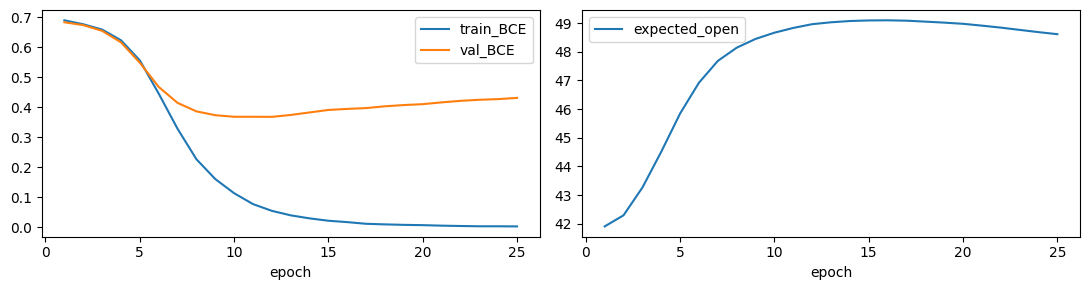

In [8]:
MODEL = train_model(DATA, "MCF7", CONFIG, OUTPUT)

## MCF7: evaluate the selected model
Fixed threshold 0.5. Test evaluation occurs after model selection; do not use it to tune settings.

In [9]:
COMPARISON = evaluate_model(MODEL, DATA, "MCF7", CONFIG, OUTPUT, BASELINE)
COMPARISON.to_csv(OUTPUT/"MCF7_comparison.csv", index=False)
COMPARISONS.append(COMPARISON)
display(COMPARISON)

,cell_line,model,split,AUROC,AUPRC,accuracy,balanced_accuracy,F1,log_loss,Brier
0,MCF7,pathway_MLP,val,0.936108,0.944168,0.869295,0.868769,0.879541,0.391577,0.107004
1,MCF7,pathway_MLP,test,0.955729,0.959066,0.895349,0.895371,0.903374,0.305100,0.081707
2,MCF7,nb08_RNA,test,0.998052,0.998500,0.976744,0.977476,0.978528,0.059447,0.016871
3,MCF7,nb08_ATAC,test,0.878609,0.894355,0.798173,0.795865,0.816327,0.435746,0.140379


## MCF7: validate pathway and modality importance
A positive AUROC drop means performance worsened after removing that representation. RNA/ATAC ablations remove branch latents before fusion; whole-pathway ablation removes its fused representation. No retraining.

MCF7 validation ablations:   0%|          | 0/152 [00:00<?, ?it/s]

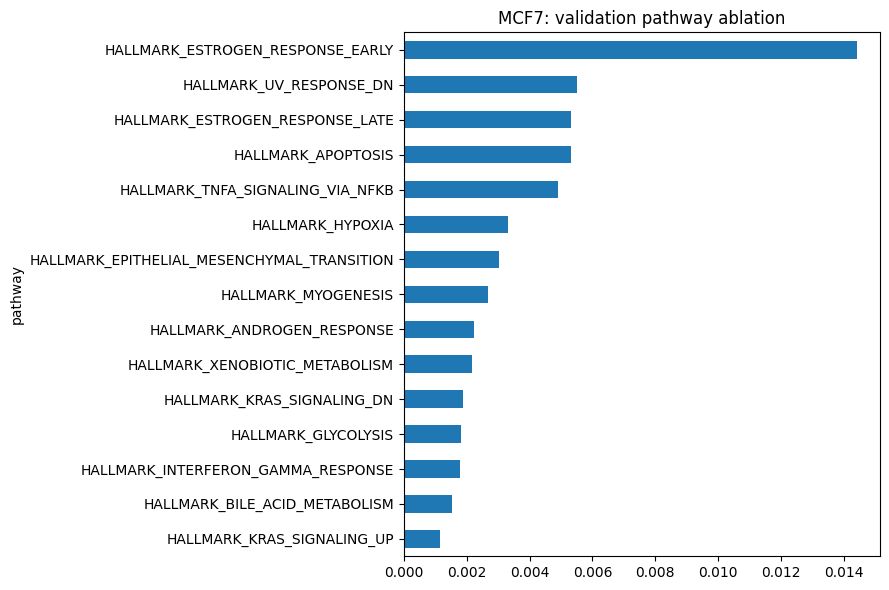

,pathway,branch,baseline_AUROC,ablated_AUROC,AUROC_drop,BCE_increase,mean_absolute_logit_change,mean_signed_logit_change
150,ALL_PATHWAYS,RNA,0.936108,0.607480,0.328628,0.739781,4.394684,-0.730088
36,HALLMARK_ESTROGEN_RESPONSE_EARLY,PATHWAY,0.936108,0.921680,0.014428,0.043130,0.728586,-0.122529
37,HALLMARK_ESTROGEN_RESPONSE_EARLY,RNA,0.936108,0.924076,0.012032,0.039977,0.645539,-0.235889
40,HALLMARK_ESTROGEN_RESPONSE_LATE,RNA,0.936108,0.927045,0.009063,0.012797,0.915227,-0.246177
115,HALLMARK_UV_RESPONSE_DN,RNA,0.936108,0.928486,0.007622,0.018419,0.566795,0.002791
28,HALLMARK_APOPTOSIS,RNA,0.936108,0.928972,0.007136,0.022120,0.469899,-0.100194
114,HALLMARK_UV_RESPONSE_DN,PATHWAY,0.936108,0.930587,0.005521,0.014119,0.613122,-0.007536
39,HALLMARK_ESTROGEN_RESPONSE_LATE,PATHWAY,0.936108,0.930795,0.005313,-0.004325,0.993138,-0.259243
27,HALLMARK_APOPTOSIS,PATHWAY,0.936108,0.930795,0.005313,0.012007,0.485868,-0.016013
0,HALLMARK_TNFA_SIGNALING_VIA_NFKB,PATHWAY,0.936108,0.931194,0.004913,0.022495,0.382029,0.110789


In [10]:
ABLATIONS = pathway_ablation(MODEL, DATA, "MCF7", CONFIG, OUTPUT)
display(ABLATIONS.sort_values("AUROC_drop",ascending=False).head(20))

## MCF7: conditional gene attribution
Attribute the top three pathways with positive validation ablation effects, on up to 16 validation cells per class. Baseline is zero standardized input (training mean). The integrated-gradient completeness error is saved; inspect it before relying on fine gene rankings. Candidate linked ATAC regions are annotations, not region-importance scores.

In [11]:
GENE_ATTRIBUTION = gene_attribution(MODEL, DATA, "MCF7", CONFIG, OUTPUT, ABLATIONS)
if GENE_ATTRIBUTION is not None:
    display(GENE_ATTRIBUTION.sort_values("mean_absolute_IG",ascending=False).head(30))

MCF7 within-pathway attribution:   0%|          | 0/3 [00:00<?, ?it/s]

,pathway,modality,gene,mean_absolute_IG,mean_signed_IG,mean_IG_E2,mean_IG_Vehicle
170,HALLMARK_ESTROGEN_RESPONSE_EARLY,RNA,STC2,85.007462,-20.790882,17.088638,-58.670403
47,HALLMARK_ESTROGEN_RESPONSE_EARLY,RNA,ELF3,81.354614,-26.611811,33.306084,-86.529716
35,HALLMARK_ESTROGEN_RESPONSE_EARLY,RNA,CLDN7,78.054771,-7.331736,13.171013,-27.834486
159,HALLMARK_ESTROGEN_RESPONSE_EARLY,RNA,SLC24A3,77.618408,-15.459160,7.302642,-38.220959
11,HALLMARK_ESTROGEN_RESPONSE_EARLY,RNA,ANXA9,69.382721,-22.969099,-12.503224,-33.434975
732,HALLMARK_APOPTOSIS,RNA,ERBB2,68.042603,-8.459664,-8.406139,-8.513191
18,HALLMARK_ESTROGEN_RESPONSE_EARLY,RNA,BAG1,66.969620,23.890594,13.889318,33.891872
182,HALLMARK_ESTROGEN_RESPONSE_EARLY,RNA,THSD4,66.356232,-4.419518,40.942215,-49.781250
492,HALLMARK_UV_RESPONSE_DN,RNA,PLCB4,62.974388,-18.676836,14.886816,-52.240486
15,HALLMARK_ESTROGEN_RESPONSE_EARLY,RNA,ARL3,60.503822,13.321639,25.631973,1.011303


In [12]:
del MODEL, DATA
gc.collect()
if torch.cuda.is_available(): torch.cuda.empty_cache()

## T47D: prepare pathway features
This step builds the new gene-accessibility features; scMKL kernels are not used. A completed cache is reused on resume.

In [13]:
DATA = prepare_line(BASE, "T47D", MANIFESTS["T47D"], CONFIG, HALLMARK, ANNOTATION, BLACKLIST, OUTPUT, ARTIFACTS)
print("RNA:", DATA["rna"].shape, "ATAC:", DATA["atac"].shape, "pathways:", len(DATA["structure"]["pathways"]))
display(pd.read_csv(OUTPUT/"T47D_pathway_coverage.csv"))

T47D: peak-to-gene annotation:   0%|          | 0/8016 [00:00<?, ?transcript/s]

RNA: (6562, 4027) ATAC: (6562, 4143) pathways: 50


,pathway,RNA_genes,ATAC_genes,retained
0,HALLMARK_TNFA_SIGNALING_VIA_NFKB,187,183,True
1,HALLMARK_HYPOXIA,187,196,True
2,HALLMARK_CHOLESTEROL_HOMEOSTASIS,72,71,True
3,HALLMARK_MITOTIC_SPINDLE,197,196,True
4,HALLMARK_WNT_BETA_CATENIN_SIGNALING,39,41,True
5,HALLMARK_TGF_BETA_SIGNALING,53,54,True
6,HALLMARK_IL6_JAK_STAT3_SIGNALING,78,79,True
7,HALLMARK_DNA_REPAIR,150,147,True
8,HALLMARK_G2M_CHECKPOINT,197,192,True
9,HALLMARK_APOPTOSIS,148,155,True


## T47D: train with tqdm and epoch checkpoints

T47D: training on cuda; tqdm ETA is to the maximum epoch count, before early stopping.


T47D epochs:   0%|          | 0/100 [00:00<?, ?it/s]

epoch 1 batches:   0%|          | 0/37 [00:00<?, ?it/s]

epoch 2 batches:   0%|          | 0/37 [00:00<?, ?it/s]

epoch 3 batches:   0%|          | 0/37 [00:00<?, ?it/s]

...

epoch 21 batches:   0%|          | 0/37 [00:00<?, ?it/s]

epoch 22 batches:   0%|          | 0/37 [00:00<?, ?it/s]

epoch 23 batches:   0%|          | 0/37 [00:00<?, ?it/s]

epoch 24 batches:   0%|          | 0/37 [00:00<?, ?it/s]

epoch 25 batches:   0%|          | 0/37 [00:00<?, ?it/s]

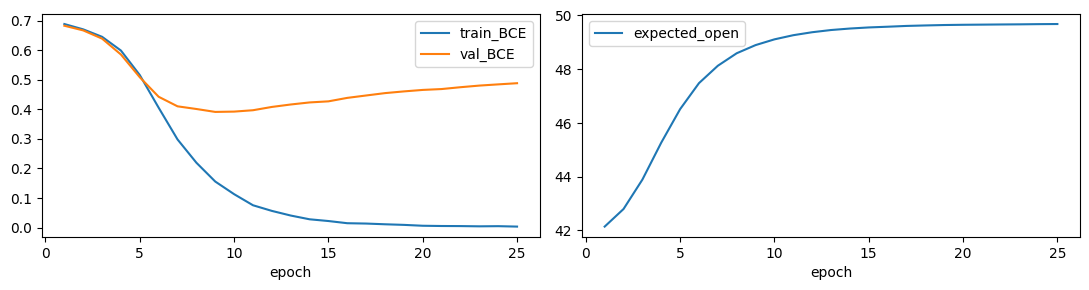

In [14]:
MODEL = train_model(DATA, "T47D", CONFIG, OUTPUT)

## T47D: evaluate the selected model
Fixed threshold 0.5. Test evaluation occurs after model selection; do not use it to tune settings.

In [15]:
COMPARISON = evaluate_model(MODEL, DATA, "T47D", CONFIG, OUTPUT, BASELINE)
COMPARISON.to_csv(OUTPUT/"T47D_comparison.csv", index=False)
COMPARISONS.append(COMPARISON)
display(COMPARISON)

,cell_line,model,split,AUROC,AUPRC,accuracy,balanced_accuracy,F1,log_loss,Brier
0,T47D,pathway_MLP,val,0.924708,0.931492,0.841905,0.839912,0.855652,0.427228,0.118169
1,T47D,pathway_MLP,test,0.922929,0.933138,0.840061,0.838603,0.853147,0.447323,0.122411
2,T47D,nb08_RNA,test,0.996933,0.997737,0.974105,0.973384,0.976290,0.072442,0.019764
3,T47D,nb08_ATAC,test,0.843777,0.852236,0.760091,0.751896,0.793171,0.504845,0.163584


## T47D: validate pathway and modality importance
A positive AUROC drop means performance worsened after removing that representation. RNA/ATAC ablations remove branch latents before fusion; whole-pathway ablation removes its fused representation. No retraining.

T47D validation ablations:   0%|          | 0/152 [00:00<?, ?it/s]

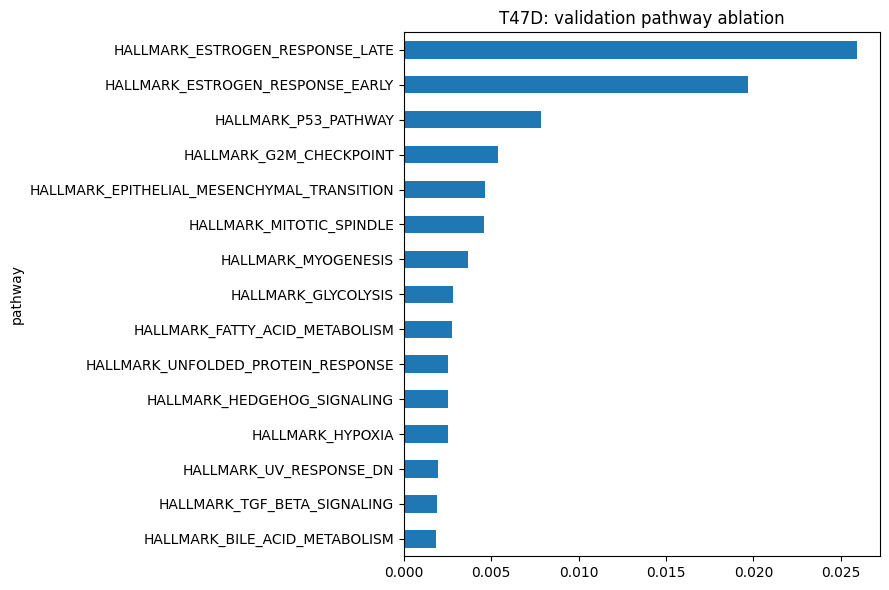

,pathway,branch,baseline_AUROC,ablated_AUROC,AUROC_drop,BCE_increase,mean_absolute_logit_change,mean_signed_logit_change
150,ALL_PATHWAYS,RNA,0.924708,0.597997,0.326711,0.817831,4.181504,-0.857559
40,HALLMARK_ESTROGEN_RESPONSE_LATE,RNA,0.924708,0.897661,0.027047,0.103119,1.072514,-0.573462
39,HALLMARK_ESTROGEN_RESPONSE_LATE,PATHWAY,0.924708,0.898757,0.025950,0.081856,1.124450,-0.094396
37,HALLMARK_ESTROGEN_RESPONSE_EARLY,RNA,0.924708,0.901023,0.023684,0.091147,0.849756,-0.257155
36,HALLMARK_ESTROGEN_RESPONSE_EARLY,PATHWAY,0.924708,0.905000,0.019708,0.066272,0.847591,-0.180828
109,HALLMARK_P53_PATHWAY,RNA,0.924708,0.914094,0.010614,0.032782,0.732903,0.203124
108,HALLMARK_P53_PATHWAY,PATHWAY,0.924708,0.916886,0.007822,0.022933,0.708034,0.212937
10,HALLMARK_MITOTIC_SPINDLE,RNA,0.924708,0.919225,0.005482,0.020208,0.584797,-0.184030
24,HALLMARK_G2M_CHECKPOINT,PATHWAY,0.924708,0.919298,0.005409,0.010097,0.584022,-0.099824
87,HALLMARK_EPITHELIAL_MESENCHYMAL_TRANSITION,PATHWAY,0.924708,0.920088,0.004620,0.017975,0.488584,-0.060392


In [16]:
ABLATIONS = pathway_ablation(MODEL, DATA, "T47D", CONFIG, OUTPUT)
display(ABLATIONS.sort_values("AUROC_drop",ascending=False).head(20))

## T47D: conditional gene attribution
Attribute the top three pathways with positive validation ablation effects, on up to 16 validation cells per class. Baseline is zero standardized input (training mean). The integrated-gradient completeness error is saved; inspect it before relying on fine gene rankings. Candidate linked ATAC regions are annotations, not region-importance scores.

In [17]:
GENE_ATTRIBUTION = gene_attribution(MODEL, DATA, "T47D", CONFIG, OUTPUT, ABLATIONS)
if GENE_ATTRIBUTION is not None:
    display(GENE_ATTRIBUTION.sort_values("mean_absolute_IG",ascending=False).head(30))

T47D within-pathway attribution:   0%|          | 0/3 [00:00<?, ?it/s]

,pathway,modality,gene,mean_absolute_IG,mean_signed_IG,mean_IG_E2,mean_IG_Vehicle
564,HALLMARK_ESTROGEN_RESPONSE_EARLY,RNA,SNX24,109.549835,-15.169209,24.941963,-55.280380
576,HALLMARK_ESTROGEN_RESPONSE_EARLY,RNA,TGIF2,109.362686,17.866003,66.406296,-30.674278
177,HALLMARK_ESTROGEN_RESPONSE_LATE,RNA,TFF1,100.927338,2.896910,74.131393,-68.337570
28,HALLMARK_ESTROGEN_RESPONSE_LATE,RNA,CD44,98.959503,13.267118,20.201769,6.332467
137,HALLMARK_ESTROGEN_RESPONSE_LATE,RNA,PRSS23,93.590164,-18.065502,-4.903355,-31.227650
45,HALLMARK_ESTROGEN_RESPONSE_LATE,RNA,DCXR,87.671425,1.811203,7.800548,-4.178141
68,HALLMARK_ESTROGEN_RESPONSE_LATE,RNA,GAL,86.305199,51.963200,100.010391,3.916013
194,HALLMARK_ESTROGEN_RESPONSE_LATE,RNA,UNC13B,85.751266,15.352331,27.131516,3.573144
439,HALLMARK_ESTROGEN_RESPONSE_EARLY,RNA,DLC1,83.773483,-5.848403,39.583126,-51.279930
168,HALLMARK_ESTROGEN_RESPONSE_LATE,RNA,SLC9A3R1,81.339203,-4.590219,26.077944,-35.258381


In [18]:
del MODEL, DATA
gc.collect()
if torch.cuda.is_available(): torch.cuda.empty_cache()

## Export results for review
The ZIP includes results, mapping tables, settings and figures. Model weights and prepared matrices stay in the persistent artifact folder and are excluded from the ZIP.

In [19]:
COMPARISON = pd.concat(COMPARISONS, ignore_index=True)
COMPARISON.to_csv(OUTPUT/"model_comparison.csv", index=False)
display(COMPARISON[COMPARISON["split"].eq("test")])
RESULTS_ZIP = Path(shutil.make_archive(str(OUTPUT.parent/(RUN_ID+"_results")), "zip", root_dir=OUTPUT))
print("Results ZIP:", RESULTS_ZIP)
print("Checkpoint folder:", ARTIFACTS)
print("Send the results ZIP for review. No biological conclusion is assumed in advance.")


,cell_line,model,split,AUROC,AUPRC,accuracy,balanced_accuracy,F1,log_loss,Brier
1,MCF7,pathway_MLP,test,0.955729,0.959066,0.895349,0.895371,0.903374,0.305100,0.081707
2,MCF7,nb08_RNA,test,0.998052,0.998500,0.976744,0.977476,0.978528,0.059447,0.016871
3,MCF7,nb08_ATAC,test,0.878609,0.894355,0.798173,0.795865,0.816327,0.435746,0.140379
5,T47D,pathway_MLP,test,0.922929,0.933138,0.840061,0.838603,0.853147,0.447323,0.122411
6,T47D,nb08_RNA,test,0.996933,0.997737,0.974105,0.973384,0.976290,0.072442,0.019764
7,T47D,nb08_ATAC,test,0.843777,0.852236,0.760091,0.751896,0.793171,0.504845,0.163584


Results ZIP: /content/drive/MyDrive/breast-cancer-multiome-estrogen/results/tables/nb11/20261012T173612_419824Z_results.zip
Checkpoint folder: /content/drive/MyDrive/breast-cancer-multiome-estrogen/data/processed/nb11/20261012T173612_419824Z
Send the results ZIP for review. No biological conclusion is assumed in advance.


## What to review after execution
Compare integration with both nb08 baselines on identical test cells; RNA-only was already strong.
Inspect learning curves, pathway coverage, sparsity and validation ablation before gene rankings.
Compare pathway names with both RNA GSEA directions and all relevant nb06 ATAC mapping scenarios,
including unsupported or discordant evidence. Such agreement uses the same cohort and is exploratory.
Stability across seeds/splits and biological replicate validation remain future work.
